In [1]:
message = "Han, Mitakuyapi!"
print(message)

Han, Mitakuyapi!


In [2]:
# ============================================================
# NOTEBOOK 13 — CELL 1
# ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
# Inventory existing datasets for dissertation map atlas
#
# MAP 7: Sampling lattice
# MAP 5: NDVI through time
# MAP 6: Bare soil / NDBSI
#
# READ-ONLY: Does not change existing files
# ============================================================

from pathlib import Path
import xarray as xr
import rasterio
import geopandas as gpd

# ------------------------------------------------------------
# 1. PROJECT DIRECTORIES
# ------------------------------------------------------------

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

data_dir = project / "data"
output_dir = project / "outputs"
results_dir = project / "results"

print("=" * 70)
print("ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA")
print("DISSERTATION MAP ATLAS — DATA INVENTORY")
print("=" * 70)

print("\nProject:", project)
print("Project exists:", project.exists())

if not project.exists():
    raise FileNotFoundError(
        f"Project directory not found: {project}"
    )

# ------------------------------------------------------------
# 2. FIND NETCDF DATA CUBES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("1. NETCDF DATA CUBES")
print("=" * 70)

nc_files = sorted(project.rglob("*.nc"))

print(f"\nFound {len(nc_files)} NetCDF files.")

for i, path in enumerate(nc_files, 1):

    print(f"\n[{i}] {path.relative_to(project)}")

    try:
        with xr.open_dataset(path) as ds:

            print("  Dimensions:", dict(ds.sizes))
            print("  Variables:", list(ds.data_vars))
            print("  Coordinates:", list(ds.coords))

            if "title" in ds.attrs:
                print("  Title:", ds.attrs["title"])

    except Exception as e:
        print("  Could not inspect:", str(e))

# ------------------------------------------------------------
# 3. FIND EXISTING GEOTIFF RASTERS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("2. GEOTIFF RASTERS")
print("=" * 70)

tif_files = sorted(
    list(project.rglob("*.tif"))
    + list(project.rglob("*.tiff"))
)

print(f"\nFound {len(tif_files)} GeoTIFF files.")

keywords = [
    "ndvi",
    "ndmi",
    "ndbsi",
    "evi",
    "trajectory",
    "vegetation",
    "soil",
    "landsat"
]

relevant_tifs = [
    p for p in tif_files
    if any(
        word in p.name.lower()
        for word in keywords
    )
]

print(
    f"Potentially relevant rasters: "
    f"{len(relevant_tifs)}"
)

for i, path in enumerate(relevant_tifs, 1):

    print(f"\n[{i}] {path.relative_to(project)}")

    try:
        with rasterio.open(path) as src:

            print("  Shape:", (src.height, src.width))
            print("  Bands:", src.count)
            print("  CRS:", src.crs)
            print("  Resolution:", src.res)

    except Exception as e:
        print("  Could not inspect:", str(e))

# ------------------------------------------------------------
# 4. FIND PARCEL AND SAMPLING SHAPEFILES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("3. SPATIAL VECTOR DATA")
print("=" * 70)

shp_files = sorted(project.rglob("*.shp"))

print(f"\nFound {len(shp_files)} shapefiles.")

for i, path in enumerate(shp_files, 1):

    print(f"\n[{i}] {path.relative_to(project)}")

    try:
        gdf = gpd.read_file(path)

        print("  Features:", len(gdf))
        print("  Geometry:", list(gdf.geom_type.unique()))
        print("  CRS:", gdf.crs)

    except Exception as e:
        print("  Could not inspect:", str(e))

# ------------------------------------------------------------
# 5. IDENTIFY LIKELY MAP INPUTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("4. MAP INPUT CANDIDATES")
print("=" * 70)

map_keywords = {
    "MAP 7 — SAMPLING LATTICE": [
        "lattice", "point", "wanzi", "parcel"
    ],
    "MAP 5 — NDVI THROUGH TIME": [
        "ndvi", "2019", "2022", "2023"
    ],
    "MAP 6 — BARE SOIL / NDBSI": [
        "ndbsi", "bare", "soil"
    ]
}

all_files = nc_files + relevant_tifs + shp_files

for map_name, terms in map_keywords.items():

    print(f"\n{map_name}")

    matches = [
        p for p in all_files
        if any(
            term in p.name.lower()
            for term in terms
        )
    ]

    if matches:

        for p in matches[:20]:
            print("  ", p.relative_to(project))

        if len(matches) > 20:
            print(
                f"  ... and {len(matches) - 20} more"
            )

    else:
        print("  No matching filenames found.")

# ------------------------------------------------------------
# 6. INVENTORY SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("INVENTORY COMPLETE")
print("=" * 70)

print("NetCDF files:", len(nc_files))
print("GeoTIFF files:", len(tif_files))
print("Relevant GeoTIFFs:", len(relevant_tifs))
print("Shapefiles:", len(shp_files))

print("\nNo original datasets were modified.")

ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
DISSERTATION MAP ATLAS — DATA INVENTORY

Project: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube
Project exists: True

1. NETCDF DATA CUBES

Found 14 NetCDF files.

[1] Notebooks/environmental_data_cube_oglala_lakota_2000_2023.nc
  Dimensions: {'year': 24}
  Variables: ['ndvi', 'tmax_k', 'precip_mm', 'evi', 'evi_previous', 'evi_screened', 'evi_valid_composites', 'evi_low_coverage_composites']
  Coordinates: ['year']
  Title: Environmental Data Cube for Oglala Lakota

[2] Notebooks/environmental_data_cube_oglala_lakota_dissertation.nc
  Dimensions: {'year': 3}
  Variables: ['landsat_parcel_ndvi', 'landsat_parcel_ndmi', 'reservation_evi', 'growing_precip_mm', 'growing_tmax_c', 'parcel_pixel_count']
  Coordinates: ['year']
  Title: Environmental Data Cube for Oglala Lakota

[3] data/cache/environmental_data_cube_oglala_lakota_2000_2023_validated_evi_v2.nc
  Dimensions: {'year': 24}
  Variables: ['ndvi', 'tm

In [8]:

# ============================================================
# NOTEBOOK 13 — CELL 2 (CORRECTED)
# Environmental Data Cube for Oglala Lakota
#
# Verify:
# 1. Ate_Macoke parcel
# 2. Existing 2019 NDBSI raster
# 3. Spatial NDVI data cube
# 4. Original sampling lattice files
#
# READ-ONLY — Original data remain unchanged
# ============================================================

from pathlib import Path
import numpy as np
import xarray as xr
import rasterio
import geopandas as gpd

from shapely.geometry import box
from rasterio.mask import mask

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

parcel_path = project / "data/ate_parcel_wanzi.shp"

ndbsi_path = (
    project
    / "data/cache/ndbsi_comparison_2019_2023"
    / "pine_ridge_ndbsi_2019.tif"
)

spatial_cube_path = (
    project
    / "data/cache/spatial_grid_0.5deg_2000_2023.nc"
)

print("=" * 65)
print("NOTEBOOK 13 — SPATIAL DATA VERIFICATION")
print("=" * 65)

# ------------------------------------------------------------
# 2. PARCEL GEOMETRY
# ------------------------------------------------------------

parcel = gpd.read_file(parcel_path)
parcel_utm = parcel.to_crs("EPSG:32613")

print("\n1. ATE_MACOKE PARCEL")
print("-" * 45)

print("Features:", len(parcel))
print("Original CRS:", parcel.crs)
print("Projected CRS:", parcel_utm.crs)
print("Bounds (UTM):", parcel_utm.total_bounds)

parcel_area_ha = (
    parcel_utm.geometry.area.sum() / 10000
)

print(f"Parcel area: {parcel_area_ha:.2f} hectares")

# ------------------------------------------------------------
# 3. CHECK NDBSI RASTER COVERAGE
# ------------------------------------------------------------

print("\n2. NDBSI RASTER COVERAGE")
print("-" * 45)

with rasterio.open(ndbsi_path) as src:

    print("Raster:", ndbsi_path.name)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Dimensions:", src.width, "x", src.height)
    print("NoData:", src.nodata)
    print("Raster bounds:", src.bounds)

    # Reproject parcel to match the raster.
    parcel_raster_crs = parcel.to_crs(src.crs)

    # The parcel shapefile contains one polygon.
    parcel_geometry = parcel_raster_crs.geometry.iloc[0]

    # Create raster footprint.
    raster_footprint = box(*src.bounds)

    # Calculate geographic overlap.
    intersection = parcel_geometry.intersection(
        raster_footprint
    )

    parcel_area = parcel_geometry.area

    coverage_pct = (
        100 * intersection.area / parcel_area
        if parcel_area > 0 else 0
    )

    print(
        f"Parcel footprint coverage: "
        f"{coverage_pct:.2f}%"
    )

    # Check actual valid raster pixels.
    if intersection.is_empty:

        print("No overlap with Ate_Macoke.")

    else:

        clipped, clipped_transform = mask(
            src,
            [parcel_geometry],
            crop=True,
            filled=False
        )

        band = clipped[0]
        valid = band.compressed()

        print(
            "Valid raster pixels inside parcel:",
            len(valid)
        )

        if len(valid) > 0:

            print("NDBSI minimum:", float(np.min(valid)))
            print("NDBSI maximum:", float(np.max(valid)))
            print("NDBSI mean:", float(np.mean(valid)))

        else:

            print(
                "Raster footprint overlaps the parcel, "
                "but no valid NDBSI pixels were found."
            )

# ------------------------------------------------------------
# 4. INSPECT SPATIAL NDVI CUBE
# ------------------------------------------------------------

print("\n3. SPATIAL NDVI CUBE")
print("-" * 45)

with xr.open_dataset(spatial_cube_path) as ds:

    print("Title:", ds.attrs.get("title"))
    print("Dimensions:", dict(ds.sizes))
    print("Variables:", list(ds.data_vars))

    print("\nLatitude coordinates:")
    print(ds["lat"].values)

    print("\nLongitude coordinates:")
    print(ds["lon"].values)

    print("\nYears:")
    print(ds["year"].values)

    print("\nNDVI attributes:")
    print(ds["ndvi"].attrs)

    print("\nDataset attributes:")
    print(ds.attrs)

# ------------------------------------------------------------
# 5. SEARCH FOR ORIGINAL SAMPLING LATTICE
# ------------------------------------------------------------

print("\n4. SEARCH FOR SAMPLING LATTICE")
print("-" * 45)

workspace = project.parent

extensions = {
    ".nc",
    ".csv",
    ".geojson",
    ".gpkg",
    ".parquet",
    ".json",
    ".shp"
}

search_terms = [
    "lattice",
    "sampling",
    "15pts",
    "15_points",
    "wanzi",
    "point_grid"
]

matches = []

for path in workspace.rglob("*"):

    if not path.is_file():
        continue

    if path.suffix.lower() not in extensions:
        continue

    if any(
        term in path.name.lower()
        for term in search_terms
    ):
        matches.append(path)

print(f"Candidate sampling files: {len(matches)}")

for path in sorted(matches)[:60]:
    print(path.relative_to(workspace))

if len(matches) > 60:
    print(f"... plus {len(matches) - 60} more")

# ------------------------------------------------------------
# 6. SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("SPATIAL VERIFICATION COMPLETE")
print("=" * 65)

print("Parcel area:", round(parcel_area_ha, 2), "ha")
print("NDBSI footprint coverage:", round(coverage_pct, 2), "%")
print("Sampling file candidates:", len(matches))

print("\nOriginal datasets remain unchanged.")


NOTEBOOK 13 — SPATIAL DATA VERIFICATION

1. ATE_MACOKE PARCEL
---------------------------------------------
Features: 1
Original CRS: EPSG:26913
Projected CRS: EPSG:32613
Bounds (UTM): [ 756775.682698   4825052.1363182   758467.41689798 4826717.33901822]
Parcel area: 258.82 hectares

2. NDBSI RASTER COVERAGE
---------------------------------------------
Raster: pine_ridge_ndbsi_2019.tif
CRS: EPSG:32613
Resolution: (30.0, 30.0)
Dimensions: 4872 x 3129
NoData: None
Raster bounds: BoundingBox(left=661320.0, bottom=4762260.0, right=807480.0, top=4856130.0)
Parcel footprint coverage: 100.00%
Valid raster pixels inside parcel: 2878
NDBSI minimum: 0.3100706934928894
NDBSI maximum: 0.8132505416870117
NDBSI mean: 0.6376938819885254

3. SPATIAL NDVI CUBE
---------------------------------------------
Title: Pine Ridge Spatial NDVI Cube
Dimensions: {'year': 24, 'lat': 3, 'lon': 4}
Variables: ['ndvi']

Latitude coordinates:
[43.  43.5 44. ]

Longitude coordinates:
[-103.  -102.5 -102.  -101.5]

Yea

In [9]:

# ============================================================
# NOTEBOOK 13 — CELL 3
# ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
#
# MAP 7 — ORIGINAL 15-POINT SAMPLING LATTICE
#
# Read original NetCDF, inspect coordinates,
# verify sampling points against Ate_Macoke.
#
# READ-ONLY — No original files modified
# ============================================================

from pathlib import Path
import numpy as np
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

workspace = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026"
)

project = workspace / "ate_makoce_agcube"

lattice_path = (
    workspace
    / "datacube_tutorial_eyt_broken"
    / "data/cache/ndvi_lattice_Wanzi_15pts_2015_2023.nc"
)

parcel_path = project / "data/ate_parcel_wanzi.shp"

print("=" * 65)
print("MAP 7 — ORIGINAL SAMPLING LATTICE")
print("=" * 65)

# ------------------------------------------------------------
# 2. LOAD ORIGINAL LATTICE
# ------------------------------------------------------------

if not lattice_path.exists():
    raise FileNotFoundError(
        f"Sampling lattice not found:\n{lattice_path}"
    )

with xr.open_dataset(lattice_path) as ds:
    lattice = ds.load()

print("\nDataset:")
print(lattice)

print("\nDataset attributes:")
for key, value in lattice.attrs.items():
    print(f"  {key}: {value}")

print("\nCoordinates:")
print(list(lattice.coords))

print("\nVariables:")
print(list(lattice.data_vars))

# ------------------------------------------------------------
# 3. IDENTIFY LATITUDE AND LONGITUDE
# ------------------------------------------------------------

def find_coordinate(dataset, names):

    for name in names:
        if name in dataset.coords:
            return dataset.coords[name]

        if name in dataset.data_vars:
            return dataset[name]

    raise KeyError(
        f"Could not find any of: {names}"
    )

latitude = find_coordinate(
    lattice,
    ["lat", "latitude", "y_lat"]
)

longitude = find_coordinate(
    lattice,
    ["lon", "longitude", "x_lon"]
)

lat_values = np.asarray(latitude.values).ravel()
lon_values = np.asarray(longitude.values).ravel()

if len(lat_values) != len(lon_values):
    raise ValueError(
        "Latitude and longitude counts do not match."
    )

if not np.all(
    np.isfinite(lat_values) & np.isfinite(lon_values)
):
    raise ValueError(
        "Sampling coordinates contain invalid values."
    )

print("\nSampling points:", len(lat_values))

if len(lat_values) != 15:
    print(
        "WARNING: Expected 15 sampling points, "
        f"found {len(lat_values)}."
    )

# ------------------------------------------------------------
# 4. CREATE GEOSPATIAL POINTS
# ------------------------------------------------------------

points = gpd.GeoDataFrame(
    {
        "point_id": np.arange(
            1, len(lat_values) + 1
        ),
        "latitude": lat_values,
        "longitude": lon_values
    },
    geometry=gpd.points_from_xy(
        lon_values,
        lat_values
    ),
    crs="EPSG:4326"
)

parcel = gpd.read_file(parcel_path)

points_utm = points.to_crs("EPSG:32613")
parcel_utm = parcel.to_crs("EPSG:32613")

# ------------------------------------------------------------
# 5. VERIFY POINTS AGAINST PARCEL
# ------------------------------------------------------------

parcel_geometry = parcel_utm.geometry.iloc[0]

points_utm["inside_parcel"] = (
    points_utm.geometry.apply(
        lambda geom: parcel_geometry.covers(geom)
    )
)

inside_count = int(
    points_utm["inside_parcel"].sum()
)

outside_count = (
    len(points_utm) - inside_count
)

print("\n" + "-" * 65)
print("SPATIAL VERIFICATION")
print("-" * 65)

print("Total sampling points:", len(points_utm))
print("Inside/on Ate_Macoke boundary:", inside_count)
print("Outside Ate_Macoke:", outside_count)

print("\nSampling coordinates:")

print(
    points_utm[
        [
            "point_id",
            "latitude",
            "longitude",
            "inside_parcel"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 6. PREVIEW ORIGINAL SAMPLING LOCATIONS
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 9),
    facecolor="white"
)

parcel_utm.plot(
    ax=ax,
    facecolor="#EDF4EE",
    edgecolor="#18384A",
    linewidth=2
)

points_utm.plot(
    ax=ax,
    color="#E76A44",
    edgecolor="white",
    linewidth=1.2,
    markersize=95,
    zorder=4
)

for _, point in points_utm.iterrows():

    ax.annotate(
        str(point["point_id"]),
        (
            point.geometry.x,
            point.geometry.y
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold",
        color="#18384A"
    )

ax.set_title(
    "Environmental Data Cube for Oglala Lakota\n"
    "Original 15-Point Sampling Lattice",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("UTM Easting (m)")
ax.set_ylabel("UTM Northing (m)")
ax.set_aspect("equal")

ax.grid(
    alpha=0.15,
    linestyle="--"
)

plt.tight_layout()
plt.show()

print("\n" + "=" * 65)
print("MAP 7 — SAMPLING LATTICE INSPECTION COMPLETE")
print("=" * 65)

print("Original NetCDF unchanged.")
print("Original parcel shapefile unchanged.")


MAP 7 — ORIGINAL SAMPLING LATTICE

Dataset:
<xarray.Dataset> Size: 2kB
Dimensions:  (year: 9, point: 15)
Coordinates:
  * year     (year) int64 72B 2015 2016 2017 2018 2019 2020 2021 2022 2023
  * point    (point) int64 120B 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15
    lat      (point) float64 120B 43.53 43.53 43.53 43.53 ... 43.55 43.55 43.55
    lon      (point) float64 120B -101.8 -101.8 -101.8 ... -101.8 -101.8 -101.8
Data variables:
    ndvi     (year, point) float64 1kB 0.4238 0.5276 0.5262 ... nan nan nan
Attributes:
    title:           Wanzi Lattice NDVI Cube
    location:        Wanzi
    shapefile:       ate_parcel_wanzi.shp
    fetch_mode:      interior
    n_points:        15
    period:          2015-2023
    growing_months:  [5, 6, 7, 8, 9]
    tk_community:    Oglala Lakota Nation
    crs:             EPSG:4326

Dataset attributes:
  title: Wanzi Lattice NDVI Cube
  location: Wanzi
  shapefile: ate_parcel_wanzi.shp
  fetch_mode: interior
  n_points: 15
  period: 2015-2023
  

<Figure size 900x900 with 1 Axes>


MAP 7 — SAMPLING LATTICE INSPECTION COMPLETE
Original NetCDF unchanged.
Original parcel shapefile unchanged.


Satellite RGB not available in Notebook 13.
The sampling map will use a neutral background.
To include Landsat imagery, we will load the saved RGB source or reuse the Cell 10 retrieval.
Verified 15 sampling points.
Saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Original_15_Point_Sampling_Lattice.png
Saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Original_15_Point_Sampling_Lattice.pdf


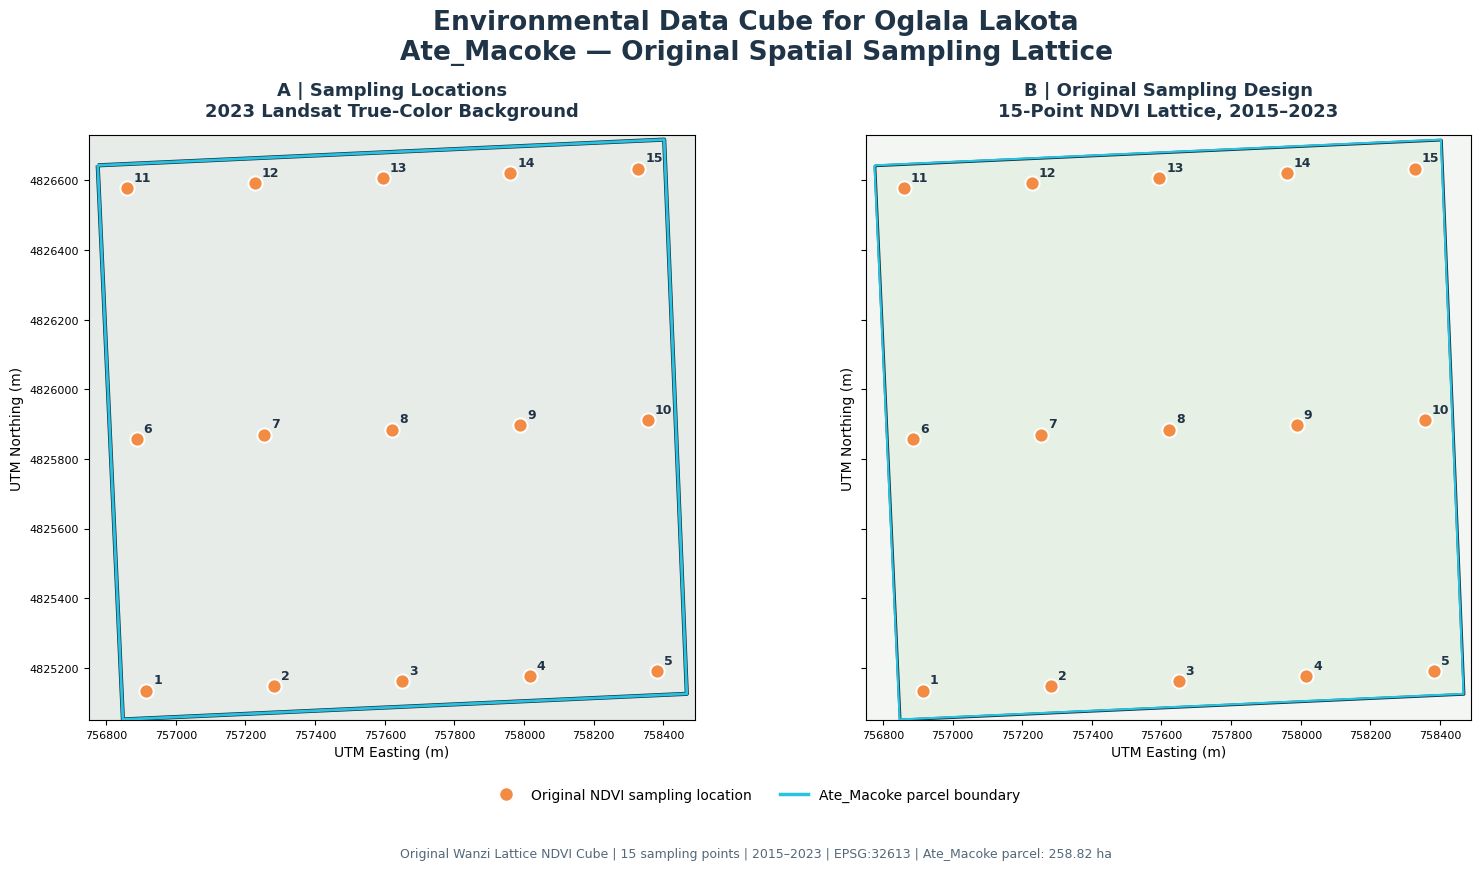


MAP 7 COMPLETE
Original lattice coordinates preserved.
Original NDVI observations unchanged.


In [10]:

# ============================================================
# NOTEBOOK 13 — CELL 4
# ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
#
# MAP 7 — ATE_MACOKE SAMPLING LATTICE
#
# Original 15-point NDVI lattice, 2015–2023
# Parcel boundary and 2023 Landsat true-color background
#
# READ-ONLY SOURCE DATA
# ============================================================

from pathlib import Path
import numpy as np
import xarray as xr
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import ScalarFormatter

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

workspace = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026"
)

project = workspace / "ate_makoce_agcube"

out = project / "results/SA20_satellite_maps"
out.mkdir(parents=True, exist_ok=True)

lattice_path = (
    workspace
    / "datacube_tutorial_eyt_broken"
    / "data/cache/ndvi_lattice_Wanzi_15pts_2015_2023.nc"
)

parcel_path = project / "data/ate_parcel_wanzi.shp"

reference_raster = (
    out / "Ate_Macoke_Three_Class_Vegetation_Trajectories.tif"
)

# ------------------------------------------------------------
# 2. LOAD ORIGINAL SAMPLING POINTS
# ------------------------------------------------------------

with xr.open_dataset(lattice_path) as ds:

    lat = ds["lat"].values.copy()
    lon = ds["lon"].values.copy()
    point_ids = ds["point"].values.copy()

points = gpd.GeoDataFrame(
    {"point_id": point_ids},
    geometry=gpd.points_from_xy(lon, lat),
    crs="EPSG:4326"
)

parcel = gpd.read_file(parcel_path)

# ------------------------------------------------------------
# 3. REFERENCE GEOGRAPHIC EXTENT
# ------------------------------------------------------------

with rasterio.open(reference_raster) as src:

    bounds = src.bounds
    map_crs = src.crs
    raster_shape = (src.height, src.width)

points = points.to_crs(map_crs)
parcel = parcel.to_crs(map_crs)

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]

# ------------------------------------------------------------
# 4. LOAD SATELLITE RGB FROM CURRENT NOTEBOOK
# ------------------------------------------------------------

# Notebook 12 variables are not automatically shared.
# If rgb was not loaded in this kernel, use the
# neutral-background sampling map instead.

satellite_available = (
    "rgb" in globals()
    and isinstance(rgb, np.ndarray)
    and rgb.shape == (*raster_shape, 3)
)

if satellite_available:

    satellite = np.clip(
        np.asarray(rgb, dtype=np.float32),
        0,
        1
    )

    print("Satellite RGB found in current kernel.")

else:

    satellite = None

    print(
        "Satellite RGB not available in Notebook 13.\n"
        "The sampling map will use a neutral background.\n"
        "To include Landsat imagery, we will load the "
        "saved RGB source or reuse the Cell 10 retrieval."
    )

# ------------------------------------------------------------
# 5. VERIFY POINT LOCATIONS
# ------------------------------------------------------------

parcel_geom = parcel.geometry.iloc[0]

inside = points.geometry.apply(parcel_geom.covers)

if not inside.all():
    raise ValueError(
        "Some sampling points fall outside the parcel."
    )

print(f"Verified {len(points)} sampling points.")

# ------------------------------------------------------------
# 6. CARTOGRAPHIC STYLE
# ------------------------------------------------------------

INK = "#203447"
MUTED = "#536879"
CYAN = "#28C2E2"
ORANGE = "#F28C45"

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 9),
    sharex=True,
    sharey=True
)

fig.patch.set_facecolor("white")

# ------------------------------------------------------------
# 7. LEFT PANEL — SATELLITE BACKGROUND
# ------------------------------------------------------------

ax = axes[0]

ax.set_facecolor("#E8ECE8")

if satellite is not None:

    ax.imshow(
        satellite,
        extent=extent,
        origin="upper",
        interpolation="nearest",
        zorder=1
    )

parcel.boundary.plot(
    ax=ax,
    color="#18313D",
    linewidth=3,
    zorder=3
)

parcel.boundary.plot(
    ax=ax,
    color=CYAN,
    linewidth=2,
    zorder=4
)

ax.set_title(
    "A | Sampling Locations\n"
    "2023 Landsat True-Color Background",
    fontsize=13,
    fontweight="bold",
    color=INK,
    pad=14
)

# ------------------------------------------------------------
# 8. RIGHT PANEL — SAMPLING DESIGN
# ------------------------------------------------------------

ax2 = axes[1]

ax2.set_facecolor("#F4F6F3")

parcel.plot(
    ax=ax2,
    facecolor="#E6F0E5",
    edgecolor="#18313D",
    linewidth=2
)

parcel.boundary.plot(
    ax=ax2,
    color=CYAN,
    linewidth=1.5,
    zorder=3
)

ax2.set_title(
    "B | Original Sampling Design\n"
    "15-Point NDVI Lattice, 2015–2023",
    fontsize=13,
    fontweight="bold",
    color=INK,
    pad=14
)

# ------------------------------------------------------------
# 9. PLOT ORIGINAL POINTS ON BOTH MAPS
# ------------------------------------------------------------

for ax in axes:

    points.plot(
        ax=ax,
        color=ORANGE,
        edgecolor="white",
        linewidth=1.4,
        markersize=105,
        zorder=6
    )

    for _, point in points.iterrows():

        ax.annotate(
            str(int(point["point_id"])),
            (
                point.geometry.x,
                point.geometry.y
            ),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=9,
            fontweight="bold",
            color=INK,
            zorder=7
        )

    ax.set_xlim(bounds.left, bounds.right)
    ax.set_ylim(bounds.bottom, bounds.top)
    ax.set_aspect("equal")

    ax.set_xlabel(
        "UTM Easting (m)",
        fontsize=10
    )

    ax.set_ylabel(
        "UTM Northing (m)",
        fontsize=10
    )

    fmt = ScalarFormatter(useOffset=False)
    fmt.set_scientific(False)

    ax.xaxis.set_major_formatter(fmt)
    ax.yaxis.set_major_formatter(fmt)

    ax.tick_params(labelsize=8)

# ------------------------------------------------------------
# 10. MAIN TITLE AND LEGEND
# ------------------------------------------------------------

fig.suptitle(
    "Environmental Data Cube for Oglala Lakota\n"
    "Ate_Macoke — Original Spatial Sampling Lattice",
    fontsize=19,
    fontweight="bold",
    color=INK,
    y=0.97
)

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="none",
        markerfacecolor=ORANGE,
        markeredgecolor="white",
        markersize=10,
        label="Original NDVI sampling location"
    ),
    Line2D(
        [0], [0],
        color=CYAN,
        linewidth=2.5,
        label="Ate_Macoke parcel boundary"
    )
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.075),
    ncol=2,
    frameon=False,
    fontsize=10
)

fig.text(
    0.5,
    0.028,
    "Original Wanzi Lattice NDVI Cube | "
    "15 sampling points | 2015–2023 | "
    "EPSG:32613 | Ate_Macoke parcel: 258.82 ha",
    ha="center",
    fontsize=9,
    color=MUTED
)

plt.subplots_adjust(
    left=0.07,
    right=0.96,
    top=0.83,
    bottom=0.18,
    wspace=0.20
)

# ------------------------------------------------------------
# 11. EXPORT MAP
# ------------------------------------------------------------

base = "Ate_Macoke_Original_15_Point_Sampling_Lattice"

for extension in ["png", "pdf"]:

    path = out / f"{base}.{extension}"
    version = 2

    while path.exists():

        path = out / f"{base}_v{version}.{extension}"
        version += 1

    fig.savefig(
        path,
        dpi=400,
        bbox_inches="tight",
        facecolor="white"
    )

    print("Saved:", path)

plt.show()

print("\nMAP 7 COMPLETE")
print("Original lattice coordinates preserved.")
print("Original NDVI observations unchanged.")


In [13]:

# ============================================================
# NOTEBOOK 12 — SAVE EXISTING LANDSAT RGB
# Reuse the 2023 true-color image in Notebook 13
# No satellite data are downloaded or recalculated.
# ============================================================

from pathlib import Path
import numpy as np
import rasterio

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

out = project / "results/SA20_satellite_maps"
out.mkdir(parents=True, exist_ok=True)

reference_raster = (
    out / "Ate_Macoke_Three_Class_Vegetation_Trajectories.tif"
)

rgb_path = out / "Ate_Macoke_Landsat_2023_TrueColor_RGB.tif"

if "rgb" not in globals():
    raise RuntimeError("Run Notebook 12 Cell 10 first.")

with rasterio.open(reference_raster) as ref:

    if rgb.shape != (ref.height, ref.width, 3):
        raise ValueError("RGB does not match the reference raster.")

    profile = ref.profile.copy()

profile.update(
    driver="GTiff",
    count=3,
    dtype="float32",
    nodata=None,
    compress="deflate",
    photometric="RGB"
)

if rgb_path.exists():
    raise FileExistsError(
        f"RGB export already exists: {rgb_path}\n"
        "Inspect the existing file before replacing it."
    )

with rasterio.open(rgb_path, "w", **profile) as dst:

    for band in range(3):
        dst.write(
            np.asarray(rgb[:, :, band], dtype=np.float32),
            band + 1
        )

    dst.set_band_description(1, "Red — Landsat Band 4")
    dst.set_band_description(2, "Green — Landsat Band 3")
    dst.set_band_description(3, "Blue — Landsat Band 2")

    dst.update_tags(
        title="Ate_Macoke 2023 Landsat True-Color RGB",
        source="Notebook 12, Cell 10",
        processing="Previously generated display RGB",
        note="Display composite, not original reflectance bands"
    )

print("Saved:", rgb_path)
print("Shape:", rgb.shape)
print("Original NDVI/NDMI data unchanged.")


RuntimeError: Run Notebook 12 Cell 10 first.

FOUND: Ate_Macoke parcel
FOUND: 2023 Landsat RGB
FOUND: Original 15-point lattice

LANDSAT RGB
Shape: (56, 58, 3)
CRS: EPSG:32613
Resolution: (30.0, 30.0)

ATE_MACOKE PARCEL
Area (hectares): 258.82

ORIGINAL LATTICE DATASET
<xarray.Dataset> Size: 2kB
Dimensions:  (year: 9, point: 15)
Coordinates:
  * year     (year) int64 72B 2015 2016 2017 2018 2019 2020 2021 2022 2023
  * point    (point) int64 120B 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15
    lat      (point) float64 120B ...
    lon      (point) float64 120B ...
Data variables:
    ndvi     (year, point) float64 1kB ...
Attributes:
    title:           Wanzi Lattice NDVI Cube
    location:        Wanzi
    shapefile:       ate_parcel_wanzi.shp
    fetch_mode:      interior
    n_points:        15
    period:          2015-2023
    growing_months:  [5, 6, 7, 8, 9]
    tk_community:    Oglala Lakota Nation
    crs:             EPSG:4326

SAMPLING LATTICE VERIFICATION
Total original points: 15
Points inside parcel: 15


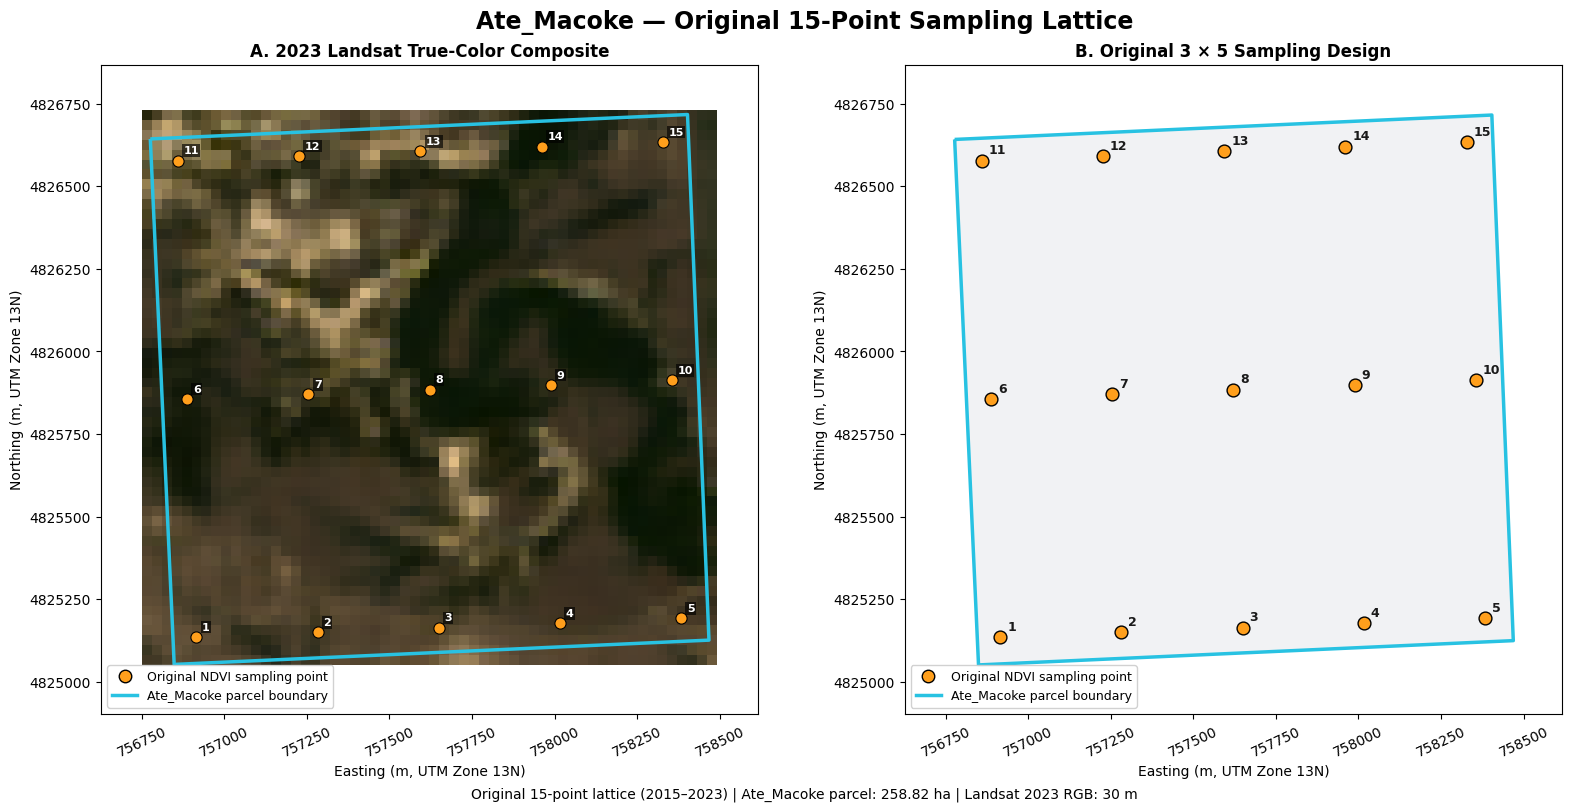


MAP 7 — COMPLETED
Study parcel: Ate_Macoke
Original sampling points: 15
Points inside parcel: 15
Parcel area (ha): 258.82
RGB shape: (56, 58, 3)
Coordinate system: EPSG:32613

SAVED MAP FILES
PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Original_15_Point_Sampling_Lattice_RGB.png
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Original_15_Point_Sampling_Lattice_RGB.pdf

Original data cube and source rasters unchanged.


In [15]:
# ================================================================
# MAP 7 — ATE_MACOKE ORIGINAL 15-POINT SAMPLING LATTICE
# Environmental Data Cube for Oglala Lakota
#
# LEFT:  2023 Landsat True-Color + Original Sampling Points
# RIGHT: Ate_Macoke Parcel + Original 3 x 5 Sampling Lattice
#
# Uses existing research data — no satellite downloads,
# no NDVI recalculation, no changes to original data files.
# ================================================================

from pathlib import Path
import numpy as np
import xarray as xr
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

from rasterio.plot import plotting_extent
from matplotlib.lines import Line2D
from pyproj import Transformer


# ================================================================
# 1. PROJECT PATHS
# ================================================================

workspace = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
)

project = workspace / "ate_makoce_agcube"

out = project / "results" / "SA20_satellite_maps"
out.mkdir(parents=True, exist_ok=True)

parcel_path = project / "data" / "ate_parcel_wanzi.shp"

rgb_path = (
    out / "Ate_Macoke_Landsat_2023_TrueColor_RGB.tif"
)

lattice_path = (
    workspace
    / "datacube_tutorial_eyt_broken"
    / "data"
    / "cache"
    / "ndvi_lattice_Wanzi_15pts_2015_2023.nc"
)


# ================================================================
# 2. VERIFY INPUT FILES
# ================================================================

required_files = {
    "Ate_Macoke parcel": parcel_path,
    "2023 Landsat RGB": rgb_path,
    "Original 15-point lattice": lattice_path
}

for label, path in required_files.items():

    if not path.exists():
        raise FileNotFoundError(
            f"{label} not found:\n{path}"
        )

    print(f"FOUND: {label}")


# ================================================================
# 3. LOAD ATE_MACOKE PARCEL
# ================================================================

parcel = gpd.read_file(parcel_path)

if parcel.empty:
    raise ValueError("Parcel shapefile contains no features.")

if parcel.crs is None:
    raise ValueError("Parcel shapefile has no defined CRS.")


# ================================================================
# 4. LOAD SAVED LANDSAT RGB
# ================================================================

with rasterio.open(rgb_path) as src:

    rgb = np.moveaxis(
        src.read([1, 2, 3]),
        0,
        -1
    ).astype("float32")

    rgb_extent = plotting_extent(src)

    rgb_crs = src.crs
    rgb_resolution = src.res

    rgb_bounds = src.bounds

if rgb_crs is None:
    raise ValueError("RGB GeoTIFF has no CRS.")

rgb = np.nan_to_num(
    rgb,
    nan=0.0,
    posinf=1.0,
    neginf=0.0
)

rgb = np.clip(rgb, 0, 1)

print("\nLANDSAT RGB")
print("Shape:", rgb.shape)
print("CRS:", rgb_crs)
print("Resolution:", rgb_resolution)


# ================================================================
# 5. TRANSFORM PARCEL TO LANDSAT CRS
# ================================================================

parcel_utm = parcel.to_crs(rgb_crs)

parcel_geometry = parcel_utm.geometry.iloc[0]

parcel_area_ha = (
    parcel_utm.geometry.area.sum() / 10000
)

print("\nATE_MACOKE PARCEL")
print("Area (hectares):", round(parcel_area_ha, 2))


# ================================================================
# 6. LOAD ORIGINAL 15-POINT SAMPLING LATTICE
# ================================================================

with xr.open_dataset(lattice_path) as ds:

    print("\nORIGINAL LATTICE DATASET")
    print(ds)

    if "lat" not in ds.coords or "lon" not in ds.coords:
        raise ValueError(
            "Original lattice requires lat and lon coordinates."
        )

    latitudes = ds["lat"].values.copy()
    longitudes = ds["lon"].values.copy()

    if "point" in ds.coords:
        point_ids = ds["point"].values.copy()
    else:
        point_ids = np.arange(1, len(latitudes) + 1)


if len(latitudes) != 15:
    raise ValueError(
        f"Expected 15 original points, found {len(latitudes)}."
    )


# ================================================================
# 7. CONVERT ORIGINAL POINTS TO UTM
# ================================================================

transformer = Transformer.from_crs(
    "EPSG:4326",
    rgb_crs,
    always_xy=True
)

point_x, point_y = transformer.transform(
    longitudes,
    latitudes
)

points = gpd.GeoDataFrame(
    {
        "point_id": point_ids
    },
    geometry=gpd.points_from_xy(
        point_x,
        point_y
    ),
    crs=rgb_crs
)


# ================================================================
# 8. VERIFY ALL 15 POINTS FALL INSIDE THE PARCEL
# ================================================================

inside = points.geometry.apply(
    lambda p: parcel_geometry.covers(p)
)

n_inside = int(inside.sum())

print("\nSAMPLING LATTICE VERIFICATION")
print("Total original points:", len(points))
print("Points inside parcel:", n_inside)

if n_inside != 15:
    raise ValueError(
        "Not all original sampling points fall inside "
        "the Ate_Macoke parcel."
    )


# ================================================================
# 9. MAP EXTENT
# ================================================================

xmin, ymin, xmax, ymax = parcel_utm.total_bounds

padding = 150

map_extent = [
    xmin - padding,
    xmax + padding,
    ymin - padding,
    ymax + padding
]


# ================================================================
# 10. CREATE TWO-PANEL DISSERTATION MAP
# ================================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 8),
    constrained_layout=True
)

fig.suptitle(
    "Ate_Macoke — Original 15-Point Sampling Lattice",
    fontsize=17,
    fontweight="bold"
)


# ------------------------------------------------
# LEFT PANEL — LANDSAT TRUE-COLOR
# ------------------------------------------------

ax = axes[0]

ax.imshow(
    rgb,
    extent=rgb_extent,
    origin="upper",
    interpolation="nearest",
    zorder=1
)

parcel_utm.boundary.plot(
    ax=ax,
    color="#28C2E2",
    linewidth=2.5,
    zorder=3
)

points.plot(
    ax=ax,
    color="#FF9F1C",
    edgecolor="black",
    markersize=65,
    linewidth=0.8,
    zorder=4
)

for _, row in points.iterrows():

    ax.annotate(
        str(row["point_id"]),
        xy=(row.geometry.x, row.geometry.y),
        xytext=(4, 5),
        textcoords="offset points",
        fontsize=8,
        fontweight="bold",
        color="white",
        bbox=dict(
            facecolor="black",
            alpha=0.65,
            edgecolor="none",
            pad=1
        ),
        zorder=5
    )

ax.set_title(
    "A. 2023 Landsat True-Color Composite",
    fontsize=12,
    fontweight="bold"
)

ax.set_xlim(map_extent[0], map_extent[1])
ax.set_ylim(map_extent[2], map_extent[3])

ax.set_xlabel("Easting (m, UTM Zone 13N)")
ax.set_ylabel("Northing (m, UTM Zone 13N)")

ax.set_aspect("equal")


# ------------------------------------------------
# RIGHT PANEL — ORIGINAL SAMPLING DESIGN
# ------------------------------------------------

ax = axes[1]

parcel_utm.plot(
    ax=ax,
    facecolor="#F1F2F4",
    edgecolor="#28C2E2",
    linewidth=2.5,
    zorder=1
)

points.plot(
    ax=ax,
    color="#FF9F1C",
    edgecolor="black",
    markersize=85,
    linewidth=1,
    zorder=3
)

for _, row in points.iterrows():

    ax.annotate(
        str(row["point_id"]),
        xy=(row.geometry.x, row.geometry.y),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold",
        color="#1A1A1A",
        zorder=4
    )

ax.set_title(
    "B. Original 3 × 5 Sampling Design",
    fontsize=12,
    fontweight="bold"
)

ax.set_xlim(map_extent[0], map_extent[1])
ax.set_ylim(map_extent[2], map_extent[3])

ax.set_xlabel("Easting (m, UTM Zone 13N)")
ax.set_ylabel("Northing (m, UTM Zone 13N)")

ax.set_aspect("equal")


# ================================================================
# 11. LEGEND
# ================================================================

legend_elements = [

    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor="#FF9F1C",
        markeredgecolor="black",
        markersize=9,
        label="Original NDVI sampling point"
    ),

    Line2D(
        [0], [0],
        color="#28C2E2",
        linewidth=2.5,
        label="Ate_Macoke parcel boundary"
    )
]

for ax in axes:

    ax.legend(
        handles=legend_elements,
        loc="lower left",
        fontsize=9,
        framealpha=0.9
    )

    ax.ticklabel_format(
        style="plain",
        useOffset=False
    )

    ax.tick_params(
        axis="x",
        labelrotation=25
    )


# ================================================================
# 12. FIGURE CAPTION
# ================================================================

fig.supxlabel(
    (
        "Original 15-point lattice (2015–2023) | "
        f"Ate_Macoke parcel: {parcel_area_ha:.2f} ha | "
        "Landsat 2023 RGB: 30 m"
    ),
    fontsize=10
)


# ================================================================
# 13. SAVE PNG AND PDF
# ================================================================

png_path = (
    out / "Ate_Macoke_Original_15_Point_Sampling_Lattice_RGB.png"
)

pdf_path = (
    out / "Ate_Macoke_Original_15_Point_Sampling_Lattice_RGB.pdf"
)

# Save to distinct filenames, leaving previous maps untouched.

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# ================================================================
# 14. FINAL VERIFICATION
# ================================================================

print("\n" + "=" * 60)
print("MAP 7 — COMPLETED")
print("=" * 60)

print("Study parcel: Ate_Macoke")
print("Original sampling points:", len(points))
print("Points inside parcel:", n_inside)
print("Parcel area (ha):", round(parcel_area_ha, 2))
print("RGB shape:", rgb.shape)
print("Coordinate system:", rgb_crs)

print("\nSAVED MAP FILES")
print("PNG:", png_path)
print("PDF:", pdf_path)

print("\nOriginal data cube and source rasters unchanged.")

In [16]:

# ============================================================
# MAP 5 — INVENTORY EXISTING SPATIAL NDVI DATA
# Environmental Data Cube for Oglala Lakota
# Years: 2019, 2022, 2023
#
# READ ONLY — DOES NOT CHANGE ORIGINAL DATA
# ============================================================

from pathlib import Path
import rasterio
import xarray as xr

workspace = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
)

project = workspace / "ate_makoce_agcube"

years = ("2019", "2022", "2023")

print("=" * 65)
print("MAP 5 — EXISTING NDVI DATA INVENTORY")
print("=" * 65)

# ------------------------------------------------------------
# 1. SEARCH GEOTIFF FILES
# ------------------------------------------------------------

print("\nGEOTIFF FILES")

tifs = sorted(
    p for p in project.rglob("*")
    if p.is_file()
    and p.suffix.lower() in (".tif", ".tiff")
)

for path in tifs:
    name = path.name.lower()

    if "ndvi" in name or any(y in name for y in years):
        try:
            with rasterio.open(path) as src:
                print("\nFILE:", path.relative_to(project))
                print("  Shape:", src.height, "x", src.width)
                print("  CRS:", src.crs)
                print("  Resolution:", src.res)
                print("  Bands:", src.count)
                print("  Descriptions:", src.descriptions)
        except Exception as exc:
            print("  Could not inspect:", str(exc)[:120])

# ------------------------------------------------------------
# 2. SEARCH NETCDF FILES
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("NETCDF DATASETS WITH NDVI VARIABLES")
print("=" * 65)

nc_files = sorted(
    p for p in project.rglob("*.nc")
    if p.is_file()
)

for path in nc_files:
    try:
        with xr.open_dataset(path, decode_times=False) as ds:
            variables = [
                v for v in ds.data_vars
                if "ndvi" in v.lower()
            ]

            if not variables:
                continue

            print("\nFILE:", path.relative_to(project))
            print("  Dimensions:", dict(ds.sizes))

            for variable in variables:
                da = ds[variable]
                print("  Variable:", variable)
                print("  Variable dimensions:", da.dims)
                print("  Shape:", da.shape)

    except Exception as exc:
        print(
            "\nCould not inspect:",
            path.name,
            str(exc)[:120]
        )

# ------------------------------------------------------------
# 3. SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("INVENTORY COMPLETE")
print("=" * 65)
print("Total GeoTIFFs examined:", len(tifs))
print("Total NetCDFs examined:", len(nc_files))
print("\nNo files were modified.")


MAP 5 — EXISTING NDVI DATA INVENTORY

GEOTIFF FILES

FILE: data/cache/ndbsi_comparison_2019_2023/pine_ridge_ndbsi_2019.tif
  Shape: 3129 x 4872
  CRS: EPSG:32613
  Resolution: (30.0, 30.0)
  Bands: 1
  Descriptions: (None,)

FILE: outputs/sa16_16_ate_makoce_final/v01/ate_makoce_vegetation_trajectories_2019_2023.tif
  Shape: 56 x 58
  CRS: EPSG:32613
  Resolution: (30.0, 30.0)
  Bands: 1
  Descriptions: (None,)

FILE: results/SA20_satellite_maps/Ate_Macoke_Landsat_2023_TrueColor_RGB.tif
  Shape: 56 x 58
  CRS: EPSG:32613
  Resolution: (30.0, 30.0)
  Bands: 3
  Descriptions: ('Red — Landsat B4', 'Green — Landsat B3', 'Blue — Landsat B2')

FILE: results/SA20_satellite_maps/Ate_Macoke_Vegetation_Trajectories_2019_2023.tif
  Shape: 56 x 58
  CRS: EPSG:32613
  Resolution: (30.0, 30.0)
  Bands: 1
  Descriptions: (None,)

NETCDF DATASETS WITH NDVI VARIABLES

FILE: Notebooks/environmental_data_cube_oglala_lakota_2000_2023.nc
  Dimensions: {'year': 24}
  Variable: ndvi
  Variable dimensions: ('y

In [17]:
# ============================================================
# MAP 5 — VERIFY ORIGINAL LANDSAT NDVI VALUES
# Environmental Data Cube for Oglala Lakota
# ============================================================

from pathlib import Path
import xarray as xr
import pandas as pd

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

cube_path = (
    project
    / "Notebooks/environmental_data_cube_oglala_lakota_dissertation.nc"
)

with xr.open_dataset(cube_path) as ds:

    ndvi_table = pd.DataFrame({
        "Year": ds["year"].values,
        "Landsat Parcel NDVI": ds["landsat_parcel_ndvi"].values
    })

print("\nATE_MACOKE — LANDSAT NDVI THROUGH TIME")
print(ndvi_table.to_string(index=False))

print("\nOriginal dissertation cube unchanged.")


ATE_MACOKE — LANDSAT NDVI THROUGH TIME
 Year  Landsat Parcel NDVI
 2019             0.579177
 2022             0.410684
 2023             0.463162

Original dissertation cube unchanged.


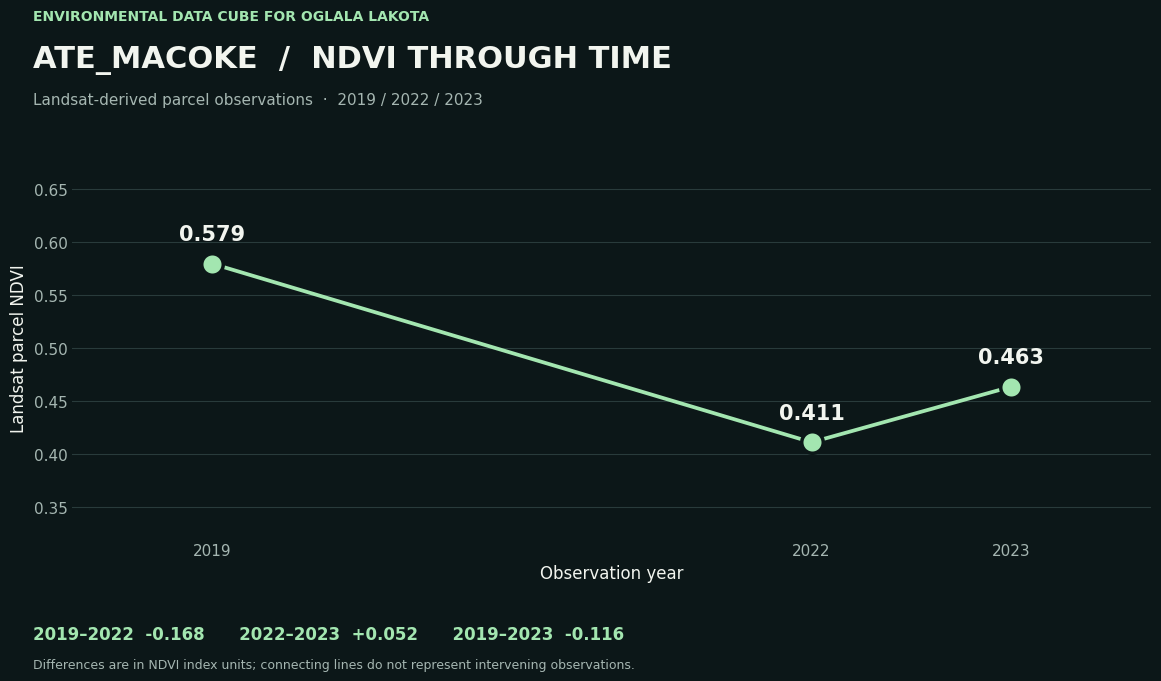

MAP 5 SAVED
PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_NDVI_Through_Time_2019_2023.png
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_NDVI_Through_Time_2019_2023.pdf
Original dissertation cube unchanged.


In [18]:

# ================================================================
# MAP 5 — NDVI THROUGH TIME | ATE_MACOKE
# Environmental Data Cube for Oglala Lakota
# 2019 / 2022 / 2023
#
# Reads original dissertation cube; saves figures only.
# ================================================================

from pathlib import Path
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

cube_path = (
    project / "Notebooks"
    / "environmental_data_cube_oglala_lakota_dissertation.nc"
)

out = project / "results/SA20_satellite_maps"
out.mkdir(parents=True, exist_ok=True)

with xr.open_dataset(cube_path) as ds:
    years = np.asarray(ds.year.values, dtype=int)
    values = np.asarray(
        ds["landsat_parcel_ndvi"].values,
        dtype=float
    )

expected = np.array([2019, 2022, 2023])

if not np.array_equal(years, expected):
    raise ValueError(f"Unexpected years: {years}")

if not np.all(np.isfinite(values)):
    raise ValueError("Missing NDVI values.")

# Contemporary scientific atlas styling
bg = "#0C1718"
fg = "#F2F5EF"
muted = "#A5B6B1"
accent = "#A3E6B0"
grid = "#344847"

fig, ax = plt.subplots(figsize=(13, 7.2))
fig.patch.set_facecolor(bg)
ax.set_facecolor(bg)

ax.plot(
    years, values,
    color=accent,
    linewidth=2.7,
    zorder=3
)

ax.scatter(
    years, values,
    s=240,
    color=accent,
    edgecolors=bg,
    linewidths=2.5,
    zorder=4
)

for year, value in zip(years, values):
    ax.annotate(
        f"{value:.3f}",
        (year, value),
        xytext=(0, 17),
        textcoords="offset points",
        ha="center",
        fontsize=15,
        fontweight="bold",
        color=fg
    )

ax.set_xlim(2018.3, 2023.7)
ax.set_ylim(0.32, 0.68)
ax.set_xticks(years)
ax.set_yticks(np.arange(0.35, 0.66, 0.05))

ax.tick_params(colors=muted, labelsize=11, length=0)
ax.set_ylabel("Landsat parcel NDVI", color=fg, fontsize=12)
ax.set_xlabel("Observation year", color=fg, fontsize=12)

ax.grid(axis="y", color=grid, alpha=0.75)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

fig.text(
    0.09, 0.94,
    "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA",
    fontsize=10,
    color=accent,
    weight="bold"
)

fig.text(
    0.09, 0.875,
    "ATE_MACOKE  /  NDVI THROUGH TIME",
    fontsize=22,
    color=fg,
    weight="bold"
)

fig.text(
    0.09, 0.823,
    "Landsat-derived parcel observations  ·  2019 / 2022 / 2023",
    fontsize=11,
    color=muted
)

delta_19_22 = values[1] - values[0]
delta_22_23 = values[2] - values[1]
delta_19_23 = values[2] - values[0]

fig.text(
    0.09, 0.080,
    (
        f"2019–2022  {delta_19_22:+.3f}      "
        f"2022–2023  {delta_22_23:+.3f}      "
        f"2019–2023  {delta_19_23:+.3f}"
    ),
    fontsize=12,
    color=accent,
    weight="bold"
)

fig.text(
    0.09, 0.040,
    "Differences are in NDVI index units; connecting lines do not represent intervening observations.",
    fontsize=9,
    color=muted
)

fig.subplots_adjust(
    left=0.12,
    right=0.95,
    top=0.75,
    bottom=0.22
)

png = out / "Ate_Macoke_NDVI_Through_Time_2019_2023.png"
pdf = out / "Ate_Macoke_NDVI_Through_Time_2019_2023.pdf"

# Avoid overwriting existing figures.
for path in (png, pdf):
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}"
        )

fig.savefig(
    png,
    dpi=300,
    bbox_inches="tight",
    facecolor=bg
)

fig.savefig(
    pdf,
    bbox_inches="tight",
    facecolor=bg
)

plt.show()

print("MAP 5 SAVED")
print("PNG:", png)
print("PDF:", pdf)
print("Original dissertation cube unchanged.")


In [19]:

# ============================================================
# FIND ORIGINAL LANDSAT NDVI PROCESSING CODE
# Environmental Data Cube for Oglala Lakota
#
# Searches existing Jupyter notebooks.
# READ ONLY — NO FILES MODIFIED.
# ============================================================

from pathlib import Path
import json

workspace = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
)

keywords = [
    "landsat_parcel_ndvi",
    "SR_B5",
    "SR_B4",
    "normalized_difference",
    "ndvi_raster",
    "ndvi_map",
    "landsat_ndvi",
    "landsat-8-c2-l2",
    "landsat-9-c2-l2"
]

notebooks = sorted(workspace.rglob("*.ipynb"))

print("=" * 65)
print("SEARCHING EXISTING NOTEBOOKS FOR LANDSAT NDVI")
print("=" * 65)

print("\nNotebooks found:", len(notebooks))

matches = []

for notebook in notebooks:

    try:
        with open(notebook, "r", encoding="utf-8") as f:
            nb = json.load(f)

        for index, cell in enumerate(
            nb.get("cells", []),
            start=1
        ):

            if cell.get("cell_type") != "code":
                continue

            source = "".join(cell.get("source", []))
            lower = source.lower()

            found = [
                term for term in keywords
                if term.lower() in lower
            ]

            if found:

                matches.append({
                    "notebook": notebook,
                    "cell": index,
                    "keywords": found,
                    "source": source
                })

    except Exception as exc:
        print(
            "Could not inspect:",
            notebook.name,
            str(exc)[:100]
        )

print("\nMATCHING CELLS:", len(matches))

for match in matches:

    print("\n" + "-" * 65)
    print("NOTEBOOK:", match["notebook"].name)
    print("CELL POSITION:", match["cell"])
    print("MATCHED:", ", ".join(match["keywords"]))

    lines = match["source"].splitlines()

    for line in lines[:12]:
        print("   ", line[:140])

print("\n" + "=" * 65)
print("SEARCH COMPLETE")
print("Original notebooks unchanged.")
print("=" * 65)


SEARCHING EXISTING NOTEBOOKS FOR LANDSAT NDVI

Notebooks found: 39

MATCHING CELLS: 6

-----------------------------------------------------------------
NOTEBOOK: 09_dissertation_data_cube_validation.ipynb
CELL POSITION: 409
MATCHED: normalized_difference
    
    # =============================================================================
    # SA 18.3 — STEP 4
    # LANDSAT COMPOSITE GENERATION CODE DISCOVERY
    #
    # Environmental Data Cube for Oglala Lakota
    #
    # READ-ONLY
    # No files modified, exported, or downloaded.
    # No coordinates or raw source code displayed.
    # =============================================================================
    

-----------------------------------------------------------------
NOTEBOOK: 09_dissertation_data_cube_validation.ipynb
CELL POSITION: 411
MATCHED: normalized_difference
    
    # =============================================================================
    # SA 18.3 — STEP 6
    # LANDSAT PROCESSING SEQUENCE 

In [20]:

# ============================================================
# MAP 5 — INSPECT ORIGINAL LANDSAT NDVI PROCESSING
# Environmental Data Cube for Oglala Lakota
#
# READ ONLY — DOES NOT EXECUTE OR CHANGE SOURCE CODE
# ============================================================

from pathlib import Path
import json

workspace = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026"
)

notebook_path = (
    workspace
    / "ate_makoce_agcube"
    / "Notebooks"
    / "08_your_own_question_eyt.ipynb"
)

if not notebook_path.exists():

    candidates = list(
        workspace.rglob("08_your_own_question_eyt.ipynb")
    )

    if not candidates:
        raise FileNotFoundError(
            "Notebook 08 was not found."
        )

    notebook_path = candidates[0]

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

cells = notebook["cells"]

# Cell position 12 from the notebook search
cell = cells[11]

source = "".join(cell.get("source", []))

print("=" * 65)
print("ORIGINAL LANDSAT NDVI PROCESSING")
print("=" * 65)

print("Notebook:", notebook_path.name)
print("Cell position:", 12)
print("Cell type:", cell.get("cell_type"))

print("\n" + "=" * 65)
print("ORIGINAL CODE")
print("=" * 65)

for number, line in enumerate(
    source.splitlines(),
    start=1
):
    print(f"{number:03d} | {line}")

print("\nREAD-ONLY INSPECTION COMPLETE")


ORIGINAL LANDSAT NDVI PROCESSING
Notebook: 08_your_own_question_eyt.ipynb
Cell position: 12
Cell type: code

ORIGINAL CODE
001 | # ============================================================
002 | # Landsat NDVI from Microsoft Planetary Computer
003 | # (no auth required — runs on a laptop)
004 | # ============================================================
005 | import odc.stac
006 | MAX_CLOUD = 40  # percent — raise to 60 if you get too few scenes
007 | 
008 | catalog = Client.open(
009 |     "https://planetarycomputer.microsoft.com/api/stac/v1",
010 |     modifier=pc.sign_inplace,
011 | )
012 | 
013 | search = catalog.search(
014 |     collections=["landsat-c2-l2"],
015 |     bbox=tuple(parcel_gdf.total_bounds),
016 |     datetime=f"{START_YEAR}-01-01/{END_YEAR}-12-31",
017 |     query={"eo:cloud_cover": {"lt": MAX_CLOUD}},
018 | )
019 | items = list(search.items())
020 | print(f"Found {len(items)} Landsat scenes")
021 | 
022 | if len(items) == 0:
023 |     raise RuntimeError(
024

Reference grid: 58 x 56
CRS: EPSG:32613
Parcel pixels: 2878

PROCESSING YEAR: 2019
Candidate Landsat scenes: 12


/var/folders/r7/f138w89x4p50r5fyd0h8jm8h0000gn/T/ipykernel_31256/1339195980.py:241: RuntimeWarning: All-NaN slice encountered
  composite = np.nanmedian(


Scenes processed: 12
Valid parcel pixels: 2878
Parcel mean NDVI: 0.586066

PROCESSING YEAR: 2022
Candidate Landsat scenes: 13


/var/folders/r7/f138w89x4p50r5fyd0h8jm8h0000gn/T/ipykernel_31256/1339195980.py:241: RuntimeWarning: All-NaN slice encountered
  composite = np.nanmedian(


Scenes processed: 13
Valid parcel pixels: 2878
Parcel mean NDVI: 0.421217

PROCESSING YEAR: 2023
Candidate Landsat scenes: 21


/var/folders/r7/f138w89x4p50r5fyd0h8jm8h0000gn/T/ipykernel_31256/1339195980.py:241: RuntimeWarning: All-NaN slice encountered
  composite = np.nanmedian(


Scenes processed: 20
Valid parcel pixels: 2878
Parcel mean NDVI: 0.479537
Saved NDVI raster: Ate_Macoke_Landsat_NDVI_2019_MaySep_Median_30m.tif
Saved NDVI raster: Ate_Macoke_Landsat_NDVI_2022_MaySep_Median_30m.tif
Saved NDVI raster: Ate_Macoke_Landsat_NDVI_2023_MaySep_Median_30m.tif

ORIGINAL VS NEW SPATIAL COMPOSITE
------------------------------------------------------------
2019 | Original: 0.579177 | New: 0.586066 | Difference: +0.006889
2022 | Original: 0.410684 | New: 0.421217 | Difference: +0.010533
2023 | Original: 0.463162 | New: 0.479537 | Difference: +0.016375


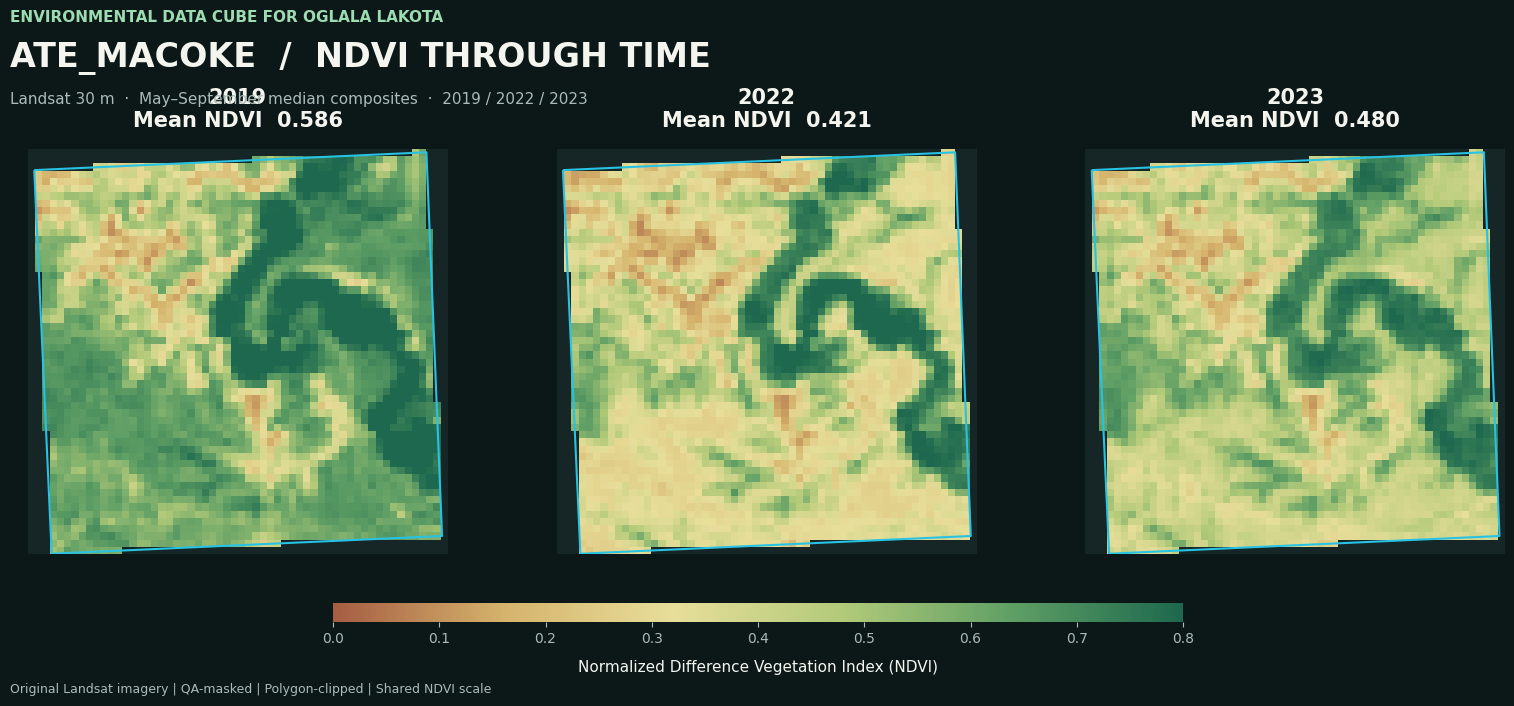


MAP 5 — THREE SPATIAL NDVI MAPS COMPLETE
PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_NDVI_Spatial_2019_2022_2023.png
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_NDVI_Spatial_2019_2022_2023.pdf
Original dissertation cube unchanged.


In [21]:

# ================================================================
# MAP 5 — ATE_MACOKE NDVI THROUGH TIME
# Environmental Data Cube for Oglala Lakota
#
# 2019 | 2022 | 2023
# Landsat Collection 2 Level-2
# May–September median NDVI composite
# 30 m | EPSG:32613
#
# Source data remain unchanged.
# New maps and composites are saved separately.
# ================================================================

from pathlib import Path
import numpy as np
import geopandas as gpd
import xarray as xr
import rasterio
from rasterio.features import geometry_mask
from rasterio.transform import array_bounds
from rasterio.enums import Resampling
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from pystac_client import Client
import planetary_computer
from pyproj import Transformer
from shapely.geometry import mapping

# ------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

out = project / "results/SA20_satellite_maps"
out.mkdir(parents=True, exist_ok=True)

parcel_path = project / "data/ate_parcel_wanzi.shp"

reference_path = (
    project
    / "outputs/sa16_16_ate_makoce_final/v01"
    / "ate_makoce_vegetation_trajectories_2019_2023.tif"
)

cube_path = (
    project
    / "Notebooks/environmental_data_cube_oglala_lakota_dissertation.nc"
)

years = [2019, 2022, 2023]

# ------------------------------------------------
# 2. LOAD PARCEL AND REFERENCE GRID
# ------------------------------------------------

parcel = gpd.read_file(parcel_path)

with rasterio.open(reference_path) as ref:
    profile = ref.profile.copy()
    transform = ref.transform
    crs = ref.crs
    height = ref.height
    width = ref.width
    bounds = ref.bounds

if crs is None:
    raise ValueError("Reference raster has no CRS.")

parcel = parcel.to_crs(crs)

mask = geometry_mask(
    [mapping(g) for g in parcel.geometry],
    out_shape=(height, width),
    transform=transform,
    invert=True
)

print("Reference grid:", width, "x", height)
print("CRS:", crs)
print("Parcel pixels:", int(mask.sum()))

# ------------------------------------------------
# 3. SET UP PLANETARY COMPUTER
# ------------------------------------------------

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1"
)

# Search bounding box in WGS84
parcel_wgs84 = parcel.to_crs("EPSG:4326")
bbox = tuple(parcel_wgs84.total_bounds)

# ------------------------------------------------
# 4. LOAD EACH YEAR'S LANDSAT NDVI
# ------------------------------------------------

import odc.stac

annual_maps = {}
scene_counts = {}

for year in years:

    print("\n" + "=" * 55)
    print("PROCESSING YEAR:", year)
    print("=" * 55)

    search = catalog.search(
        collections=["landsat-c2-l2"],
        bbox=bbox,
        datetime=f"{year}-05-01/{year}-09-30",
        query={"eo:cloud_cover": {"lt": 40}}
    )

    items = list(search.items())

    print("Candidate Landsat scenes:", len(items))

    if not items:
        raise RuntimeError(
            f"No Landsat scenes found for {year}."
        )

    signed_items = [
        planetary_computer.sign(item)
        for item in items
    ]

    # Load directly onto the original 30 m reference grid.
    ds = odc.stac.load(
        signed_items,
        bands=["red", "nir08", "qa_pixel"],
        crs=str(crs),
        resolution=30,
        bbox=bbox,
        groupby="solar_day",
        fail_on_error=False
    )

    # Align exactly to the saved reference grid if needed.
    # Rasterio's reproject handles any small grid offset.
    from rasterio.warp import reproject

    red_dn = ds["red"].values
    nir_dn = ds["nir08"].values
    qa_dn = ds["qa_pixel"].values

    ndvi_scenes = []

    for i in range(red_dn.shape[0]):

        # Landsat Collection 2 L2 scaling
        red = red_dn[i].astype("float32") * 0.0000275 - 0.2
        nir = nir_dn[i].astype("float32") * 0.0000275 - 0.2

        qa = qa_dn[i].astype("uint16")

        # Bits 0–5: fill, dilated cloud, cirrus,
        # cloud, cloud shadow, snow
        clear = (qa & 0b111111) == 0

        denominator = nir + red

        valid = (
            clear
            & np.isfinite(red)
            & np.isfinite(nir)
            & (denominator != 0)
            & (red > 0)
            & (nir > 0)
        )

        scene_ndvi = np.full(
            red.shape,
            np.nan,
            dtype="float32"
        )

        scene_ndvi[valid] = (
            (nir[valid] - red[valid])
            / denominator[valid]
        )

        scene_ndvi[
            (scene_ndvi < -1) | (scene_ndvi > 1)
        ] = np.nan

        # Reproject the NDVI scene onto the original
        # 56 x 58 pixel dissertation raster grid.
        aligned = np.full(
            (height, width),
            np.nan,
            dtype="float32"
        )

        # ODC x/y coordinates define the source grid.
        x = ds.x.values
        y = ds.y.values

        dx = abs(float(x[1] - x[0]))
        dy = abs(float(y[1] - y[0]))

        from rasterio.transform import from_origin

        src_transform = from_origin(
            float(x.min()) - dx / 2,
            float(y.max()) + dy / 2,
            dx,
            dy
        )

        reproject(
            source=scene_ndvi,
            destination=aligned,
            src_transform=src_transform,
            src_crs=crs,
            dst_transform=transform,
            dst_crs=crs,
            src_nodata=np.nan,
            dst_nodata=np.nan,
            resampling=Resampling.nearest
        )

        aligned[~mask] = np.nan
        ndvi_scenes.append(aligned)

    if not ndvi_scenes:
        raise RuntimeError(
            f"No usable NDVI scenes for {year}."
        )

    # Median of QA-masked scene NDVI values.
    with np.errstate(all="ignore"):
        composite = np.nanmedian(
            np.stack(ndvi_scenes),
            axis=0
        ).astype("float32")

    composite[~mask] = np.nan

    if not np.isfinite(composite).any():
        raise RuntimeError(
            f"No valid parcel NDVI pixels for {year}."
        )

    annual_maps[year] = composite
    scene_counts[year] = len(ndvi_scenes)

    print("Scenes processed:", scene_counts[year])
    print("Valid parcel pixels:",
          int(np.isfinite(composite).sum()))
    print("Parcel mean NDVI:",
          round(float(np.nanmean(composite)), 6))

# ------------------------------------------------
# 5. SAVE SPATIAL NDVI COMPOSITES
# ------------------------------------------------

for year, arr in annual_maps.items():

    path = out / (
        f"Ate_Macoke_Landsat_NDVI_"
        f"{year}_MaySep_Median_30m.tif"
    )

    if path.exists():
        raise FileExistsError(
            f"Existing output preserved: {path}"
        )

    raster_profile = profile.copy()

    raster_profile.update(
        driver="GTiff",
        count=1,
        dtype="float32",
        nodata=-9999.0,
        compress="deflate"
    )

    save_array = np.where(
        np.isfinite(arr),
        arr,
        -9999.0
    ).astype("float32")

    with rasterio.open(path, "w", **raster_profile) as dst:
        dst.write(save_array, 1)
        dst.set_band_description(
            1, f"{year} May–September median NDVI"
        )
        dst.update_tags(
            source="Landsat Collection 2 Level-2",
            composite="Median of QA-masked scene NDVI",
            year=str(year),
            season="May–September"
        )

    print("Saved NDVI raster:", path.name)

# ------------------------------------------------
# 6. COMPARE AGAINST ORIGINAL DISSERTATION CUBE
# ------------------------------------------------

with xr.open_dataset(cube_path) as original:
    original_years = original["year"].values
    original_ndvi = original["landsat_parcel_ndvi"].values

print("\nORIGINAL VS NEW SPATIAL COMPOSITE")
print("-" * 60)

for year in years:

    index = np.where(original_years == year)[0]

    original_value = (
        float(original_ndvi[index[0]])
        if len(index)
        else np.nan
    )

    new_value = float(
        np.nanmean(annual_maps[year])
    )

    print(
        f"{year} | "
        f"Original: {original_value:.6f} | "
        f"New: {new_value:.6f} | "
        f"Difference: {new_value-original_value:+.6f}"
    )

# ------------------------------------------------
# 7. MODERN SCIENTIFIC ATLAS DESIGN
# ------------------------------------------------

cmap = LinearSegmentedColormap.from_list(
    "Ate_Macoke_NDVI",
    [
        "#A65D43",
        "#D5B36C",
        "#E7DE9A",
        "#B2CA79",
        "#5F9F65",
        "#1D684E"
    ],
    N=256
)

cmap.set_bad("#162526")

norm = Normalize(vmin=0.0, vmax=0.8)

bg = "#0C1718"
fg = "#F4F5EF"
muted = "#AABCB7"
cyan = "#28C2E2"

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 7.5),
    facecolor=bg
)

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]

for ax, year in zip(axes, years):

    ax.set_facecolor(bg)

    ax.imshow(
        annual_maps[year],
        extent=extent,
        origin="upper",
        cmap=cmap,
        norm=norm,
        interpolation="nearest"
    )

    parcel.boundary.plot(
        ax=ax,
        color=cyan,
        linewidth=1.5
    )

    mean_ndvi = float(
        np.nanmean(annual_maps[year])
    )

    ax.set_title(
        f"{year}\nMean NDVI  {mean_ndvi:.3f}",
        color=fg,
        fontsize=15,
        fontweight="bold",
        pad=16
    )

    ax.set_xlim(bounds.left, bounds.right)
    ax.set_ylim(bounds.bottom, bounds.top)
    ax.set_aspect("equal")
    ax.axis("off")

fig.text(
    0.06, 0.93,
    "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA",
    color="#9DDBB0",
    fontsize=11,
    fontweight="bold"
)

fig.text(
    0.06, 0.87,
    "ATE_MACOKE  /  NDVI THROUGH TIME",
    color=fg,
    fontsize=24,
    fontweight="bold"
)

fig.text(
    0.06, 0.82,
    "Landsat 30 m  ·  May–September median composites  ·  2019 / 2022 / 2023",
    color=muted,
    fontsize=11
)

fig.subplots_adjust(
    left=0.05,
    right=0.96,
    top=0.76,
    bottom=0.22,
    wspace=0.08
)

sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar_ax = fig.add_axes([0.25, 0.13, 0.50, 0.025])

cbar = fig.colorbar(
    sm,
    cax=cbar_ax,
    orientation="horizontal"
)

cbar.set_label(
    "Normalized Difference Vegetation Index (NDVI)",
    color=fg,
    fontsize=11,
    labelpad=10
)

cbar.ax.tick_params(colors=muted)
cbar.outline.set_visible(False)

fig.text(
    0.06, 0.035,
    "Original Landsat imagery | QA-masked | Polygon-clipped | Shared NDVI scale",
    color=muted,
    fontsize=9
)

# ------------------------------------------------
# 8. EXPORT DISSERTATION FIGURE
# ------------------------------------------------

png_path = out / (
    "Ate_Macoke_NDVI_Spatial_2019_2022_2023.png"
)

pdf_path = out / (
    "Ate_Macoke_NDVI_Spatial_2019_2022_2023.pdf"
)

for path in (png_path, pdf_path):
    if path.exists():
        raise FileExistsError(
            f"Existing figure preserved: {path}"
        )

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=bg
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor=bg
)

plt.show()

print("\n" + "=" * 60)
print("MAP 5 — THREE SPATIAL NDVI MAPS COMPLETE")
print("=" * 60)
print("PNG:", png_path)
print("PDF:", pdf_path)
print("Original dissertation cube unchanged.")


AUTHORITATIVE DISSERTATION NDVI
2019: 0.579177
2022: 0.410684
2023: 0.463162


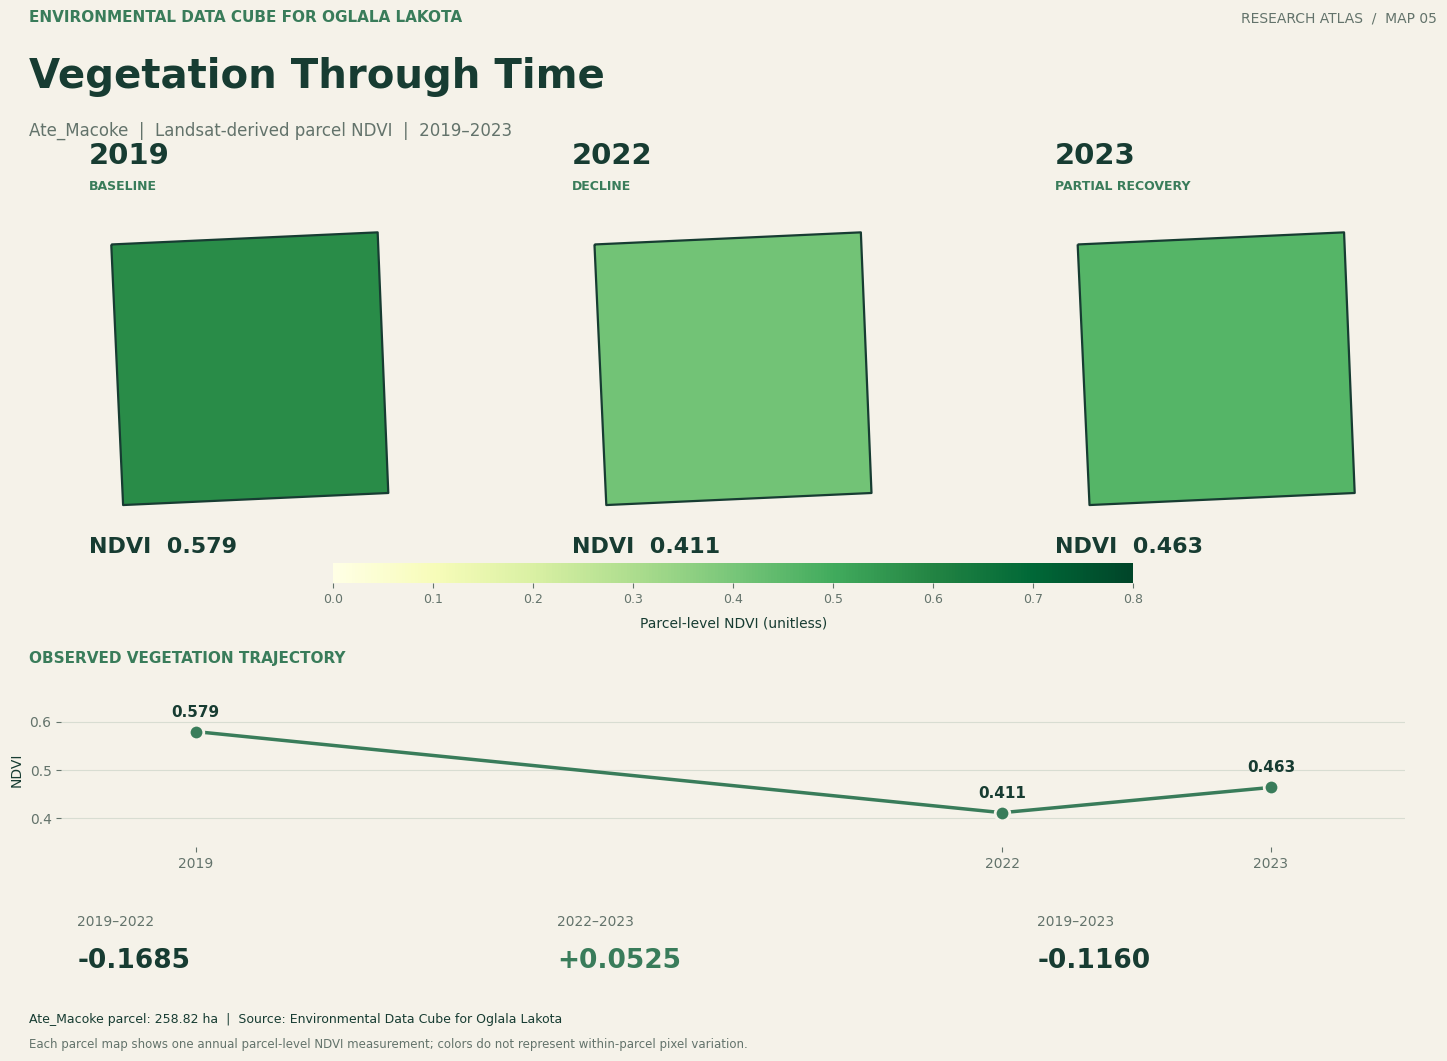


MAP 5 — PROFESSIONAL ATLAS COMPLETE
PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_NDVI_Through_Time_Atlas.png
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_NDVI_Through_Time_Atlas.pdf
Original data cube unchanged.


In [22]:

# ================================================================
# MAP 5 — ATE_MACOKE VEGETATION THROUGH TIME
# PROFESSIONAL SCIENTIFIC ATLAS
#
# Environmental Data Cube for Oglala Lakota
# Authoritative NDVI source: Dissertation NetCDF
# Years: 2019, 2022, 2023
#
# No new NDVI calculations or satellite downloads.
# Original research files remain unchanged.
# ================================================================

from pathlib import Path
import numpy as np
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch

# ------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

cube_path = (
    project / "Notebooks"
    / "environmental_data_cube_oglala_lakota_dissertation.nc"
)

parcel_path = project / "data/ate_parcel_wanzi.shp"

out = project / "results/SA20_satellite_maps"
out.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------
# 2. READ AUTHORITATIVE DATA CUBE VALUES
# ------------------------------------------------

with xr.open_dataset(cube_path) as ds:
    years = np.asarray(ds["year"].values, dtype=int)
    ndvi = np.asarray(
        ds["landsat_parcel_ndvi"].values,
        dtype=float
    )

expected_years = np.array([2019, 2022, 2023])

if not np.array_equal(years, expected_years):
    raise ValueError(
        f"Unexpected study years: {years}"
    )

if not np.all(np.isfinite(ndvi)):
    raise ValueError("Missing NDVI measurements.")

if np.any((ndvi < -1) | (ndvi > 1)):
    raise ValueError("NDVI outside valid range.")

print("AUTHORITATIVE DISSERTATION NDVI")

for year, value in zip(years, ndvi):
    print(f"{year}: {value:.6f}")

# ------------------------------------------------
# 3. LOAD ORIGINAL ATE_MACOKE PARCEL
# ------------------------------------------------

parcel = gpd.read_file(parcel_path)

if parcel.empty or parcel.crs is None:
    raise ValueError("Invalid parcel geometry or CRS.")

parcel = parcel.to_crs("EPSG:32613")
parcel_area_ha = parcel.geometry.area.sum() / 10000

xmin, ymin, xmax, ymax = parcel.total_bounds
padding = 175

# ------------------------------------------------
# 4. ATLAS DESIGN PALETTE
# ------------------------------------------------

paper = "#F5F2E9"
ink = "#173C32"
muted = "#63736B"
rule = "#D8DDD2"
accent = "#397C5A"

cmap = plt.get_cmap("YlGn")
norm = Normalize(vmin=0.0, vmax=0.8)

# ------------------------------------------------
# 5. CREATE EDITORIAL ATLAS LAYOUT
# ------------------------------------------------

fig = plt.figure(
    figsize=(16, 11),
    facecolor=paper
)

fig.text(
    0.06, 0.955,
    "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA",
    color=accent,
    fontsize=11,
    weight="bold"
)

fig.text(
    0.94, 0.955,
    "RESEARCH ATLAS  /  MAP 05",
    color=muted,
    fontsize=10,
    ha="right"
)

fig.text(
    0.06, 0.895,
    "Vegetation Through Time",
    color=ink,
    fontsize=29,
    weight="bold"
)

fig.text(
    0.06, 0.852,
    "Ate_Macoke  |  Landsat-derived parcel NDVI  |  2019–2023",
    color=muted,
    fontsize=12
)

# ------------------------------------------------
# 6. THREE PARCEL MAP PANELS
# ------------------------------------------------

positions = [
    [0.055, 0.49, 0.285, 0.30],
    [0.357, 0.49, 0.285, 0.30],
    [0.659, 0.49, 0.285, 0.30]
]

labels = [
    "BASELINE",
    "DECLINE",
    "PARTIAL RECOVERY"
]

for i, (year, value) in enumerate(zip(years, ndvi)):

    ax = fig.add_axes(positions[i])
    ax.set_facecolor(paper)

    parcel.plot(
        ax=ax,
        facecolor=cmap(norm(value)),
        edgecolor=ink,
        linewidth=1.6
    )

    ax.set_xlim(xmin-padding, xmax+padding)
    ax.set_ylim(ymin-padding, ymax+padding)
    ax.set_aspect("equal")
    ax.axis("off")

    ax.text(
        0.02, 1.12,
        str(year),
        transform=ax.transAxes,
        fontsize=21,
        weight="bold",
        color=ink
    )

    ax.text(
        0.02, 1.04,
        labels[i],
        transform=ax.transAxes,
        fontsize=9,
        weight="bold",
        color=accent
    )

    ax.text(
        0.02, -0.06,
        f"NDVI  {value:.3f}",
        transform=ax.transAxes,
        fontsize=16,
        weight="bold",
        color=ink
    )

# ------------------------------------------------
# 7. SHARED NDVI COLOR SCALE
# ------------------------------------------------

cax = fig.add_axes([0.25, 0.445, 0.50, 0.018])

sm = ScalarMappable(
    norm=norm,
    cmap=cmap
)
sm.set_array([])

cb = fig.colorbar(
    sm,
    cax=cax,
    orientation="horizontal"
)

cb.set_label(
    "Parcel-level NDVI (unitless)",
    fontsize=10,
    color=ink,
    labelpad=8
)

cb.ax.tick_params(colors=muted, labelsize=9)
cb.outline.set_visible(False)

# ------------------------------------------------
# 8. OBSERVED NDVI TRAJECTORY
# ------------------------------------------------

fig.text(
    0.06, 0.372,
    "OBSERVED VEGETATION TRAJECTORY",
    color=accent,
    fontsize=11,
    weight="bold"
)

ax = fig.add_axes([0.08, 0.205, 0.84, 0.14])

ax.set_facecolor(paper)

ax.plot(
    years,
    ndvi,
    color=accent,
    linewidth=2.5,
    zorder=2
)

ax.scatter(
    years,
    ndvi,
    s=110,
    color=accent,
    edgecolors=paper,
    linewidths=2,
    zorder=3
)

for year, value in zip(years, ndvi):
    ax.annotate(
        f"{value:.3f}",
        (year, value),
        xytext=(0, 11),
        textcoords="offset points",
        ha="center",
        color=ink,
        fontsize=11,
        weight="bold"
    )

ax.set_xlim(2018.5, 2023.5)
ax.set_ylim(0.34, 0.66)
ax.set_xticks(years)
ax.set_ylabel("NDVI", color=ink)

ax.tick_params(colors=muted)
ax.grid(axis="y", color=rule)

for spine in ax.spines.values():
    spine.set_visible(False)

# ------------------------------------------------
# 9. CHANGE STATISTICS
# ------------------------------------------------

changes = [
    ndvi[1] - ndvi[0],
    ndvi[2] - ndvi[1],
    ndvi[2] - ndvi[0]
]

change_labels = [
    "2019–2022",
    "2022–2023",
    "2019–2023"
]

for i, (label, change) in enumerate(
    zip(change_labels, changes)
):
    x = 0.09 + i * 0.30

    fig.text(
        x, 0.133,
        label,
        fontsize=10,
        color=muted
    )

    fig.text(
        x, 0.095,
        f"{change:+.4f}",
        fontsize=19,
        weight="bold",
        color=accent if change >= 0 else ink
    )

# ------------------------------------------------
# 10. DATA PROVENANCE AND CAPTION
# ------------------------------------------------

fig.text(
    0.06, 0.045,
    (
        f"Ate_Macoke parcel: {parcel_area_ha:.2f} ha  |  "
        "Source: Environmental Data Cube for Oglala Lakota"
    ),
    color=ink,
    fontsize=9
)

fig.text(
    0.06, 0.022,
    (
        "Each parcel map shows one annual parcel-level NDVI "
        "measurement; colors do not represent within-parcel "
        "pixel variation."
    ),
    color=muted,
    fontsize=8.5
)

# ------------------------------------------------
# 11. SAVE ATLAS FIGURE
# ------------------------------------------------

png_path = (
    out / "Ate_Macoke_NDVI_Through_Time_Atlas.png"
)

pdf_path = (
    out / "Ate_Macoke_NDVI_Through_Time_Atlas.pdf"
)

for path in (png_path, pdf_path):
    if path.exists():
        raise FileExistsError(
            f"Existing atlas file preserved: {path}"
        )

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=paper
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor=paper
)

plt.show()

print("\nMAP 5 — PROFESSIONAL ATLAS COMPLETE")
print("PNG:", png_path)
print("PDF:", pdf_path)
print("Original data cube unchanged.")


In [23]:

# ================================================================
# NINE-YEAR ATLAS — DATA CUBE COMPATIBILITY INSPECTION
# Environmental Data Cube for Oglala Lakota
#
# READ ONLY — no changes to source data
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr

workspace = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026"
)

project = workspace / "ate_makoce_agcube"

# Search both the dissertation project and the broader workspace.
files = sorted(workspace.rglob("*.nc"))

print("=" * 75)
print("ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA")
print("2015–2023 NDVI DATA INVENTORY")
print("=" * 75)
print(f"\nNetCDF files found: {len(files)}")

for path in files:

    try:
        with xr.open_dataset(path) as ds:

            ndvi_names = [
                name for name in ds.data_vars
                if "ndvi" in name.lower()
            ]

            if not ndvi_names:
                continue

            print("\n" + "=" * 75)
            print("FILE:", path.relative_to(workspace))
            print("DIMENSIONS:", dict(ds.sizes))

            print("\nDATASET METADATA:")

            for key in [
                "title",
                "location",
                "source",
                "sensor",
                "platform",
                "time_period",
                "spatial_resolution",
                "tk_community"
            ]:
                if key in ds.attrs:
                    print(f"  {key}: {ds.attrs[key]}")

            for name in ndvi_names:

                da = ds[name]

                print("\n  NDVI VARIABLE:", name)
                print("  Dimensions:", da.dims)
                print("  Shape:", da.shape)

                for key in [
                    "long_name",
                    "source",
                    "sensor",
                    "units",
                    "resolution",
                    "aggregation",
                    "description"
                ]:
                    if key in da.attrs:
                        print(
                            f"  {key}: {da.attrs[key]}"
                        )

                # Identify time/year coordinates without
                # assuming every dataset has the same structure.
                for coord_name in ["year", "time"]:

                    if coord_name not in da.coords:
                        continue

                    values = da[coord_name].values

                    if len(values) == 0:
                        continue

                    print(
                        f"  {coord_name} range:",
                        str(values[0]),
                        "to",
                        str(values[-1])
                    )

                # Print actual annual NDVI values only when
                # there is exactly one value per year.
                if (
                    "year" in da.dims
                    and da.ndim == 1
                ):

                    print("  Annual NDVI values:")

                    for year, value in zip(
                        da["year"].values,
                        da.values
                    ):
                        if 2015 <= int(year) <= 2023:
                            print(
                                f"    {int(year)}: "
                                f"{float(value):.6f}"
                            )

    except Exception as exc:
        print(
            "\nCould not inspect:",
            path.name,
            type(exc).__name__,
            str(exc)[:150]
        )

print("\n" + "=" * 75)
print("INSPECTION COMPLETE")
print("=" * 75)


ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
2015–2023 NDVI DATA INVENTORY

NetCDF files found: 24

FILE: ate_makoce_agcube/Notebooks/environmental_data_cube_oglala_lakota_2000_2023.nc
DIMENSIONS: {'year': 24}

DATASET METADATA:
  title: Environmental Data Cube for Oglala Lakota

  NDVI VARIABLE: ndvi
  Dimensions: ('year',)
  Shape: (24,)
  units: 1
  year range: 2000 to 2023
  Annual NDVI values:
    2015: 0.404657
    2016: 0.370857
    2017: 0.386296
    2018: 0.377943
    2019: 0.395909
    2020: 0.390878
    2021: 0.384691
    2022: 0.372752
    2023: 0.398504

FILE: ate_makoce_agcube/Notebooks/environmental_data_cube_oglala_lakota_dissertation.nc
DIMENSIONS: {'year': 3}

DATASET METADATA:
  title: Environmental Data Cube for Oglala Lakota

  NDVI VARIABLE: landsat_parcel_ndvi
  Dimensions: ('year',)
  Shape: (3,)
  units: 1
  description: Mean Landsat NDVI over the analyzed parcel pixels
  year range: 2019 to 2023
  Annual NDVI values:
    2019: 0.579177
    2022: 0.410684
    2023

In [25]:

# ================================================================
# NINE-YEAR VEGETATION ATLAS
# STEP 2 — VERIFY NDVI DATA SOURCES
#
# Environmental Data Cube for Oglala Lakota
# Ate_Macoke | 2015–2023
#
# READ ONLY — no files modified
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd

workspace = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026"
)

project = workspace / "ate_makoce_agcube"

annual_path = (
    project
    / "data/cache/environmental_data_cube_oglala_lakota_2015_2023.nc"
)

lattice_path = (
    workspace
    / "datacube_tutorial_eyt_broken/data/cache"
    / "ndvi_lattice_Wanzi_15pts_2015_2023.nc"
)

dissertation_path = (
    project
    / "Notebooks/environmental_data_cube_oglala_lakota_dissertation.nc"
)

parcel_path = project / "data/ate_parcel_wanzi.shp"

years = np.arange(2015, 2024)

# ------------------------------------------------
# 1. LOAD ANNUAL ENVIRONMENTAL CUBE
# ------------------------------------------------

with xr.open_dataset(annual_path) as ds:
    annual = ds["ndvi"].sel(year=years).load()
    annual_attrs = dict(ds.attrs)
    annual_var_attrs = dict(ds["ndvi"].attrs)

# ------------------------------------------------
# 2. LOAD WANZI 15-POINT NDVI LATTICE
# ------------------------------------------------

with xr.open_dataset(lattice_path) as ds:
    lattice = ds["ndvi"].sel(year=years).load()
    lattice_attrs = dict(ds.attrs)
    lattice_var_attrs = dict(ds["ndvi"].attrs)

    print("LATTICE COORDINATES:")
    print(list(ds.coords))

    if "lat" in ds.coords and "lon" in ds.coords:
        point_lat = ds["lat"].values
        point_lon = ds["lon"].values
    else:
        point_lat = None
        point_lon = None

lattice_mean = lattice.mean(
    dim="point",
    skipna=True
)

lattice_valid = lattice.count(dim="point")

# ------------------------------------------------
# 3. LOAD ORIGINAL DISSERTATION LANDSAT VALUES
# ------------------------------------------------

with xr.open_dataset(dissertation_path) as ds:
    dissertation = ds["landsat_parcel_ndvi"].load()

# ------------------------------------------------
# 4. BUILD COMPARISON TABLE
# ------------------------------------------------

comparison = pd.DataFrame({
    "Year": years,
    "Environmental cube NDVI": annual.values,
    "Wanzi lattice NDVI": lattice_mean.values,
    "Valid lattice points": lattice_valid.values
})

dissertation_values = dict(zip(
    dissertation["year"].values.astype(int),
    dissertation.values.astype(float)
))

comparison["Dissertation Landsat NDVI"] = (
    comparison["Year"].map(dissertation_values)
)

comparison["Lattice minus environmental"] = (
    comparison["Wanzi lattice NDVI"]
    - comparison["Environmental cube NDVI"]
)

print("\n" + "=" * 90)
print("2015–2023 NDVI COMPARISON")
print("=" * 90)

print(
    comparison.to_string(
        index=False,
        float_format=lambda v: f"{v:.6f}"
    )
)

# ------------------------------------------------
# 5. VERIFY POINTS AGAINST PARCEL BOUNDARY
# ------------------------------------------------

if point_lat is not None and point_lon is not None:

    points = gpd.GeoDataFrame(
        {"point": np.arange(len(point_lat))},
        geometry=gpd.points_from_xy(
            point_lon,
            point_lat
        ),
        crs="EPSG:4326"
    )

    parcel = gpd.read_file(parcel_path)
    points = points.to_crs(parcel.crs)

    parcel_geometry = parcel.geometry.unary_union
    inside = points.geometry.apply(
        parcel_geometry.covers
    )

    print("\nSPATIAL VERIFICATION")
    print("-" * 50)
    print("Total lattice points:", len(points))
    print("Inside or on parcel:", int(inside.sum()))
    print("Outside parcel:", int((~inside).sum()))

else:
    print(
        "\nPoint coordinates not found. "
        "Spatial verification requires further inspection."
    )

# ------------------------------------------------
# 6. PRINT DATA PROVENANCE
# ------------------------------------------------

print("\n" + "=" * 90)
print("ANNUAL ENVIRONMENTAL CUBE METADATA")
print("=" * 90)
print("Dataset:", annual_attrs)
print("NDVI variable:", annual_var_attrs)

print("\n" + "=" * 90)
print("WANZI LATTICE METADATA")
print("=" * 90)
print("Dataset:", lattice_attrs)
print("NDVI variable:", lattice_var_attrs)

# ------------------------------------------------
# 7. BASIC DATA QUALITY CHECKS
# ------------------------------------------------

print("\n" + "=" * 90)
print("DATA QUALITY")
print("=" * 90)

print(
    "Annual environmental values:",
    int(np.isfinite(annual.values).sum()),
    "of",
    len(years)
)

print(
    "Annual lattice means:",
    int(np.isfinite(lattice_mean.values).sum()),
    "of",
    len(years)
)

print(
    "Lattice observation count by year:",
    lattice_valid.values.astype(int).tolist()
)

print("\nVERIFICATION COMPLETE — SOURCE DATA UNCHANGED")


LATTICE COORDINATES:
['year', 'point', 'lat', 'lon']

2015–2023 NDVI COMPARISON
 Year  Environmental cube NDVI  Wanzi lattice NDVI  Valid lattice points  Dissertation Landsat NDVI  Lattice minus environmental
 2015                 0.404657            0.503552                    12                        NaN                     0.098895
 2016                 0.370857            0.469609                    12                        NaN                     0.098753
 2017                 0.386296            0.418561                    12                        NaN                     0.032265
 2018                 0.377943            0.483109                    12                        NaN                     0.105166
 2019                 0.395909            0.550868                    12                   0.579177                     0.154959
 2020                 0.390878            0.480700                    12                        NaN                     0.089822
 2021            

VERIFIED WANZI NDVI SERIES
---------------------------------------------
2015: 0.503552 (12 valid points)
2016: 0.469609 (12 valid points)
2017: 0.418561 (12 valid points)
2018: 0.483109 (12 valid points)
2019: 0.550868 (12 valid points)
2020: 0.480700 (12 valid points)
2021: 0.409356 (12 valid points)
2022: 0.375069 (12 valid points)
2023: 0.477456 (12 valid points)


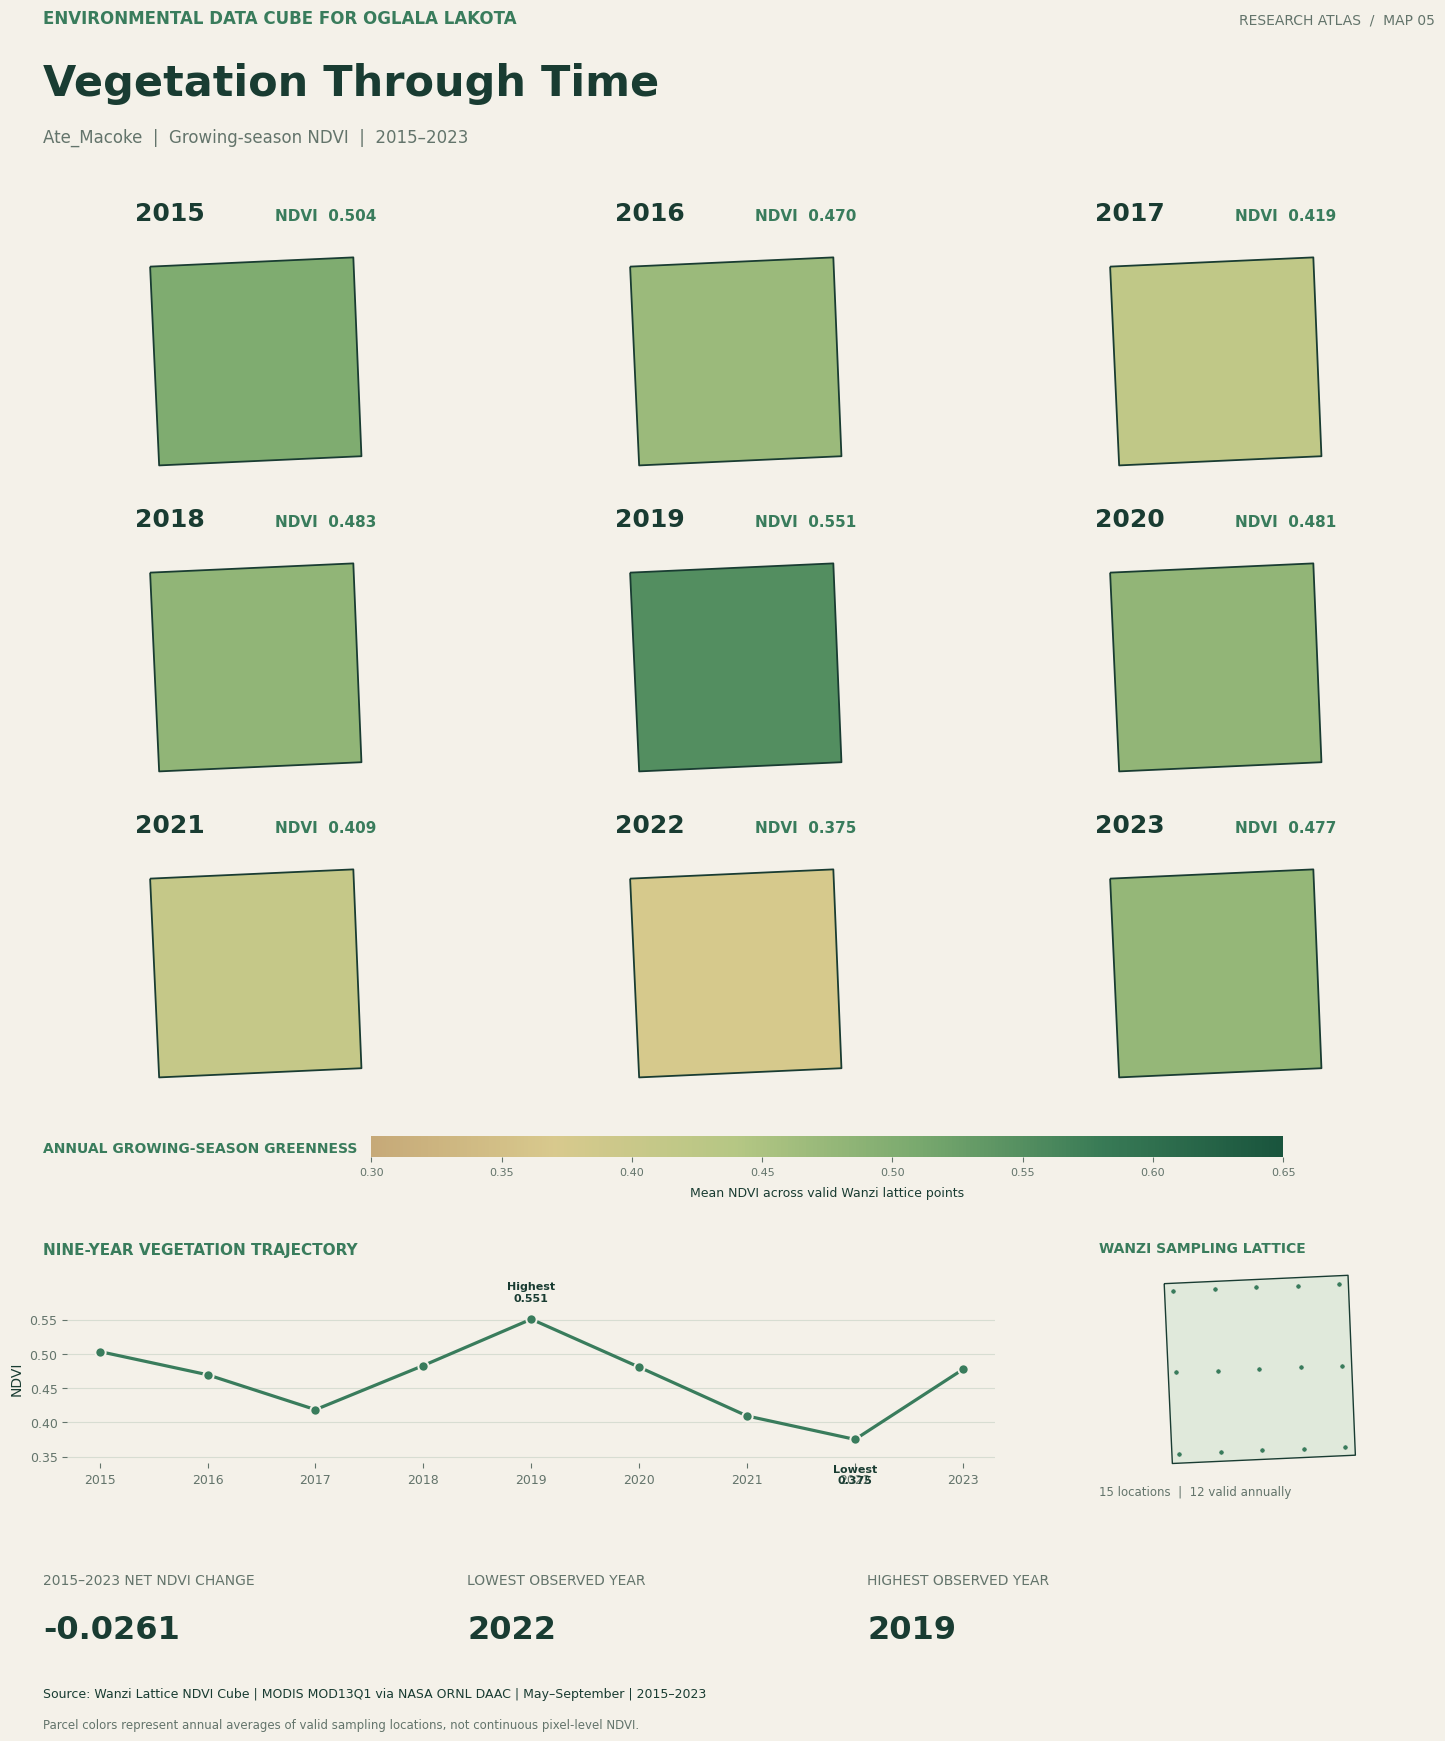


MAP 5 — NINE-YEAR VEGETATION ATLAS COMPLETE
PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Nine_Year_NDVI_Atlas.png
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Nine_Year_NDVI_Atlas.pdf
Source NetCDF and shapefile unchanged.


In [26]:

# ================================================================
# MAP 5 — ATE_MACOKE VEGETATION THROUGH TIME
# NINE-YEAR PROFESSIONAL RESEARCH ATLAS
#
# Environmental Data Cube for Oglala Lakota
# Wanzi Lattice NDVI Cube | 2015–2023
# MODIS MOD13Q1 | May–September
#
# READS EXISTING DATA ONLY
# DOES NOT MODIFY SOURCE NETCDF OR SHAPEFILE
# ================================================================

from pathlib import Path
import numpy as np
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D

# ------------------------------------------------
# 1. PATHS
# ------------------------------------------------

workspace = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026"
)

project = workspace / "ate_makoce_agcube"

lattice_path = (
    workspace
    / "datacube_tutorial_eyt_broken/data/cache"
    / "ndvi_lattice_Wanzi_15pts_2015_2023.nc"
)

parcel_path = project / "data/ate_parcel_wanzi.shp"

out = project / "results/SA20_satellite_maps"
out.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------
# 2. READ ORIGINAL DATA CUBE
# ------------------------------------------------

with xr.open_dataset(lattice_path) as ds:

    years = np.asarray(ds["year"].values, dtype=int)

    ndvi_lattice = ds["ndvi"].load()

    lat = np.asarray(ds["lat"].values)
    lon = np.asarray(ds["lon"].values)

    source_metadata = dict(ds.attrs)
    variable_metadata = dict(ds["ndvi"].attrs)

expected = np.arange(2015, 2024)

if not np.array_equal(years, expected):
    raise ValueError(
        "Expected exactly 2015–2023."
    )

# Compute annual mean across available lattice observations.
# This is an aggregation of existing measurements,
# not a new satellite NDVI calculation.

annual_mean = (
    ndvi_lattice.mean("point", skipna=True)
    .values.astype(float)
)

valid_counts = (
    ndvi_lattice.count("point")
    .values.astype(int)
)

if not np.all(np.isfinite(annual_mean)):
    raise ValueError("Missing annual NDVI values.")

print("VERIFIED WANZI NDVI SERIES")
print("-" * 45)

for year, value, count in zip(
    years, annual_mean, valid_counts
):
    print(
        f"{year}: {value:.6f} "
        f"({count} valid points)"
    )

# ------------------------------------------------
# 3. READ PARCEL AND SAMPLING LOCATIONS
# ------------------------------------------------

parcel = gpd.read_file(parcel_path)

if parcel.empty or parcel.crs is None:
    raise ValueError("Parcel geometry or CRS missing.")

parcel = parcel.to_crs("EPSG:32613")

points = gpd.GeoDataFrame(
    {"point": np.arange(len(lat))},
    geometry=gpd.points_from_xy(lon, lat),
    crs="EPSG:4326"
).to_crs(parcel.crs)

parcel_union = parcel.geometry.unary_union

if not points.geometry.apply(parcel_union.covers).all():
    raise ValueError(
        "Some lattice points fall outside the parcel."
    )

xmin, ymin, xmax, ymax = parcel.total_bounds
pad = 140

# ------------------------------------------------
# 4. ATLAS COLOR SYSTEM
# ------------------------------------------------

paper = "#F4F1E9"
ink = "#193C32"
muted = "#63746B"
accent = "#397C5C"
line = "#D7DDD2"

cmap = LinearSegmentedColormap.from_list(
    "Ate_Macoke_Greenness",
    [
        "#C6A978",
        "#D8C98D",
        "#B5C784",
        "#79A96E",
        "#397B56",
        "#19543D"
    ],
    N=256
)

norm = Normalize(vmin=0.30, vmax=0.65)

# ------------------------------------------------
# 5. CREATE ATLAS PAGE
# ------------------------------------------------

fig = plt.figure(
    figsize=(16, 18),
    facecolor=paper
)

fig.text(
    0.065, 0.965,
    "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA",
    color=accent,
    fontsize=12,
    weight="bold"
)

fig.text(
    0.935, 0.965,
    "RESEARCH ATLAS  /  MAP 05",
    color=muted,
    fontsize=10,
    ha="right"
)

fig.text(
    0.065, 0.925,
    "Vegetation Through Time",
    color=ink,
    fontsize=31,
    weight="bold"
)

fig.text(
    0.065, 0.899,
    "Ate_Macoke  |  Growing-season NDVI  |  2015–2023",
    color=muted,
    fontsize=12
)

# ------------------------------------------------
# 6. NINE PARCEL MAPS — 3 x 3 GRID
# ------------------------------------------------

lefts = [0.065, 0.365, 0.665]
bottoms = [0.710, 0.540, 0.370]

for i, (year, value) in enumerate(
    zip(years, annual_mean)
):

    row = i // 3
    col = i % 3

    ax = fig.add_axes([
        lefts[col],
        bottoms[row],
        0.265,
        0.135
    ])

    ax.set_facecolor(paper)

    parcel.plot(
        ax=ax,
        facecolor=cmap(norm(value)),
        edgecolor=ink,
        linewidth=1.3
    )

    ax.set_xlim(xmin-pad, xmax+pad)
    ax.set_ylim(ymin-pad, ymax+pad)
    ax.set_aspect("equal")
    ax.axis("off")

    ax.text(
        0.01, 1.08,
        str(year),
        transform=ax.transAxes,
        fontsize=18,
        color=ink,
        weight="bold"
    )

    ax.text(
        0.99, 1.08,
        f"NDVI  {value:.3f}",
        transform=ax.transAxes,
        ha="right",
        fontsize=11,
        color=accent,
        weight="bold"
    )

# ------------------------------------------------
# 7. SHARED NDVI LEGEND
# ------------------------------------------------

fig.text(
    0.065, 0.338,
    "ANNUAL GROWING-SEASON GREENNESS",
    color=accent,
    fontsize=10,
    weight="bold"
)

cax = fig.add_axes([
    0.27, 0.335, 0.57, 0.012
])

sm = ScalarMappable(
    norm=norm,
    cmap=cmap
)
sm.set_array([])

cb = fig.colorbar(
    sm,
    cax=cax,
    orientation="horizontal"
)

cb.set_label(
    "Mean NDVI across valid Wanzi lattice points",
    color=ink,
    fontsize=9,
    labelpad=7
)

cb.ax.tick_params(
    colors=muted,
    labelsize=8
)

cb.outline.set_visible(False)

# ------------------------------------------------
# 8. NINE-YEAR NDVI TRAJECTORY
# ------------------------------------------------

fig.text(
    0.065, 0.281,
    "NINE-YEAR VEGETATION TRAJECTORY",
    color=accent,
    fontsize=11,
    weight="bold"
)

ax = fig.add_axes([
    0.08, 0.165, 0.58, 0.095
])

ax.set_facecolor(paper)

ax.plot(
    years,
    annual_mean,
    color=accent,
    linewidth=2.3,
    zorder=2
)

ax.scatter(
    years,
    annual_mean,
    color=accent,
    s=55,
    edgecolor=paper,
    linewidth=1.4,
    zorder=3
)

ax.set_xticks(years)
ax.set_xlim(2014.7, 2023.3)
ax.set_ylim(0.34, 0.59)
ax.set_ylabel("NDVI", color=ink)

ax.tick_params(
    colors=muted,
    labelsize=9
)

ax.grid(
    axis="y",
    color=line,
    linewidth=0.8
)

for spine in ax.spines.values():
    spine.set_visible(False)

# Highlight highest and lowest years.
highest = int(np.argmax(annual_mean))
lowest = int(np.argmin(annual_mean))

for idx, label in [
    (highest, "Highest"),
    (lowest, "Lowest")
]:
    ax.annotate(
        f"{label}\n{annual_mean[idx]:.3f}",
        xy=(years[idx], annual_mean[idx]),
        xytext=(0, 13 if label == "Highest" else -32),
        textcoords="offset points",
        ha="center",
        color=ink,
        fontsize=8,
        weight="bold"
    )

# ------------------------------------------------
# 9. SAMPLING NETWORK INSET
# ------------------------------------------------

inset = fig.add_axes([
    0.725, 0.160, 0.20, 0.115
])

inset.set_facecolor(paper)

parcel.plot(
    ax=inset,
    facecolor="#E0E9DB",
    edgecolor=ink,
    linewidth=1.0
)

points.plot(
    ax=inset,
    color=accent,
    markersize=14,
    edgecolor=paper,
    linewidth=0.4
)

inset.set_aspect("equal")
inset.axis("off")

fig.text(
    0.725, 0.282,
    "WANZI SAMPLING LATTICE",
    color=accent,
    fontsize=10,
    weight="bold"
)

fig.text(
    0.725, 0.147,
    "15 locations  |  12 valid annually",
    color=muted,
    fontsize=8.5
)

# ------------------------------------------------
# 10. CHANGE SUMMARY
# ------------------------------------------------

change = annual_mean[-1] - annual_mean[0]

fig.text(
    0.065, 0.098,
    "2015–2023 NET NDVI CHANGE",
    color=muted,
    fontsize=10
)

fig.text(
    0.065, 0.068,
    f"{change:+.4f}",
    color=ink,
    fontsize=23,
    weight="bold"
)

fig.text(
    0.33, 0.098,
    "LOWEST OBSERVED YEAR",
    color=muted,
    fontsize=10
)

fig.text(
    0.33, 0.068,
    str(years[lowest]),
    color=ink,
    fontsize=23,
    weight="bold"
)

fig.text(
    0.58, 0.098,
    "HIGHEST OBSERVED YEAR",
    color=muted,
    fontsize=10
)

fig.text(
    0.58, 0.068,
    str(years[highest]),
    color=ink,
    fontsize=23,
    weight="bold"
)

# ------------------------------------------------
# 11. DATA PROVENANCE
# ------------------------------------------------

fig.text(
    0.065, 0.035,
    (
        "Source: Wanzi Lattice NDVI Cube | "
        "MODIS MOD13Q1 via NASA ORNL DAAC | "
        "May–September | 2015–2023"
    ),
    color=ink,
    fontsize=9
)

fig.text(
    0.065, 0.018,
    (
        "Parcel colors represent annual averages of valid "
        "sampling locations, not continuous pixel-level NDVI."
    ),
    color=muted,
    fontsize=8.5
)

# ------------------------------------------------
# 12. SAVE MAP WITHOUT OVERWRITING
# ------------------------------------------------

png_path = (
    out / "Ate_Macoke_Nine_Year_NDVI_Atlas.png"
)

pdf_path = (
    out / "Ate_Macoke_Nine_Year_NDVI_Atlas.pdf"
)

for path in [png_path, pdf_path]:
    if path.exists():
        raise FileExistsError(
            f"Existing atlas preserved: {path}"
        )

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=paper
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor=paper
)

plt.show()

print("\n" + "=" * 65)
print("MAP 5 — NINE-YEAR VEGETATION ATLAS COMPLETE")
print("=" * 65)
print("PNG:", png_path)
print("PDF:", pdf_path)
print("Source NetCDF and shapefile unchanged.")


Existing years: [2019, 2022, 2023]
Years requiring Landsat processing: [2015, 2016, 2017, 2018, 2020, 2021]

PROCESSING LANDSAT 2015
Saved 2015: mean NDVI 0.533

PROCESSING LANDSAT 2016
Saved 2016: mean NDVI 0.483

PROCESSING LANDSAT 2017
Saved 2017: mean NDVI 0.418

PROCESSING LANDSAT 2018
Saved 2018: mean NDVI 0.489

PROCESSING LANDSAT 2020
Saved 2020: mean NDVI 0.473

PROCESSING LANDSAT 2021
Saved 2021: mean NDVI 0.422


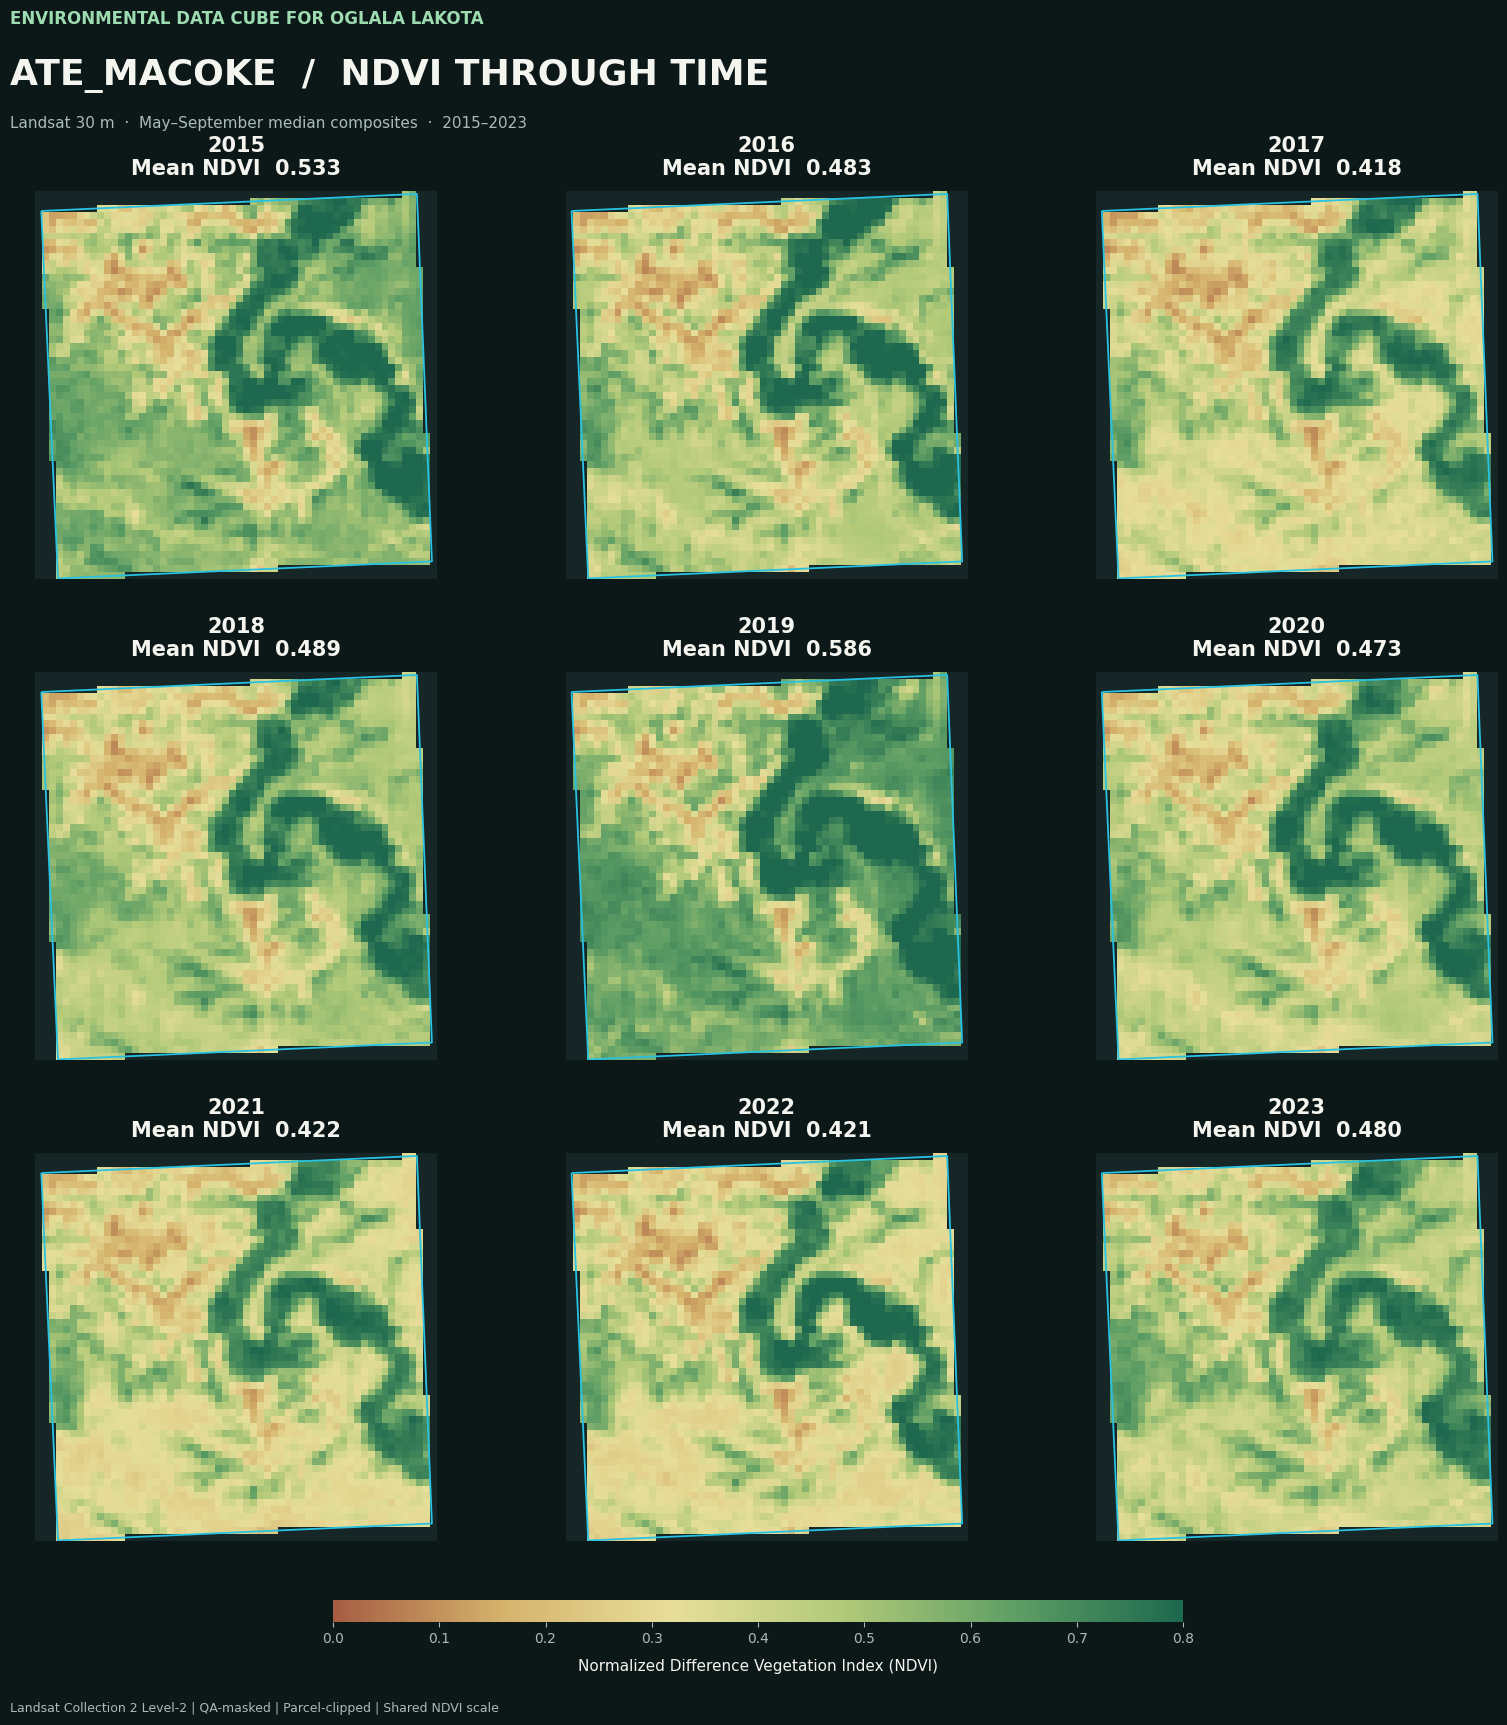


NINE-YEAR LANDSAT ATLAS COMPLETE
PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Landsat_NDVI_2015_2023_Atlas.png
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Landsat_NDVI_2015_2023_Atlas.pdf
Original dissertation cube unchanged.


In [27]:

# ================================================================
# MAP 5 — ATE_MACOKE LANDSAT NDVI THROUGH TIME
# 2015–2023 | NINE-PANEL SPATIAL ATLAS
#
# Environmental Data Cube for Oglala Lakota
# Actual Landsat 30 m NDVI pixels
# Same design as the original three-panel figure
#
# Preserves existing raster and NetCDF files
# ================================================================

from pathlib import Path
import warnings
import numpy as np
import geopandas as gpd
import rasterio
from rasterio.features import geometry_mask
from rasterio.transform import from_origin
from rasterio.warp import reproject
from rasterio.enums import Resampling
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from pystac_client import Client
import planetary_computer as pc
import odc.stac

# ------------------------------------------------
# 1. PATHS AND STUDY YEARS
# ------------------------------------------------

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

out = project / "results/SA20_satellite_maps"
out.mkdir(parents=True, exist_ok=True)

parcel_path = project / "data/ate_parcel_wanzi.shp"

reference_path = (
    project
    / "outputs/sa16_16_ate_makoce_final/v01"
    / "ate_makoce_vegetation_trajectories_2019_2023.tif"
)

years = list(range(2015, 2024))

def raster_path(year):
    return out / (
        f"Ate_Macoke_Landsat_NDVI_"
        f"{year}_MaySep_Median_30m.tif"
    )

# ------------------------------------------------
# 2. REFERENCE GRID AND PARCEL MASK
# ------------------------------------------------

with rasterio.open(reference_path) as ref:
    profile = ref.profile.copy()
    transform = ref.transform
    crs = ref.crs
    height = ref.height
    width = ref.width
    bounds = ref.bounds

parcel = gpd.read_file(parcel_path).to_crs(crs)

inside = geometry_mask(
    list(parcel.geometry),
    out_shape=(height, width),
    transform=transform,
    invert=True
)

parcel_wgs84 = parcel.to_crs("EPSG:4326")
bbox = tuple(parcel_wgs84.total_bounds)

# ------------------------------------------------
# 3. FIND MISSING YEARS
# ------------------------------------------------

missing_years = [
    year for year in years
    if not raster_path(year).exists()
]

print("Existing years:",
      [y for y in years if y not in missing_years])

print("Years requiring Landsat processing:",
      missing_years)

# ------------------------------------------------
# 4. GENERATE ONLY MISSING LANDSAT COMPOSITES
# ------------------------------------------------

if missing_years:

    catalog = Client.open(
        "https://planetarycomputer.microsoft.com/api/stac/v1"
    )

    for year in missing_years:

        print(f"\nPROCESSING LANDSAT {year}")

        search = catalog.search(
            collections=["landsat-c2-l2"],
            bbox=bbox,
            datetime=f"{year}-05-01/{year}-09-30",
            query={"eo:cloud_cover": {"lt": 40}}
        )

        items = list(search.items())

        if not items:
            raise RuntimeError(
                f"No Landsat scenes found for {year}"
            )

        signed = [pc.sign(item) for item in items]

        ds = odc.stac.load(
            signed,
            bands=["red", "nir08", "qa_pixel"],
            bbox=bbox,
            crs=str(crs),
            resolution=30,
            groupby="solar_day",
            fail_on_error=False
        )

        red_dn = ds["red"].values
        nir_dn = ds["nir08"].values
        qa_dn = ds["qa_pixel"].values

        x = ds.x.values
        y = ds.y.values

        dx = abs(float(x[1] - x[0]))
        dy = abs(float(y[1] - y[0]))

        src_transform = from_origin(
            float(x.min()) - dx / 2,
            float(y.max()) + dy / 2,
            dx,
            dy
        )

        scenes = []

        for i in range(red_dn.shape[0]):

            red = (
                red_dn[i].astype("float32")
                * 0.0000275 - 0.2
            )

            nir = (
                nir_dn[i].astype("float32")
                * 0.0000275 - 0.2
            )

            qa = qa_dn[i].astype("uint16")

            clear = (qa & 0b111111) == 0
            denominator = nir + red

            valid = (
                clear
                & np.isfinite(red)
                & np.isfinite(nir)
                & (red > 0)
                & (nir > 0)
                & (denominator != 0)
            )

            ndvi = np.full(
                red.shape,
                np.nan,
                dtype="float32"
            )

            ndvi[valid] = (
                (nir[valid] - red[valid])
                / denominator[valid]
            )

            ndvi[
                (ndvi < -1) | (ndvi > 1)
            ] = np.nan

            aligned = np.full(
                (height, width),
                np.nan,
                dtype="float32"
            )

            reproject(
                source=ndvi,
                destination=aligned,
                src_transform=src_transform,
                src_crs=crs,
                dst_transform=transform,
                dst_crs=crs,
                src_nodata=np.nan,
                dst_nodata=np.nan,
                resampling=Resampling.nearest
            )

            aligned[~inside] = np.nan
            scenes.append(aligned)

        with warnings.catch_warnings():
            warnings.filterwarnings(
                "ignore",
                message="All-NaN slice encountered"
            )

            composite = np.nanmedian(
                np.stack(scenes),
                axis=0
            ).astype("float32")

        composite[~inside] = np.nan

        if not np.isfinite(composite).any():
            raise RuntimeError(
                f"No valid NDVI pixels for {year}"
            )

        output = raster_path(year)

        save_profile = profile.copy()
        save_profile.update(
            driver="GTiff",
            count=1,
            dtype="float32",
            nodata=-9999.0,
            compress="deflate"
        )

        with rasterio.open(
            output, "w", **save_profile
        ) as dst:

            dst.write(
                np.where(
                    np.isfinite(composite),
                    composite,
                    -9999.0
                ).astype("float32"),
                1
            )

            dst.update_tags(
                year=str(year),
                sensor="Landsat Collection 2 Level-2",
                composite="May–September median NDVI",
                scene_count=str(len(scenes))
            )

        print(
            f"Saved {year}: "
            f"mean NDVI {np.nanmean(composite):.3f}"
        )

# ------------------------------------------------
# 5. LOAD ALL NINE LANDSAT RASTERS
# ------------------------------------------------

maps = {}
means = {}

for year in years:

    with rasterio.open(raster_path(year)) as src:

        if (
            src.crs != crs
            or src.transform != transform
            or src.shape != (height, width)
        ):
            raise ValueError(
                f"Grid mismatch for {year}"
            )

        arr = src.read(1, masked=True).filled(
            np.nan
        ).astype("float32")

        arr[~inside] = np.nan

        maps[year] = arr
        means[year] = float(np.nanmean(arr))

# ------------------------------------------------
# 6. MATCH ORIGINAL DARK LANDSAT ATLAS STYLE
# ------------------------------------------------

cmap = LinearSegmentedColormap.from_list(
    "Ate_Macoke_NDVI",
    [
        "#A65D43",
        "#D5B36C",
        "#E7DE9A",
        "#B2CA79",
        "#5F9F65",
        "#1D684E"
    ],
    N=256
)

cmap.set_bad("#162526")

norm = Normalize(vmin=0.0, vmax=0.8)

bg = "#0C1718"
fg = "#F4F5EF"
muted = "#AABCB7"
cyan = "#28C2E2"

# ------------------------------------------------
# 7. CREATE NINE-PANEL ATLAS
# ------------------------------------------------

fig, axes = plt.subplots(
    3, 3,
    figsize=(17, 18),
    facecolor=bg
)

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]

for ax, year in zip(axes.flat, years):

    ax.set_facecolor(bg)

    ax.imshow(
        maps[year],
        extent=extent,
        origin="upper",
        cmap=cmap,
        norm=norm,
        interpolation="nearest"
    )

    parcel.boundary.plot(
        ax=ax,
        color=cyan,
        linewidth=1.3
    )

    ax.set_xlim(bounds.left, bounds.right)
    ax.set_ylim(bounds.bottom, bounds.top)
    ax.set_aspect("equal")
    ax.axis("off")

    ax.set_title(
        f"{year}\nMean NDVI  {means[year]:.3f}",
        color=fg,
        fontsize=15,
        weight="bold",
        pad=12
    )

fig.text(
    0.06, 0.963,
    "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA",
    color="#9DDBB0",
    fontsize=12,
    weight="bold"
)

fig.text(
    0.06, 0.929,
    "ATE_MACOKE  /  NDVI THROUGH TIME",
    color=fg,
    fontsize=26,
    weight="bold"
)

fig.text(
    0.06, 0.905,
    "Landsat 30 m  ·  May–September median composites  ·  2015–2023",
    color=muted,
    fontsize=11
)

fig.subplots_adjust(
    left=0.05,
    right=0.96,
    top=0.87,
    bottom=0.12,
    wspace=0.09,
    hspace=0.24
)

# ------------------------------------------------
# 8. SHARED NDVI COLOR BAR
# ------------------------------------------------

sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cax = fig.add_axes([
    0.25, 0.075, 0.50, 0.012
])

cb = fig.colorbar(
    sm,
    cax=cax,
    orientation="horizontal"
)

cb.set_label(
    "Normalized Difference Vegetation Index (NDVI)",
    color=fg,
    fontsize=11,
    labelpad=9
)

cb.ax.tick_params(colors=muted)
cb.outline.set_visible(False)

fig.text(
    0.06, 0.025,
    (
        "Landsat Collection 2 Level-2 | "
        "QA-masked | Parcel-clipped | "
        "Shared NDVI scale"
    ),
    color=muted,
    fontsize=9
)

# ------------------------------------------------
# 9. SAVE WITHOUT OVERWRITING
# ------------------------------------------------

png_path = (
    out / "Ate_Macoke_Landsat_NDVI_2015_2023_Atlas.png"
)

pdf_path = (
    out / "Ate_Macoke_Landsat_NDVI_2015_2023_Atlas.pdf"
)

for path in (png_path, pdf_path):
    if path.exists():
        raise FileExistsError(
            f"Existing atlas preserved: {path}"
        )

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=bg
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor=bg
)

plt.show()

print("\nNINE-YEAR LANDSAT ATLAS COMPLETE")
print("PNG:", png_path)
print("PDF:", pdf_path)
print("Original dissertation cube unchanged.")


In [29]:

# ================================================================
# ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
# MAP 5 — ORIGINAL LANDSAT SPATIAL DATA DISCOVERY
#
# Objective:
# Find existing Landsat NDVI spatial layers associated
# with the dissertation data cube for 2015–2023.
#
# READ ONLY:
# - No downloads
# - No NDVI recalculation
# - No file modification
# - No source data overwritten
# ================================================================

from pathlib import Path
import numpy as np
import xarray as xr
import rasterio
import pandas as pd

# ------------------------------------------------
# 1. PROJECT LOCATIONS
# ------------------------------------------------

workspace = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026"
)

project = workspace / "ate_makoce_agcube"

dissertation_cube = (
    project
    / "Notebooks/environmental_data_cube_oglala_lakota_dissertation.nc"
)

years = list(range(2015, 2024))

print("=" * 80)
print("ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA")
print("ORIGINAL LANDSAT SPATIAL DATA DISCOVERY")
print("=" * 80)

# ------------------------------------------------
# 2. INSPECT DISSERTATION DATA CUBE
# ------------------------------------------------

print("\n" + "=" * 80)
print("1. DISSERTATION DATA CUBE")
print("=" * 80)

with xr.open_dataset(dissertation_cube) as ds:

    print("\nDimensions:")
    print(dict(ds.sizes))

    print("\nDataset metadata:")
    for key, value in ds.attrs.items():
        print(f"  {key}: {value}")

    print("\nAll variables:")

    for name, da in ds.data_vars.items():

        print(
            f"  {name:<35} "
            f"dims={da.dims} "
            f"shape={da.shape}"
        )

        if any(
            term in name.lower()
            for term in ["landsat", "ndvi", "spatial"]
        ):
            if da.attrs:
                print("    Metadata:", dict(da.attrs))

    spatial_vars = [
        name
        for name, da in ds.data_vars.items()
        if (
            any(dim in da.dims for dim in ["x", "lon"])
            and any(dim in da.dims for dim in ["y", "lat"])
        )
    ]

    print("\nSpatial variables inside dissertation cube:")
    print(spatial_vars if spatial_vars else "None found")

# ------------------------------------------------
# 3. INVENTORY EXISTING SPATIAL FILES
# ------------------------------------------------

print("\n" + "=" * 80)
print("2. EXISTING SPATIAL RASTER FILES")
print("=" * 80)

raster_extensions = {
    ".tif", ".tiff", ".img", ".vrt"
}

raster_files = sorted(
    path
    for path in workspace.rglob("*")
    if (
        path.is_file()
        and path.suffix.lower() in raster_extensions
    )
)

print("\nRaster files found:", len(raster_files))

raster_records = []

for path in raster_files:

    try:
        with rasterio.open(path) as src:

            tags = src.tags()

            name_lower = path.name.lower()

            likely_ndvi = (
                "ndvi" in name_lower
                or "ndvi" in str(tags).lower()
                or any(
                    "ndvi" in (desc or "").lower()
                    for desc in src.descriptions
                )
            )

            # Inspect metadata only; avoid reading
            # large raster arrays into memory.
            record = {
                "file": str(path.relative_to(workspace)),
                "bands": src.count,
                "width": src.width,
                "height": src.height,
                "crs": str(src.crs),
                "resolution": str(src.res),
                "likely_ndvi": likely_ndvi,
                "tags": tags
            }

            raster_records.append(record)

            print("\nFILE:", record["file"])
            print("  Shape:", src.height, "x", src.width)
            print("  Bands:", src.count)
            print("  CRS:", src.crs)
            print("  Resolution:", src.res)
            print("  NDVI candidate:", likely_ndvi)

            if tags:
                print("  Metadata:", tags)

            if any(src.descriptions):
                print(
                    "  Band descriptions:",
                    src.descriptions
                )

    except Exception as exc:

        print(
            "\nCould not inspect:",
            path.name,
            str(exc)[:120]
        )

# ------------------------------------------------
# 4. INSPECT SPATIAL NETCDF VARIABLES
# ------------------------------------------------

print("\n" + "=" * 80)
print("3. SPATIAL NETCDF DATASETS")
print("=" * 80)

nc_files = sorted(workspace.rglob("*.nc"))

spatial_nc_records = []

for path in nc_files:

    try:

        with xr.open_dataset(path) as ds:

            for name, da in ds.data_vars.items():

                if not any(
                    keyword in name.lower()
                    for keyword in [
                        "ndvi",
                        "landsat",
                        "red",
                        "nir"
                    ]
                ):
                    continue

                spatial_dims = [
                    d for d in da.dims
                    if d.lower() in [
                        "x", "y", "lat",
                        "lon", "latitude",
                        "longitude"
                    ]
                ]

                if len(spatial_dims) < 2:
                    continue

                record = {
                    "file": str(
                        path.relative_to(workspace)
                    ),
                    "variable": name,
                    "dimensions": da.dims,
                    "shape": da.shape,
                    "metadata": dict(da.attrs)
                }

                spatial_nc_records.append(record)

                print("\nFILE:", record["file"])
                print("  Variable:", name)
                print("  Dimensions:", da.dims)
                print("  Shape:", da.shape)
                print("  Metadata:", da.attrs)

    except Exception as exc:

        print(
            "\nCould not inspect NetCDF:",
            path.name,
            str(exc)[:120]
        )

# ------------------------------------------------
# 5. SEARCH EXISTING NOTEBOOKS FOR DATA LINEAGE
# ------------------------------------------------

print("\n" + "=" * 80)
print("4. LANDSAT PROCESSING AND OUTPUT REFERENCES")
print("=" * 80)

import json

keywords = [
    "landsat_parcel_ndvi",
    "landsat_ndvi",
    "ndvi_raster",
    "ndvi_composite",
    "ndvi_spatial",
    "landsat-c2-l2",
    "to_raster",
    "to_netcdf",
    "write_raster"
]

notebooks = sorted(workspace.rglob("*.ipynb"))

matches = []

for notebook in notebooks:

    try:

        with open(
            notebook,
            "r",
            encoding="utf-8"
        ) as f:
            nb = json.load(f)

        for cell_number, cell in enumerate(
            nb.get("cells", []), start=1
        ):

            if cell.get("cell_type") != "code":
                continue

            source = "".join(
                cell.get("source", [])
            )

            found = [
                word for word in keywords
                if word.lower() in source.lower()
            ]

            if not found:
                continue

            # Extract lines mentioning NDVI,
            # raster saving, or source files.
            relevant_lines = [
                line.strip()
                for line in source.splitlines()
                if any(
                    term in line.lower()
                    for term in [
                        "ndvi",
                        ".tif",
                        ".nc",
                        "landsat",
                        "raster"
                    ]
                )
            ]

            matches.append({
                "notebook": str(
                    notebook.relative_to(workspace)
                ),
                "cell": cell_number,
                "keywords": found,
                "lines": relevant_lines[:12]
            })

    except Exception as exc:
        print(
            "Could not inspect notebook:",
            notebook.name,
            str(exc)[:100]
        )

print("\nMatching notebook cells:", len(matches))

for match in matches:

    print("\nNOTEBOOK:", match["notebook"])
    print("CELL POSITION:", match["cell"])
    print("KEYWORDS:", ", ".join(match["keywords"]))

    for line in match["lines"]:
        print("  ", line[:180])

# ------------------------------------------------
# 6. DISCOVERY SUMMARY
# ------------------------------------------------

print("\n" + "=" * 80)
print("5. DISCOVERY SUMMARY")
print("=" * 80)

ndvi_rasters = [
    r for r in raster_records
    if r["likely_ndvi"]
]

print("Total raster files:", len(raster_records))
print("Potential NDVI raster files:", len(ndvi_rasters))
print("Spatial NetCDF variables:", len(spatial_nc_records))
print("Notebook processing references:", len(matches))

print("\nPOTENTIAL NDVI RASTERS:")

if ndvi_rasters:

    for record in ndvi_rasters:
        print("  ", record["file"])

else:
    print("  No NDVI-labeled rasters found.")

print("\nPOTENTIAL SPATIAL NETCDF VARIABLES:")

if spatial_nc_records:

    for record in spatial_nc_records:
        print(
            "  ",
            record["file"],
            "::",
            record["variable"]
        )

else:
    print("  No matching spatial NetCDF variables found.")

print("\n" + "=" * 80)
print("READ-ONLY DISCOVERY COMPLETE")
print("ORIGINAL DISSERTATION DATA CUBE UNCHANGED")
print("=" * 80)


ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
ORIGINAL LANDSAT SPATIAL DATA DISCOVERY

1. DISSERTATION DATA CUBE

Dimensions:
{'year': 3}

Dataset metadata:
  title: Environmental Data Cube for Oglala Lakota
  component: Dissertation Integrated Analysis
  study_period: 2019, 2022, 2023
  governance: Oglala Lakota Nation - Tribal Data Sovereignty
  spatial_support: Parcel-level Landsat observations, reservation-scale MODIS EVI, and climate context
  climate_provenance_status: Geographic extraction documentation unresolved
  interpretation: Descriptive environmental comparisons; no grazing causation inferred

All variables:
  landsat_parcel_ndvi                 dims=('year',) shape=(3,)
    Metadata: {'units': '1', 'description': 'Mean Landsat NDVI over the analyzed parcel pixels'}
  landsat_parcel_ndmi                 dims=('year',) shape=(3,)
    Metadata: {'units': '1', 'description': 'Mean Landsat NDMI over the analyzed parcel pixels'}
  reservation_evi                     dims=('year',)

In [30]:

# =====================================================================
# ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
# ATE_MACOKE — VEGETATION CHANGE & LOW-GREENNESS PERSISTENCE ATLAS
#
# MAP A: Landsat NDVI Gain / Loss, 2015–2023
# MAP B: Persistent Low Greenness, 2015–2023
#
# DATA: Existing 30 m Landsat NDVI GeoTIFFs only
#
# SAFE:
#   - No satellite downloads
#   - No NDVI recomputation from spectral bands
#   - No changes to the original dissertation cube
#   - No changes to Notebook 09
#   - No overwriting existing outputs
# =====================================================================

from pathlib import Path
from datetime import datetime
import csv

import numpy as np
import rasterio
from rasterio.features import geometry_mask
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import (
    ListedColormap,
    BoundaryNorm,
    Normalize
)
from matplotlib.patches import Patch
from matplotlib.colors import to_rgba

# ---------------------------------------------------------------------
# 1. PROJECT PATHS AND ANALYSIS SETTINGS
# ---------------------------------------------------------------------

project = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

source_dir = project / "results" / "SA20_satellite_maps"
parcel_path = project / "data" / "ate_parcel_wanzi.shp"

years = list(range(2015, 2024))

LOW_NDVI_THRESHOLD = 0.30
MIN_LOW_YEARS = 5
MIN_VALID_YEARS = 5

# Map A classification thresholds:
# Strong loss:       delta < -0.10
# Moderate loss:    -0.10 <= delta < -0.05
# Relatively stable:-0.05 <= delta <= +0.05
# Moderate gain:    +0.05 < delta <= +0.10
# Strong gain:       delta > +0.10

raster_paths = {
    year: source_dir / (
        f"Ate_Macoke_Landsat_NDVI_"
        f"{year}_MaySep_Median_30m.tif"
    )
    for year in years
}

# ---------------------------------------------------------------------
# 2. VERIFY ALL NINE SOURCE RASTERS EXIST
# ---------------------------------------------------------------------

missing = [
    str(path)
    for path in raster_paths.values()
    if not path.is_file()
]

if missing:
    raise FileNotFoundError(
        "Missing required Landsat NDVI raster(s):\n"
        + "\n".join(missing)
    )

if not parcel_path.is_file():
    raise FileNotFoundError(
        f"Parcel boundary not found:\n{parcel_path}"
    )

print("=" * 78)
print("ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA")
print("ATE_MACOKE — VEGETATION CHANGE & PERSISTENCE")
print("=" * 78)
print("\nSource imagery: Existing Landsat NDVI GeoTIFFs")
print("Study period: 2015–2023")
print("Low NDVI threshold:", LOW_NDVI_THRESHOLD)
print("Minimum low years:", MIN_LOW_YEARS)
print("Minimum valid years:", MIN_VALID_YEARS)

# ---------------------------------------------------------------------
# 3. READ RASTERS AND CHECK GRID ALIGNMENT
# ---------------------------------------------------------------------

arrays = []
source_info = []
reference = None

for year in years:

    path = raster_paths[year]

    with rasterio.open(path) as src:

        if src.count != 1:
            raise ValueError(
                f"{year}: Expected a single-band NDVI raster."
            )

        if reference is None:

            reference = {
                "crs": src.crs,
                "transform": src.transform,
                "shape": src.shape,
                "bounds": src.bounds,
                "res": src.res,
                "profile": src.profile.copy()
            }

            if reference["crs"] is None:
                raise ValueError(
                    "Reference raster has no CRS."
                )

            if not reference["crs"].is_projected:
                raise ValueError(
                    "A projected CRS is required "
                    "for reliable area calculations."
                )

        else:

            aligned = (
                src.crs == reference["crs"]
                and src.shape == reference["shape"]
                and np.allclose(
                    tuple(src.transform),
                    tuple(reference["transform"]),
                    rtol=0,
                    atol=1e-7
                )
            )

            if not aligned:
                raise ValueError(
                    f"Raster grid mismatch for {year}:\n{path}\n"
                    "Stopped without resampling or modifying data."
                )

        data = src.read(1, masked=True)

        arr = np.asarray(
            data.filled(np.nan),
            dtype=np.float32
        )

        # NDVI's physically defined range is [-1, 1].
        # Invalid values become missing observations.
        invalid = (
            ~np.isfinite(arr)
            | (arr < -1.0)
            | (arr > 1.0)
        )

        arr[invalid] = np.nan

        arrays.append(arr)

        source_info.append({
            "year": year,
            "filename": path.name,
            "valid_raster_pixels": int(
                np.isfinite(arr).sum()
            ),
            "scene_count": src.tags().get(
                "scene_count", "not recorded"
            )
        })

stack = np.stack(arrays, axis=0)

height, width = reference["shape"]
transform = reference["transform"]
bounds = reference["bounds"]

print("\nRaster alignment: PASSED")
print("Dimensions:", stack.shape)
print("CRS:", reference["crs"])
print("Pixel resolution:", reference["res"])

# ---------------------------------------------------------------------
# 4. PARCEL BOUNDARY AND PIXEL MASK
# ---------------------------------------------------------------------

parcel = gpd.read_file(parcel_path)

if parcel.empty:
    raise ValueError("Parcel boundary is empty.")

if parcel.crs is None:
    raise ValueError(
        "Parcel boundary CRS is missing."
    )

parcel = parcel.to_crs(reference["crs"])

if parcel.geometry.isna().any():
    raise ValueError(
        "Parcel boundary contains missing geometry."
    )

parcel = parcel[
    ~parcel.geometry.is_empty
].copy()

if parcel.empty:
    raise ValueError(
        "Parcel boundary has no usable geometry."
    )

# Include pixels whose centers lie within the parcel.
parcel_mask = geometry_mask(
    parcel.geometry,
    out_shape=(height, width),
    transform=transform,
    invert=True,
    all_touched=False
)

if not parcel_mask.any():
    raise ValueError(
        "No raster pixel centers fall inside the parcel."
    )

# Keep only parcel pixels in all nine annual arrays.
stack = np.where(
    parcel_mask[np.newaxis, :, :],
    stack,
    np.nan
)

# Confirm the CRS uses meters before converting
# pixel counts to hectares.
crs_units = [
    axis.unit_name.lower()
    for axis in reference["crs"].coordinate_system.axis_list
]

if not all("metre" in unit or "meter" in unit
           for unit in crs_units):
    raise ValueError(
        "Raster CRS units are not meters; "
        "hectare conversion stopped."
    )

pixel_area_m2 = abs(
    transform.a * transform.e
    - transform.b * transform.d
)

pixel_area_ha = pixel_area_m2 / 10000.0

print("\nParcel pixels:", int(parcel_mask.sum()))
print("Area per pixel (ha):", round(pixel_area_ha, 4))

# ---------------------------------------------------------------------
# 5. VALID OBSERVATION COUNTS
# ---------------------------------------------------------------------

valid = np.isfinite(stack)

valid_year_count = valid.sum(axis=0).astype(
    np.uint8
)

valid_by_year = {
    year: int(valid[i].sum())
    for i, year in enumerate(years)
}

print("\nValid parcel pixels by year:")

for year, count in valid_by_year.items():
    print(f"  {year}: {count:,}")

# ---------------------------------------------------------------------
# 6. MAP A — VEGETATION GAIN AND LOSS
# ---------------------------------------------------------------------

ndvi_2015 = stack[0]
ndvi_2023 = stack[-1]

endpoint_valid = (
    parcel_mask
    & np.isfinite(ndvi_2015)
    & np.isfinite(ndvi_2023)
)

delta_ndvi = np.full(
    (height, width),
    np.nan,
    dtype=np.float32
)

delta_ndvi[endpoint_valid] = (
    ndvi_2023[endpoint_valid]
    - ndvi_2015[endpoint_valid]
)

# Classification codes:
# 1 strong loss
# 2 moderate loss
# 3 stable
# 4 moderate gain
# 5 strong gain
# 0 missing / outside parcel

change_class = np.zeros(
    (height, width),
    dtype=np.uint8
)

change_class[
    endpoint_valid & (delta_ndvi < -0.10)
] = 1

change_class[
    endpoint_valid
    & (delta_ndvi >= -0.10)
    & (delta_ndvi < -0.05)
] = 2

change_class[
    endpoint_valid
    & (delta_ndvi >= -0.05)
    & (delta_ndvi <= 0.05)
] = 3

change_class[
    endpoint_valid
    & (delta_ndvi > 0.05)
    & (delta_ndvi <= 0.10)
] = 4

change_class[
    endpoint_valid & (delta_ndvi > 0.10)
] = 5

# ---------------------------------------------------------------------
# 7. MAP B — PERSISTENT LOW GREENNESS
# ---------------------------------------------------------------------

low_ndvi = (
    valid
    & (stack < LOW_NDVI_THRESHOLD)
)

low_year_count = low_ndvi.sum(
    axis=0
).astype(np.uint8)

sufficient_observations = (
    parcel_mask
    & (valid_year_count >= MIN_VALID_YEARS)
)

persistent_low = (
    sufficient_observations
    & (low_year_count >= MIN_LOW_YEARS)
)

# Classification:
# 0 = outside parcel / insufficient data
# 1 = 0–1 low years
# 2 = 2–3 low years
# 3 = 4 low years
# 4 = 5–6 low years (persistent)
# 5 = 7–9 low years (persistent)

persistence_class = np.zeros(
    (height, width),
    dtype=np.uint8
)

persistence_class[
    sufficient_observations
    & (low_year_count <= 1)
] = 1

persistence_class[
    sufficient_observations
    & (low_year_count >= 2)
    & (low_year_count <= 3)
] = 2

persistence_class[
    sufficient_observations
    & (low_year_count == 4)
] = 3

persistence_class[
    sufficient_observations
    & (low_year_count >= 5)
    & (low_year_count <= 6)
] = 4

persistence_class[
    sufficient_observations
    & (low_year_count >= 7)
] = 5

# ---------------------------------------------------------------------
# 8. SUMMARIZE PIXELS AND HECTARES
# ---------------------------------------------------------------------

change_labels = {
    1: "Strong loss (< -0.10)",
    2: "Moderate loss (-0.10 to -0.05)",
    3: "Relatively stable (-0.05 to +0.05)",
    4: "Moderate gain (+0.05 to +0.10)",
    5: "Strong gain (> +0.10)"
}

persistence_labels = {
    1: "0–1 low years",
    2: "2–3 low years",
    3: "4 low years",
    4: "5–6 low years (persistent)",
    5: "7–9 low years (persistent)"
}

change_summary = []

for code, label in change_labels.items():

    count = int(
        (change_class == code).sum()
    )

    change_summary.append({
        "map": "Vegetation gain and loss",
        "class_code": code,
        "class_label": label,
        "pixel_count": count,
        "area_ha": count * pixel_area_ha
    })

persistence_summary = []

for code, label in persistence_labels.items():

    count = int(
        (persistence_class == code).sum()
    )

    persistence_summary.append({
        "map": "Low-greenness persistence",
        "class_code": code,
        "class_label": label,
        "pixel_count": count,
        "area_ha": count * pixel_area_ha
    })

change_missing = (
    parcel_mask & ~endpoint_valid
)

persistence_missing = (
    parcel_mask & ~sufficient_observations
)

print("\n" + "=" * 78)
print("MAP A — VEGETATION GAIN AND LOSS")
print("=" * 78)

for item in change_summary:
    print(
        f"{item['class_label']:<39}"
        f"{item['pixel_count']:>7,} pixels  "
        f"{item['area_ha']:>8.2f} ha"
    )

print(
    f"{'Insufficient endpoint data':<39}"
    f"{int(change_missing.sum()):>7,} pixels  "
    f"{change_missing.sum() * pixel_area_ha:>8.2f} ha"
)

print("\n" + "=" * 78)
print("MAP B — PERSISTENT LOW GREENNESS")
print("=" * 78)

for item in persistence_summary:
    print(
        f"{item['class_label']:<39}"
        f"{item['pixel_count']:>7,} pixels  "
        f"{item['area_ha']:>8.2f} ha"
    )

print(
    f"{'Insufficient valid years':<39}"
    f"{int(persistence_missing.sum()):>7,} pixels  "
    f"{persistence_missing.sum() * pixel_area_ha:>8.2f} ha"
)

persistent_count = int(persistent_low.sum())
persistent_area = persistent_count * pixel_area_ha

print("\nPersistent low-greenness pixels:", persistent_count)
print("Persistent low-greenness area (ha):",
      round(persistent_area, 2))

print(
    "Pixels with all nine valid years:",
    int((parcel_mask & (valid_year_count == 9)).sum())
)

# ---------------------------------------------------------------------
# 9. OUTPUT PATHS — NEVER OVERWRITE
# ---------------------------------------------------------------------

output_dir = (
    source_dir
    / "Ate_Macoke_Change_Persistence_Atlas"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

timestamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)

base = (
    "Ate_Macoke_Vegetation_Change_"
    "Persistence_2015_2023_" + timestamp
)

png_path = output_dir / f"{base}.png"
pdf_path = output_dir / f"{base}.pdf"

delta_path = output_dir / (
    f"{base}_NDVI_Difference.tif"
)

change_path = output_dir / (
    f"{base}_Change_Classes.tif"
)

persistence_path = output_dir / (
    f"{base}_Persistence_Classes.tif"
)

low_count_path = output_dir / (
    f"{base}_Low_Year_Count.tif"
)

valid_count_path = output_dir / (
    f"{base}_Valid_Year_Count.tif"
)

summary_path = output_dir / (
    f"{base}_Area_Summary.csv"
)

all_outputs = [
    png_path,
    pdf_path,
    delta_path,
    change_path,
    persistence_path,
    low_count_path,
    valid_count_path,
    summary_path
]

if any(p.exists() for p in all_outputs):
    raise FileExistsError(
        "An output filename already exists. "
        "Nothing will be overwritten."
    )

# ---------------------------------------------------------------------
# 10. WRITE GEOSPATIAL OUTPUTS
# ---------------------------------------------------------------------

def write_raster(
    path,
    data,
    dtype,
    nodata,
    description,
    tags=None
):

    profile = {
        "driver": "GTiff",
        "height": height,
        "width": width,
        "count": 1,
        "dtype": dtype,
        "crs": reference["crs"],
        "transform": transform,
        "nodata": nodata,
        "compress": "deflate"
    }

    with rasterio.open(
        path, "x", **profile
    ) as dst:

        dst.write(
            data.astype(dtype),
            1
        )

        dst.set_band_description(
            1, description
        )

        dst.update_tags(
            project=(
                "Environmental Data Cube "
                "for Oglala Lakota"
            ),
            study_area="Ate_Macoke",
            study_period="2015–2023",
            source="Existing Landsat NDVI GeoTIFFs",
            **(tags or {})
        )

# For float NDVI difference:
# -9999 indicates outside parcel or missing endpoints.
delta_export = np.where(
    endpoint_valid,
    delta_ndvi,
    -9999.0
).astype(np.float32)

write_raster(
    delta_path,
    delta_export,
    "float32",
    -9999.0,
    "NDVI change: 2023 minus 2015"
)

write_raster(
    change_path,
    change_class,
    "uint8",
    0,
    "Five-class NDVI gain/loss",
    {
        "thresholds": (
            "-0.10,-0.05,+0.05,+0.10"
        )
    }
)

write_raster(
    persistence_path,
    persistence_class,
    "uint8",
    0,
    "Low-greenness persistence classes",
    {
        "low_ndvi_threshold": str(
            LOW_NDVI_THRESHOLD
        ),
        "minimum_low_years": str(
            MIN_LOW_YEARS
        ),
        "minimum_valid_years": str(
            MIN_VALID_YEARS
        )
    }
)

write_raster(
    low_count_path,
    np.where(
        sufficient_observations,
        low_year_count,
        255
    ),
    "uint8",
    255,
    "Years with NDVI below 0.30"
)

write_raster(
    valid_count_path,
    np.where(
        parcel_mask,
        valid_year_count,
        255
    ),
    "uint8",
    255,
    "Number of valid annual NDVI observations"
)

with open(
    summary_path,
    "x",
    newline="",
    encoding="utf-8"
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=[
            "map",
            "class_code",
            "class_label",
            "pixel_count",
            "area_ha"
        ]
    )

    writer.writeheader()

    writer.writerows(
        change_summary
        + persistence_summary
        + [
            {
                "map": "Vegetation gain and loss",
                "class_code": 0,
                "class_label": (
                    "Insufficient endpoint data"
                ),
                "pixel_count": int(
                    change_missing.sum()
                ),
                "area_ha": float(
                    change_missing.sum()
                    * pixel_area_ha
                )
            },
            {
                "map": "Low-greenness persistence",
                "class_code": 0,
                "class_label": (
                    "Insufficient valid years"
                ),
                "pixel_count": int(
                    persistence_missing.sum()
                ),
                "area_ha": float(
                    persistence_missing.sum()
                    * pixel_area_ha
                )
            }
        ]
    )

# ---------------------------------------------------------------------
# 11. PROFESSIONAL DARK ATLAS DESIGN
# ---------------------------------------------------------------------

BG = "#0B1718"
PANEL = "#142326"
WHITE = "#F4F7F5"
MUTED = "#A8B9B7"
CYAN = "#39C7E4"

change_colors = [
    "#B44D45",  # Strong loss
    "#D99861",  # Moderate loss
    "#E3D6A0",  # Stable
    "#A2CB81",  # Moderate gain
    "#317E59"   # Strong gain
]

persistence_colors = [
    "#D8E4C7",  # 0–1 years
    "#B4C68E",  # 2–3 years
    "#E7C277",  # 4 years
    "#D8834C",  # 5–6 years
    "#A63D3A"   # 7–9 years
]

change_cmap = ListedColormap(
    change_colors
)

persistence_cmap = ListedColormap(
    persistence_colors
)

# Set missing pixels to the panel background.
change_cmap.set_bad(PANEL)
persistence_cmap.set_bad(PANEL)

class_norm = BoundaryNorm(
    np.arange(0.5, 6.5, 1),
    ncolors=5
)

change_display = np.ma.masked_where(
    change_class == 0,
    change_class
)

persistence_display = np.ma.masked_where(
    persistence_class == 0,
    persistence_class
)

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 10),
    facecolor=BG
)

fig.subplots_adjust(
    left=0.045,
    right=0.965,
    top=0.74,
    bottom=0.27,
    wspace=0.12
)

for ax in axes:

    ax.set_facecolor(PANEL)

    ax.set_aspect("equal")

    ax.set_xlim(
        bounds.left, bounds.right
    )

    ax.set_ylim(
        bounds.bottom, bounds.top
    )

    ax.axis("off")

# ---------------------------------------------------------------------
# 12. MAP A
# ---------------------------------------------------------------------

axes[0].imshow(
    change_display,
    extent=extent,
    origin="upper",
    cmap=change_cmap,
    norm=class_norm,
    interpolation="nearest"
)

parcel.boundary.plot(
    ax=axes[0],
    color=CYAN,
    linewidth=1.5,
    zorder=10
)

axes[0].set_title(
    "A  /  VEGETATION GAIN & LOSS\n"
    "2015 → 2023",
    color=WHITE,
    fontsize=16,
    fontweight="bold",
    pad=20
)

# ---------------------------------------------------------------------
# 13. MAP B
# ---------------------------------------------------------------------

axes[1].imshow(
    persistence_display,
    extent=extent,
    origin="upper",
    cmap=persistence_cmap,
    norm=class_norm,
    interpolation="nearest"
)

parcel.boundary.plot(
    ax=axes[1],
    color=CYAN,
    linewidth=1.5,
    zorder=10
)

axes[1].set_title(
    "B  /  PERSISTENT LOW GREENNESS\n"
    "2015–2023",
    color=WHITE,
    fontsize=16,
    fontweight="bold",
    pad=20
)

# ---------------------------------------------------------------------
# 14. ATLAS HEADER
# ---------------------------------------------------------------------

fig.text(
    0.055, 0.95,
    "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA",
    color="#A0DEB2",
    fontsize=12,
    fontweight="bold"
)

fig.text(
    0.055, 0.895,
    "ATE_MACOKE  /  VEGETATION CHANGE",
    color=WHITE,
    fontsize=25,
    fontweight="bold"
)

fig.text(
    0.055, 0.852,
    "LANDSAT 30 m  •  MAY–SEPTEMBER COMPOSITES  •  2015–2023",
    color=MUTED,
    fontsize=11
)

# ---------------------------------------------------------------------
# 15. LEGENDS
# ---------------------------------------------------------------------

change_legend = [
    Patch(
        facecolor=change_colors[i],
        edgecolor="none",
        label=label
    )
    for i, label in enumerate([
        "Strong loss",
        "Moderate loss",
        "Relatively stable",
        "Moderate gain",
        "Strong gain"
    ])
]

persistence_legend = [
    Patch(
        facecolor=persistence_colors[i],
        edgecolor="none",
        label=label
    )
    for i, label in enumerate([
        "0–1 low years",
        "2–3 low years",
        "4 low years",
        "5–6 low years",
        "7–9 low years"
    ])
]

legend_a = fig.legend(
    handles=change_legend,
    loc="lower left",
    bbox_to_anchor=(0.075, 0.095),
    frameon=False,
    ncol=1,
    fontsize=10,
    title="A  /  NDVI CHANGE CLASS"
)

legend_b = fig.legend(
    handles=persistence_legend,
    loc="lower left",
    bbox_to_anchor=(0.565, 0.095),
    frameon=False,
    ncol=1,
    fontsize=10,
    title="B  /  LOW-GREENNESS FREQUENCY"
)

for legend in [legend_a, legend_b]:

    legend.get_title().set_color(
        WHITE
    )

    legend.get_title().set_fontweight(
        "bold"
    )

    for text in legend.get_texts():
        text.set_color(MUTED)

# ---------------------------------------------------------------------
# 16. FIGURE FOOTNOTE
# ---------------------------------------------------------------------

fig.text(
    0.055, 0.035,
    (
        "A: ΔNDVI = NDVI2023 − NDVI2015  |  "
        "B: NDVI < 0.30 in ≥5 valid years  |  "
        "At least 5 annual observations required for B"
    ),
    color=MUTED,
    fontsize=9
)

fig.text(
    0.055, 0.015,
    (
        "30 m Landsat Collection 2 Level-2  |  "
        "Descriptive vegetation indicators; "
        "not direct evidence of grazing impacts"
    ),
    color=MUTED,
    fontsize=8
)

# ---------------------------------------------------------------------
# 17. SAVE ATLAS WITHOUT OVERWRITING
# ---------------------------------------------------------------------

with open(png_path, "xb") as f:
    fig.savefig(
        f,
        format="png",
        dpi=300,
        facecolor=BG,
        bbox_inches="tight"
    )

with open(pdf_path, "xb") as f:
    fig.savefig(
        f,
        format="pdf",
        facecolor=BG,
        bbox_inches="tight"
    )

plt.show()

# ---------------------------------------------------------------------
# 18. FINAL OUTPUT REPORT
# ---------------------------------------------------------------------

print("\n" + "=" * 78)
print("ATE_MACOKE DISSERTATION ATLAS COMPLETE")
print("=" * 78)

print("\nMAP A — 2015–2023")
print(
    "Valid change pixels:",
    int(endpoint_valid.sum())
)

print(
    "Mapped change area:",
    round(
        endpoint_valid.sum() * pixel_area_ha,
        2
    ),
    "ha"
)

print("\nMAP B — 2015–2023")
print(
    "Valid persistence pixels:",
    int(sufficient_observations.sum())
)

print(
    "Mapped persistence area:",
    round(
        sufficient_observations.sum() * pixel_area_ha,
        2
    ),
    "ha"
)

print(
    "Persistent low-greenness area:",
    round(persistent_area, 2),
    "ha"
)

print("\nFILES CREATED:")

for path in all_outputs:
    print(" ", path)

print("\nOriginal dissertation cube: UNCHANGED")
print("Notebook 09: UNCHANGED")
print("Original Landsat GeoTIFFs: UNCHANGED")
print("No imagery downloaded.")
print("=" * 78)


ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
ATE_MACOKE — VEGETATION CHANGE & PERSISTENCE

Source imagery: Existing Landsat NDVI GeoTIFFs
Study period: 2015–2023
Low NDVI threshold: 0.3
Minimum low years: 5
Minimum valid years: 5

Raster alignment: PASSED
Dimensions: (9, 56, 58)
CRS: EPSG:32613
Pixel resolution: (30.0, 30.0)


AttributeError: 'rasterio.crs.CRS' object has no attribute 'coordinate_system'

ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
ATE_MACOKE — VEGETATION CHANGE & PERSISTENCE ATLAS

All nine Landsat NDVI rasters found.

Raster alignment: PASSED
Stack dimensions: (9, 56, 58)
CRS: EPSG:32613
Resolution: (30.0, 30.0)

Parcel pixel count: 2878
Pixel area: 900.0 m²
Pixel area: 0.09 ha

Valid parcel NDVI pixels by year:
  2015: 2,878
  2016: 2,878
  2017: 2,878
  2018: 2,878
  2019: 2,878
  2020: 2,878
  2021: 2,878
  2022: 2,878
  2023: 2,878

MAP A — VEGETATION GAIN AND LOSS
---------------------------------------------------------------------------
Strong loss (< -0.10)                      756 pixels      68.04 ha
Moderate loss (-0.10 to -0.05)             630 pixels      56.70 ha
Relatively stable (-0.05 to +0.05)       1,363 pixels     122.67 ha
Moderate gain (+0.05 to +0.10)             123 pixels      11.07 ha
Strong gain (> +0.10)                        6 pixels       0.54 ha

MAP B — LOW-GREENNESS PERSISTENCE
-----------------------------------------------------------

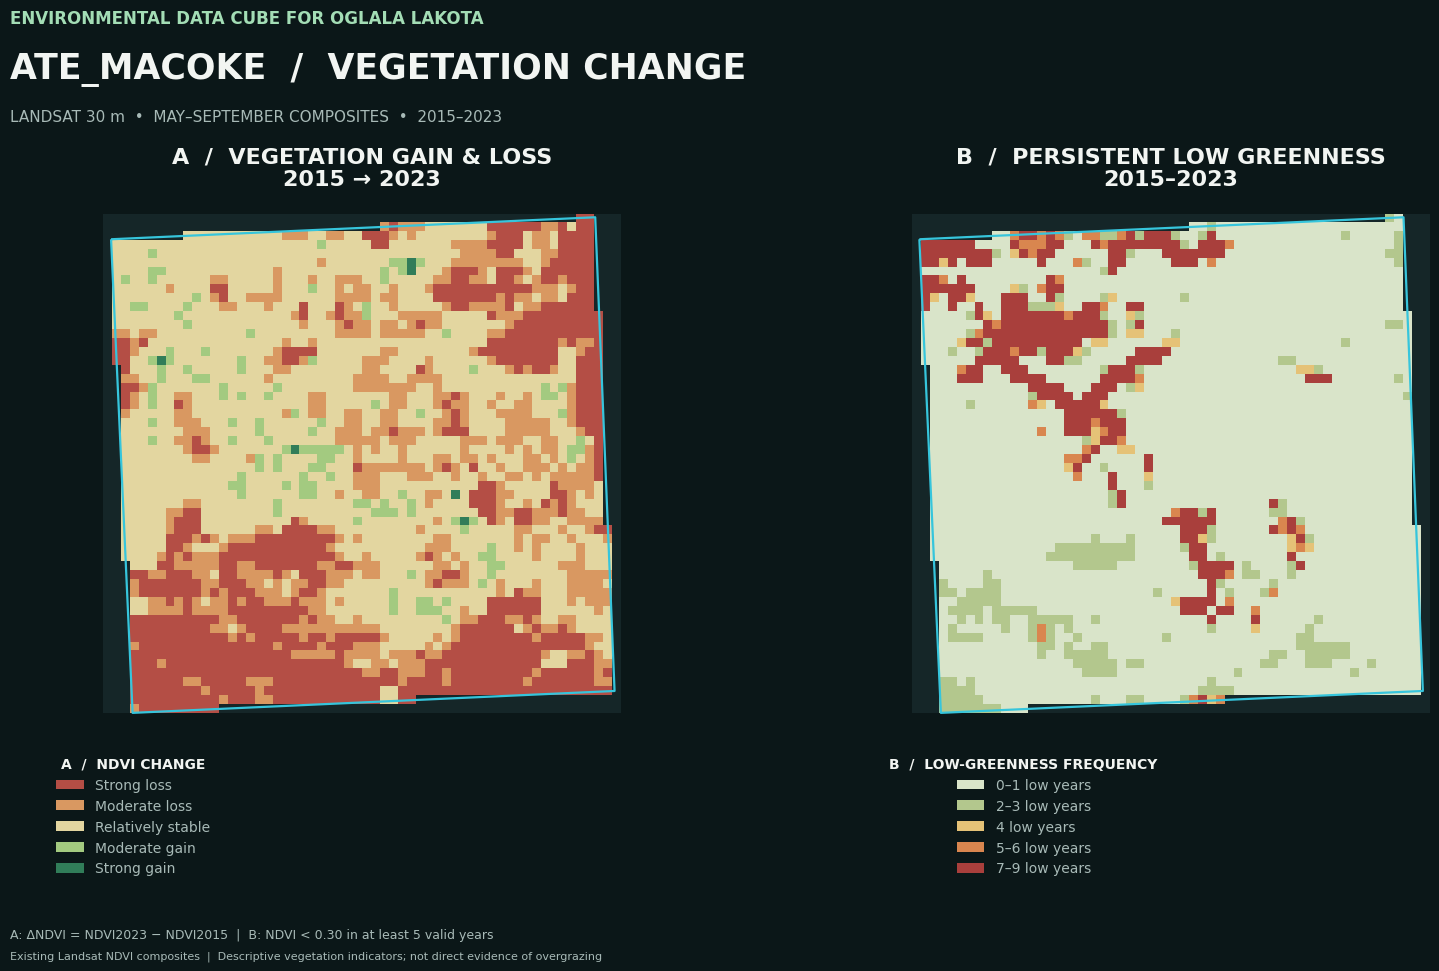


ATE_MACOKE ATLAS COMPLETE

MAP A — VEGETATION CHANGE
Mapped pixels: 2878
Mapped area: 259.02 ha

MAP B — LOW-GREENNESS PERSISTENCE
Mapped pixels: 2878
Mapped area: 259.02 ha
Persistent low-greenness pixels: 326
Persistent low-greenness area: 29.34 ha

OUTPUT FILES:
  /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Change_Persistence_Atlas/Ate_Macoke_Vegetation_Change_Persistence_2015_2023_20261016_202424_591282.png
  /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Change_Persistence_Atlas/Ate_Macoke_Vegetation_Change_Persistence_2015_2023_20261016_202424_591282.pdf
  /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Change_Persistence_Atlas/Ate_Macoke_Vegetation_Change_Persistence_2015_2023_20261016_202424_591282_NDVI_Difference.tif
  /Users/elishawakiny

In [31]:

# =====================================================================
# ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
# ATE_MACOKE — VEGETATION CHANGE & LOW-GREENNESS ATLAS
#
# MAP A: Landsat NDVI Gain / Loss (2015–2023)
# MAP B: Persistent Low Greenness (2015–2023)
#
# INPUT: Nine existing 30 m Landsat NDVI GeoTIFFs
#
# This cell:
#   1. Checks all nine rasters and their spatial alignment
#   2. Clips analysis to the Ate_Macoke parcel
#   3. Calculates 2015–2023 NDVI change
#   4. Counts years with NDVI below 0.30
#   5. Creates a professional dark-background two-panel atlas
#   6. Reports mapped pixels and hectares
#   7. Saves PNG, PDF, GeoTIFFs, and CSV
#
# Original dissertation cube and Notebook 09 remain unchanged.
# No downloads. No overwriting.
# =====================================================================

from pathlib import Path
from datetime import datetime
import csv

import numpy as np
import rasterio
from rasterio.features import geometry_mask
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# =====================================================================
# 1. PROJECT PATHS
# =====================================================================

project = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

source_dir = project / "results" / "SA20_satellite_maps"

parcel_path = (
    project / "data" / "ate_parcel_wanzi.shp"
)

years = list(range(2015, 2024))

LOW_NDVI_THRESHOLD = 0.30
MIN_LOW_YEARS = 5
MIN_VALID_YEARS = 5

raster_paths = {
    year: (
        source_dir
        / f"Ate_Macoke_Landsat_NDVI_{year}_MaySep_Median_30m.tif"
    )
    for year in years
}

print("=" * 75)
print("ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA")
print("ATE_MACOKE — VEGETATION CHANGE & PERSISTENCE ATLAS")
print("=" * 75)

# =====================================================================
# 2. VERIFY SOURCE FILES
# =====================================================================

missing = [
    str(path)
    for path in raster_paths.values()
    if not path.is_file()
]

if missing:
    raise FileNotFoundError(
        "Missing Landsat NDVI rasters:\n"
        + "\n".join(missing)
    )

if not parcel_path.is_file():
    raise FileNotFoundError(
        f"Parcel shapefile not found:\n{parcel_path}"
    )

print("\nAll nine Landsat NDVI rasters found.")

# =====================================================================
# 3. READ RASTERS AND VERIFY SPATIAL ALIGNMENT
# =====================================================================

arrays = []
reference = None

for year in years:

    path = raster_paths[year]

    with rasterio.open(path) as src:

        if src.count != 1:
            raise ValueError(
                f"{year}: Expected a single-band NDVI raster."
            )

        if reference is None:

            reference = {
                "crs": src.crs,
                "transform": src.transform,
                "shape": src.shape,
                "bounds": src.bounds,
                "resolution": src.res
            }

            if reference["crs"] is None:
                raise ValueError(
                    "Reference raster has no CRS."
                )

            # FIXED CRS CHECK:
            # EPSG:32613 is UTM Zone 13N, in meters.
            if reference["crs"].to_epsg() != 32613:
                raise ValueError(
                    "Expected EPSG:32613, but found "
                    f"{reference['crs']}"
                )

        else:

            aligned = (
                src.crs == reference["crs"]
                and src.shape == reference["shape"]
                and np.allclose(
                    tuple(src.transform),
                    tuple(reference["transform"]),
                    rtol=0,
                    atol=1e-7
                )
            )

            if not aligned:
                raise ValueError(
                    f"Spatial grid mismatch in {year}.\n"
                    "Stopped without resampling."
                )

        data = src.read(1, masked=True)

        arr = np.asarray(
            data.filled(np.nan),
            dtype=np.float32
        )

        invalid = (
            ~np.isfinite(arr)
            | (arr < -1.0)
            | (arr > 1.0)
        )

        arr[invalid] = np.nan

        arrays.append(arr)

stack = np.stack(arrays, axis=0)

height, width = reference["shape"]
transform = reference["transform"]
bounds = reference["bounds"]

print("\nRaster alignment: PASSED")
print("Stack dimensions:", stack.shape)
print("CRS:", reference["crs"])
print("Resolution:", reference["resolution"])

# =====================================================================
# 4. PARCEL BOUNDARY AND PIXEL AREA
# =====================================================================

parcel = gpd.read_file(parcel_path)

if parcel.empty:
    raise ValueError(
        "Parcel boundary is empty."
    )

if parcel.crs is None:
    raise ValueError(
        "Parcel shapefile has no CRS."
    )

parcel = parcel.to_crs(
    reference["crs"]
)

parcel = parcel[
    parcel.geometry.notna()
    & ~parcel.geometry.is_empty
].copy()

if parcel.empty:
    raise ValueError(
        "Parcel contains no usable geometry."
    )

parcel_mask = geometry_mask(
    parcel.geometry,
    out_shape=(height, width),
    transform=transform,
    invert=True,
    all_touched=False
)

if not parcel_mask.any():
    raise ValueError(
        "No raster pixel centers fall within the parcel."
    )

# Restrict all years to parcel pixels.
stack = np.where(
    parcel_mask[np.newaxis, :, :],
    stack,
    np.nan
)

# EPSG:32613 uses meters.
# Calculate pixel area directly from affine transform.
pixel_area_m2 = abs(
    transform.a * transform.e
    - transform.b * transform.d
)

pixel_area_ha = (
    pixel_area_m2 / 10000.0
)

print("\nParcel pixel count:", int(parcel_mask.sum()))
print("Pixel area:", pixel_area_m2, "m²")
print("Pixel area:", pixel_area_ha, "ha")

# =====================================================================
# 5. COUNT VALID ANNUAL OBSERVATIONS
# =====================================================================

valid = np.isfinite(stack)

valid_year_count = (
    valid.sum(axis=0).astype(np.uint8)
)

print("\nValid parcel NDVI pixels by year:")

for i, year in enumerate(years):

    count = int(valid[i].sum())

    print(f"  {year}: {count:,}")

# =====================================================================
# 6. MAP A — NDVI GAIN AND LOSS
# =====================================================================

ndvi_2015 = stack[0]
ndvi_2023 = stack[-1]

endpoint_valid = (
    parcel_mask
    & np.isfinite(ndvi_2015)
    & np.isfinite(ndvi_2023)
)

delta_ndvi = np.full(
    (height, width),
    np.nan,
    dtype=np.float32
)

delta_ndvi[endpoint_valid] = (
    ndvi_2023[endpoint_valid]
    - ndvi_2015[endpoint_valid]
)

# Change classes:
#
# 1 = Strong loss
# 2 = Moderate loss
# 3 = Relatively stable
# 4 = Moderate gain
# 5 = Strong gain
# 0 = Missing / outside parcel

change_class = np.zeros(
    (height, width),
    dtype=np.uint8
)

change_class[
    endpoint_valid
    & (delta_ndvi < -0.10)
] = 1

change_class[
    endpoint_valid
    & (delta_ndvi >= -0.10)
    & (delta_ndvi < -0.05)
] = 2

change_class[
    endpoint_valid
    & (delta_ndvi >= -0.05)
    & (delta_ndvi <= 0.05)
] = 3

change_class[
    endpoint_valid
    & (delta_ndvi > 0.05)
    & (delta_ndvi <= 0.10)
] = 4

change_class[
    endpoint_valid
    & (delta_ndvi > 0.10)
] = 5

# =====================================================================
# 7. MAP B — PERSISTENT LOW GREENNESS
# =====================================================================

low_ndvi = (
    valid
    & (stack < LOW_NDVI_THRESHOLD)
)

low_year_count = (
    low_ndvi.sum(axis=0).astype(np.uint8)
)

sufficient_observations = (
    parcel_mask
    & (valid_year_count >= MIN_VALID_YEARS)
)

persistent_low = (
    sufficient_observations
    & (low_year_count >= MIN_LOW_YEARS)
)

# Persistence classes:
#
# 1 = 0–1 low years
# 2 = 2–3 low years
# 3 = 4 low years
# 4 = 5–6 low years
# 5 = 7–9 low years
# 0 = Insufficient observations / outside parcel

persistence_class = np.zeros(
    (height, width),
    dtype=np.uint8
)

persistence_class[
    sufficient_observations
    & (low_year_count <= 1)
] = 1

persistence_class[
    sufficient_observations
    & (low_year_count >= 2)
    & (low_year_count <= 3)
] = 2

persistence_class[
    sufficient_observations
    & (low_year_count == 4)
] = 3

persistence_class[
    sufficient_observations
    & (low_year_count >= 5)
    & (low_year_count <= 6)
] = 4

persistence_class[
    sufficient_observations
    & (low_year_count >= 7)
] = 5

# =====================================================================
# 8. CLASS LABELS AND AREA SUMMARIES
# =====================================================================

change_labels = {
    1: "Strong loss (< -0.10)",
    2: "Moderate loss (-0.10 to -0.05)",
    3: "Relatively stable (-0.05 to +0.05)",
    4: "Moderate gain (+0.05 to +0.10)",
    5: "Strong gain (> +0.10)"
}

persistence_labels = {
    1: "0–1 low years",
    2: "2–3 low years",
    3: "4 low years",
    4: "5–6 low years (persistent)",
    5: "7–9 low years (persistent)"
}

summary_rows = []

def summarize_classes(
    map_name,
    class_array,
    labels
):

    print("\n" + map_name)
    print("-" * 75)

    for code, label in labels.items():

        count = int(
            np.count_nonzero(
                class_array == code
            )
        )

        area_ha = (
            count * pixel_area_ha
        )

        summary_rows.append({
            "map": map_name,
            "class_code": code,
            "class_label": label,
            "pixel_count": count,
            "area_ha": round(area_ha, 4)
        })

        print(
            f"{label:<39}"
            f"{count:>7,} pixels  "
            f"{area_ha:>9.2f} ha"
        )

summarize_classes(
    "MAP A — VEGETATION GAIN AND LOSS",
    change_class,
    change_labels
)

summarize_classes(
    "MAP B — LOW-GREENNESS PERSISTENCE",
    persistence_class,
    persistence_labels
)

change_missing = (
    parcel_mask & ~endpoint_valid
)

persistence_missing = (
    parcel_mask & ~sufficient_observations
)

for map_name, missing_mask, label in [
    (
        "MAP A — VEGETATION GAIN AND LOSS",
        change_missing,
        "Insufficient endpoint data"
    ),
    (
        "MAP B — LOW-GREENNESS PERSISTENCE",
        persistence_missing,
        "Insufficient valid years"
    )
]:

    count = int(missing_mask.sum())

    summary_rows.append({
        "map": map_name,
        "class_code": 0,
        "class_label": label,
        "pixel_count": count,
        "area_ha": round(
            count * pixel_area_ha, 4
        )
    })

    print(
        f"\n{label}: {count:,} pixels "
        f"({count * pixel_area_ha:.2f} ha)"
    )

persistent_count = int(
    persistent_low.sum()
)

persistent_area_ha = (
    persistent_count * pixel_area_ha
)

print("\n" + "=" * 75)
print("PERSISTENT LOW GREENNESS")
print("=" * 75)

print(
    "NDVI threshold:",
    LOW_NDVI_THRESHOLD
)

print(
    "Minimum low years:",
    MIN_LOW_YEARS
)

print(
    "Minimum valid years:",
    MIN_VALID_YEARS
)

print(
    "Persistent pixels:",
    persistent_count
)

print(
    "Persistent area:",
    round(persistent_area_ha, 2),
    "ha"
)

# =====================================================================
# 9. PREPARE SAFE OUTPUT DIRECTORY
# =====================================================================

output_dir = (
    source_dir
    / "Ate_Macoke_Change_Persistence_Atlas"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

timestamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)

base = (
    "Ate_Macoke_Vegetation_Change_"
    "Persistence_2015_2023_"
    + timestamp
)

png_path = output_dir / f"{base}.png"
pdf_path = output_dir / f"{base}.pdf"

delta_path = output_dir / (
    f"{base}_NDVI_Difference.tif"
)

change_path = output_dir / (
    f"{base}_Change_Classes.tif"
)

persistence_path = output_dir / (
    f"{base}_Persistence_Classes.tif"
)

low_count_path = output_dir / (
    f"{base}_Low_Year_Count.tif"
)

valid_count_path = output_dir / (
    f"{base}_Valid_Year_Count.tif"
)

summary_path = output_dir / (
    f"{base}_Area_Summary.csv"
)

output_paths = [
    png_path,
    pdf_path,
    delta_path,
    change_path,
    persistence_path,
    low_count_path,
    valid_count_path,
    summary_path
]

if any(path.exists() for path in output_paths):
    raise FileExistsError(
        "An output file already exists. "
        "Nothing will be overwritten."
    )

# =====================================================================
# 10. EXPORT GIS-READY GEOTIFFS
# =====================================================================

def save_geotiff(
    path,
    data,
    dtype,
    nodata,
    description,
    extra_tags=None
):

    profile = {
        "driver": "GTiff",
        "height": height,
        "width": width,
        "count": 1,
        "dtype": dtype,
        "crs": reference["crs"],
        "transform": transform,
        "nodata": nodata,
        "compress": "deflate"
    }

    with rasterio.open(
        path, "w", **profile
    ) as dst:

        dst.write(
            data.astype(dtype),
            1
        )

        dst.set_band_description(
            1, description
        )

        tags = {
            "project": (
                "Environmental Data Cube "
                "for Oglala Lakota"
            ),
            "study_area": "Ate_Macoke",
            "period": "2015-2023",
            "source": (
                "Existing Landsat NDVI "
                "annual GeoTIFFs"
            )
        }

        if extra_tags:
            tags.update(extra_tags)

        dst.update_tags(**tags)

delta_export = np.where(
    endpoint_valid,
    delta_ndvi,
    -9999.0
).astype(np.float32)

save_geotiff(
    delta_path,
    delta_export,
    "float32",
    -9999.0,
    "NDVI 2023 minus NDVI 2015"
)

save_geotiff(
    change_path,
    change_class,
    "uint8",
    0,
    "NDVI change classification"
)

save_geotiff(
    persistence_path,
    persistence_class,
    "uint8",
    0,
    "Low-greenness persistence classification",
    {
        "ndvi_threshold": str(
            LOW_NDVI_THRESHOLD
        ),
        "minimum_low_years": str(
            MIN_LOW_YEARS
        ),
        "minimum_valid_years": str(
            MIN_VALID_YEARS
        )
    }
)

save_geotiff(
    low_count_path,
    np.where(
        sufficient_observations,
        low_year_count,
        255
    ),
    "uint8",
    255,
    "Count of years NDVI below 0.30"
)

save_geotiff(
    valid_count_path,
    np.where(
        parcel_mask,
        valid_year_count,
        255
    ),
    "uint8",
    255,
    "Count of valid annual NDVI observations"
)

# =====================================================================
# 11. EXPORT CSV SUMMARY
# =====================================================================

with open(
    summary_path,
    "x",
    newline="",
    encoding="utf-8"
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=[
            "map",
            "class_code",
            "class_label",
            "pixel_count",
            "area_ha"
        ]
    )

    writer.writeheader()
    writer.writerows(summary_rows)

# =====================================================================
# 12. DARK SCIENTIFIC ATLAS STYLE
# =====================================================================

BG = "#0B1718"
PANEL = "#152628"
WHITE = "#F2F5F2"
MUTED = "#A8BAB7"
CYAN = "#36C5DC"
MINT = "#A3DDB5"

change_colors = [
    "#B44E45",
    "#D99861",
    "#E3D6A0",
    "#A3CA80",
    "#317D59"
]

persistence_colors = [
    "#D9E4C9",
    "#B3C78D",
    "#E5C277",
    "#D9864F",
    "#A93F3C"
]

change_cmap = ListedColormap(
    change_colors
)

persistence_cmap = ListedColormap(
    persistence_colors
)

change_cmap.set_bad(PANEL)
persistence_cmap.set_bad(PANEL)

class_norm = BoundaryNorm(
    np.arange(0.5, 6.5, 1),
    ncolors=5
)

change_display = np.ma.masked_where(
    change_class == 0,
    change_class
)

persistence_display = np.ma.masked_where(
    persistence_class == 0,
    persistence_class
)

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]

# =====================================================================
# 13. CREATE TWO-PANEL FIGURE
# =====================================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(17, 10),
    facecolor=BG
)

fig.subplots_adjust(
    left=0.05,
    right=0.95,
    top=0.76,
    bottom=0.26,
    wspace=0.12
)

for ax in axes:

    ax.set_facecolor(PANEL)
    ax.set_aspect("equal")

    ax.set_xlim(
        bounds.left,
        bounds.right
    )

    ax.set_ylim(
        bounds.bottom,
        bounds.top
    )

    ax.axis("off")

# =====================================================================
# 14. MAP A — VEGETATION CHANGE
# =====================================================================

axes[0].imshow(
    change_display,
    extent=extent,
    origin="upper",
    cmap=change_cmap,
    norm=class_norm,
    interpolation="nearest"
)

parcel.boundary.plot(
    ax=axes[0],
    color=CYAN,
    linewidth=1.6,
    zorder=10
)

axes[0].set_title(
    "A  /  VEGETATION GAIN & LOSS\n"
    "2015 → 2023",
    color=WHITE,
    fontsize=16,
    fontweight="bold",
    pad=20
)

# =====================================================================
# 15. MAP B — PERSISTENT LOW GREENNESS
# =====================================================================

axes[1].imshow(
    persistence_display,
    extent=extent,
    origin="upper",
    cmap=persistence_cmap,
    norm=class_norm,
    interpolation="nearest"
)

parcel.boundary.plot(
    ax=axes[1],
    color=CYAN,
    linewidth=1.6,
    zorder=10
)

axes[1].set_title(
    "B  /  PERSISTENT LOW GREENNESS\n"
    "2015–2023",
    color=WHITE,
    fontsize=16,
    fontweight="bold",
    pad=20
)

# =====================================================================
# 16. ATLAS HEADER
# =====================================================================

fig.text(
    0.055,
    0.95,
    "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA",
    color=MINT,
    fontsize=12,
    fontweight="bold"
)

fig.text(
    0.055,
    0.895,
    "ATE_MACOKE  /  VEGETATION CHANGE",
    color=WHITE,
    fontsize=25,
    fontweight="bold"
)

fig.text(
    0.055,
    0.852,
    (
        "LANDSAT 30 m  •  MAY–SEPTEMBER "
        "COMPOSITES  •  2015–2023"
    ),
    color=MUTED,
    fontsize=11
)

# =====================================================================
# 17. MAP LEGENDS
# =====================================================================

change_legend = [
    Patch(
        facecolor=color,
        edgecolor="none",
        label=label
    )
    for color, label in zip(
        change_colors,
        [
            "Strong loss",
            "Moderate loss",
            "Relatively stable",
            "Moderate gain",
            "Strong gain"
        ]
    )
]

persistence_legend = [
    Patch(
        facecolor=color,
        edgecolor="none",
        label=label
    )
    for color, label in zip(
        persistence_colors,
        [
            "0–1 low years",
            "2–3 low years",
            "4 low years",
            "5–6 low years",
            "7–9 low years"
        ]
    )
]

legend_a = fig.legend(
    handles=change_legend,
    loc="lower left",
    bbox_to_anchor=(0.075, 0.085),
    frameon=False,
    fontsize=10,
    title="A  /  NDVI CHANGE"
)

legend_b = fig.legend(
    handles=persistence_legend,
    loc="lower left",
    bbox_to_anchor=(0.565, 0.085),
    frameon=False,
    fontsize=10,
    title="B  /  LOW-GREENNESS FREQUENCY"
)

for legend in [legend_a, legend_b]:

    legend.get_title().set_color(WHITE)
    legend.get_title().set_fontweight("bold")

    for text in legend.get_texts():
        text.set_color(MUTED)

# =====================================================================
# 18. FOOTNOTES
# =====================================================================

fig.text(
    0.055,
    0.035,
    (
        "A: ΔNDVI = NDVI2023 − NDVI2015  |  "
        "B: NDVI < 0.30 in at least 5 valid years"
    ),
    color=MUTED,
    fontsize=9
)

fig.text(
    0.055,
    0.015,
    (
        "Existing Landsat NDVI composites  |  "
        "Descriptive vegetation indicators; "
        "not direct evidence of overgrazing"
    ),
    color=MUTED,
    fontsize=8
)

# =====================================================================
# 19. SAVE ATLAS — PNG AND PDF
# =====================================================================

with open(png_path, "xb") as file:

    fig.savefig(
        file,
        format="png",
        dpi=300,
        facecolor=BG,
        bbox_inches="tight"
    )

with open(pdf_path, "xb") as file:

    fig.savefig(
        file,
        format="pdf",
        facecolor=BG,
        bbox_inches="tight"
    )

plt.show()

# =====================================================================
# 20. FINAL REPORT
# =====================================================================

print("\n" + "=" * 75)
print("ATE_MACOKE ATLAS COMPLETE")
print("=" * 75)

print("\nMAP A — VEGETATION CHANGE")

print(
    "Mapped pixels:",
    int(endpoint_valid.sum())
)

print(
    "Mapped area:",
    round(
        endpoint_valid.sum() * pixel_area_ha,
        2
    ),
    "ha"
)

print("\nMAP B — LOW-GREENNESS PERSISTENCE")

print(
    "Mapped pixels:",
    int(sufficient_observations.sum())
)

print(
    "Mapped area:",
    round(
        sufficient_observations.sum()
        * pixel_area_ha,
        2
    ),
    "ha"
)

print(
    "Persistent low-greenness pixels:",
    persistent_count
)

print(
    "Persistent low-greenness area:",
    round(persistent_area_ha, 2),
    "ha"
)

print("\nOUTPUT FILES:")

for path in output_paths:
    print(" ", path)

print("\nOriginal dissertation cube: UNCHANGED")
print("Notebook 09: UNCHANGED")
print("Original Landsat rasters: UNCHANGED")
print("No imagery downloaded.")
print("=" * 75)


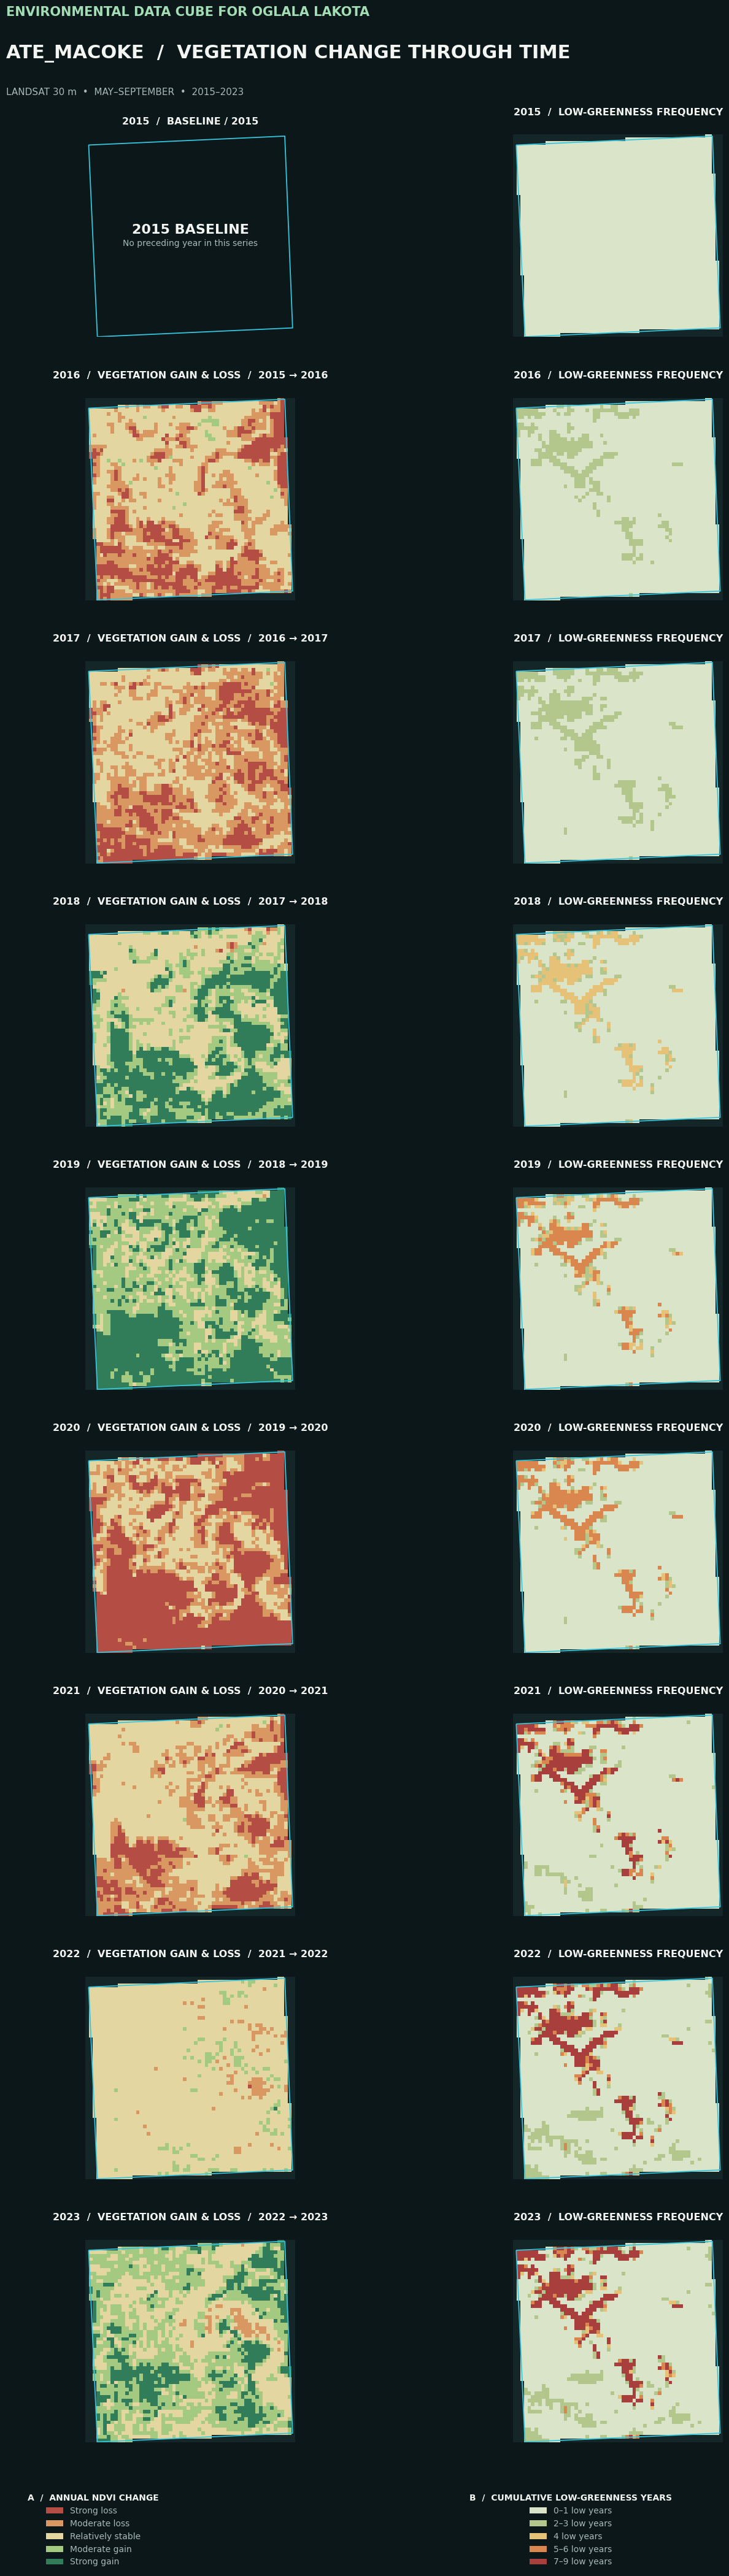


ATE_MACOKE — YEAR-BY-YEAR VEGETATION ATLAS
YEAR        CHANGE PIXELS     CHANGE HA   PERSISTENT PIXELS   PERSISTENT HA
2015                    0          0.00                   0            0.00
2016                2,878        259.02                   0            0.00
2017                2,878        259.02                   0            0.00
2018                2,878        259.02                   0            0.00
2019                2,878        259.02                 202           18.18
2020                2,878        259.02                 271           24.39
2021                2,878        259.02                 303           27.27
2022                2,878        259.02                 325           29.25
2023                2,878        259.02                 326           29.34

Atlas PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Change_Persistence_Atlas/Ate_Macoke_Year_by_Year_Vegetati

In [32]:

# =====================================================================
# ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
# ATE_MACOKE — YEAR-BY-YEAR VEGETATION CHANGE ATLAS
#
# Same two-map style as the existing dissertation figure.
#
# LEFT:  Annual NDVI gain/loss versus preceding year
# RIGHT: Cumulative low-greenness frequency through each year
#
# 2015: Baseline (no previous year for change)
# 2016–2023: Annual NDVI change
#
# Input: Existing 2015–2023 Landsat NDVI GeoTIFFs
# No downloads, no resampling, no modifications to original data.
# =====================================================================

from pathlib import Path
from datetime import datetime

import numpy as np
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt

from rasterio.features import geometry_mask
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# ---------------------------------------------------------------------
# 1. PROJECT PATHS
# ---------------------------------------------------------------------

project = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

source_dir = project / "results" / "SA20_satellite_maps"
parcel_path = project / "data" / "ate_parcel_wanzi.shp"

years = list(range(2015, 2024))

LOW_THRESHOLD = 0.30
PERSISTENCE_YEARS = 5

paths = {
    year: source_dir /
    f"Ate_Macoke_Landsat_NDVI_{year}_MaySep_Median_30m.tif"
    for year in years
}

for year, path in paths.items():
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing {year} raster: {path}"
        )

if not parcel_path.is_file():
    raise FileNotFoundError(parcel_path)

# ---------------------------------------------------------------------
# 2. LOAD AND VERIFY THE NINE EXISTING RASTERS
# ---------------------------------------------------------------------

arrays = []
reference = None

for year in years:

    with rasterio.open(paths[year]) as src:

        if src.count != 1:
            raise ValueError(
                f"{year} raster is not single-band."
            )

        if reference is None:
            reference = {
                "crs": src.crs,
                "shape": src.shape,
                "transform": src.transform,
                "bounds": src.bounds
            }

            if (
                src.crs is None
                or src.crs.to_epsg() != 32613
            ):
                raise ValueError(
                    "Expected EPSG:32613, UTM Zone 13N."
                )

        else:
            if not (
                src.crs == reference["crs"]
                and src.shape == reference["shape"]
                and np.allclose(
                    tuple(src.transform),
                    tuple(reference["transform"]),
                    rtol=0,
                    atol=1e-7
                )
            ):
                raise ValueError(
                    f"{year}: Raster alignment mismatch."
                )

        masked = src.read(1, masked=True)

        arr = np.asarray(
            masked.filled(np.nan),
            dtype=np.float32
        )

        arr[
            ~np.isfinite(arr)
            | (arr < -1)
            | (arr > 1)
        ] = np.nan

        arrays.append(arr)

stack = np.stack(arrays)

height, width = reference["shape"]
transform = reference["transform"]
bounds = reference["bounds"]

# ---------------------------------------------------------------------
# 3. PARCEL MASK
# ---------------------------------------------------------------------

parcel = gpd.read_file(parcel_path)

if parcel.empty or parcel.crs is None:
    raise ValueError(
        "Parcel boundary is empty or lacks a CRS."
    )

parcel = parcel.to_crs(reference["crs"])

parcel = parcel[
    parcel.geometry.notna()
    & ~parcel.geometry.is_empty
].copy()

if parcel.empty:
    raise ValueError("No usable parcel geometry.")

parcel_mask = geometry_mask(
    parcel.geometry,
    out_shape=(height, width),
    transform=transform,
    invert=True,
    all_touched=False
)

if not parcel_mask.any():
    raise ValueError(
        "No parcel pixel centers fall in the raster."
    )

stack = np.where(
    parcel_mask[None, :, :],
    stack,
    np.nan
)

valid = np.isfinite(stack)

pixel_area_ha = abs(
    transform.a * transform.e
    - transform.b * transform.d
) / 10000.0

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]

# ---------------------------------------------------------------------
# 4. COLORS — MATCH EXISTING TWO-PANEL FIGURE
# ---------------------------------------------------------------------

BG = "#0B1718"
PANEL = "#152628"
WHITE = "#F2F5F2"
MUTED = "#A8BAB7"
CYAN = "#36C5DC"
MINT = "#A3DDB5"

change_colors = [
    "#B44E45",
    "#D99861",
    "#E3D6A0",
    "#A3CA80",
    "#317D59"
]

persistence_colors = [
    "#D9E4C9",
    "#B3C78D",
    "#E5C277",
    "#D9864F",
    "#A93F3C"
]

change_cmap = ListedColormap(change_colors)
persistence_cmap = ListedColormap(persistence_colors)

change_cmap.set_bad(PANEL)
persistence_cmap.set_bad(PANEL)

norm = BoundaryNorm(
    np.arange(0.5, 6.5, 1),
    ncolors=5
)

# ---------------------------------------------------------------------
# 5. CLASSIFICATION FUNCTIONS
# ---------------------------------------------------------------------

def annual_change(previous, current):

    good = (
        np.isfinite(previous)
        & np.isfinite(current)
    )

    delta = np.full(
        previous.shape,
        np.nan,
        dtype=np.float32
    )

    delta[good] = (
        current[good] - previous[good]
    )

    classes = np.zeros(
        previous.shape,
        dtype=np.uint8
    )

    classes[
        good & (delta < -0.10)
    ] = 1

    classes[
        good
        & (delta >= -0.10)
        & (delta < -0.05)
    ] = 2

    classes[
        good
        & (delta >= -0.05)
        & (delta <= 0.05)
    ] = 3

    classes[
        good
        & (delta > 0.05)
        & (delta <= 0.10)
    ] = 4

    classes[
        good & (delta > 0.10)
    ] = 5

    return classes, delta, good


def cumulative_persistence(last_index):

    subset = stack[:last_index + 1]

    good = np.isfinite(subset)

    valid_count = good.sum(axis=0)

    low_count = (
        good & (subset < LOW_THRESHOLD)
    ).sum(axis=0)

    sufficient = (
        parcel_mask
        & (valid_count >= PERSISTENCE_YEARS)
    )

    classes = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    # Before five calendar years have elapsed, show
    # observed low-year frequency without calling
    # any pixel persistently low.
    displayable = (
        parcel_mask & (valid_count > 0)
    )

    classes[
        displayable & (low_count <= 1)
    ] = 1

    classes[
        displayable
        & (low_count >= 2)
        & (low_count <= 3)
    ] = 2

    classes[
        displayable & (low_count == 4)
    ] = 3

    classes[
        sufficient
        & (low_count >= 5)
        & (low_count <= 6)
    ] = 4

    classes[
        sufficient & (low_count >= 7)
    ] = 5

    return classes, low_count, valid_count, sufficient

# ---------------------------------------------------------------------
# 6. CREATE NINE-ROW, TWO-COLUMN ATLAS
# ---------------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=9,
    ncols=2,
    figsize=(15, 43),
    facecolor=BG
)

fig.subplots_adjust(
    left=0.075,
    right=0.94,
    top=0.94,
    bottom=0.065,
    hspace=0.30,
    wspace=0.16
)

fig.text(
    0.075,
    0.985,
    "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA",
    color=MINT,
    fontsize=15,
    fontweight="bold"
)

fig.text(
    0.075,
    0.969,
    "ATE_MACOKE  /  VEGETATION CHANGE THROUGH TIME",
    color=WHITE,
    fontsize=22,
    fontweight="bold"
)

fig.text(
    0.075,
    0.955,
    "LANDSAT 30 m  •  MAY–SEPTEMBER  •  2015–2023",
    color=MUTED,
    fontsize=11
)

results = []

for i, year in enumerate(years):

    left_ax = axes[i, 0]
    right_ax = axes[i, 1]

    for ax in (left_ax, right_ax):

        ax.set_facecolor(PANEL)
        ax.set_aspect("equal")

        ax.set_xlim(
            bounds.left,
            bounds.right
        )

        ax.set_ylim(
            bounds.bottom,
            bounds.top
        )

        ax.axis("off")

    # -------------------------------------------------
    # LEFT: YEAR-TO-YEAR NDVI CHANGE
    # -------------------------------------------------

    if i == 0:

        # There is no 2014 raster in this series.
        # Show the 2015 baseline as a neutral panel.
        left_ax.text(
            0.5,
            0.53,
            "2015 BASELINE",
            transform=left_ax.transAxes,
            color=WHITE,
            ha="center",
            va="center",
            fontsize=16,
            fontweight="bold"
        )

        left_ax.text(
            0.5,
            0.45,
            "No preceding year in this series",
            transform=left_ax.transAxes,
            color=MUTED,
            ha="center",
            fontsize=10
        )

        change_count = 0
        change_area = 0.0

        left_title = "BASELINE / 2015"

    else:

        change, delta, endpoint_good = annual_change(
            stack[i - 1],
            stack[i]
        )

        left_ax.imshow(
            np.ma.masked_where(
                change == 0, change
            ),
            extent=extent,
            origin="upper",
            cmap=change_cmap,
            norm=norm,
            interpolation="nearest"
        )

        change_count = int(
            endpoint_good.sum()
        )

        change_area = (
            change_count * pixel_area_ha
        )

        left_title = (
            f"VEGETATION GAIN & LOSS  /  "
            f"{year - 1} → {year}"
        )

    # -------------------------------------------------
    # RIGHT: CUMULATIVE LOW GREENNESS
    # -------------------------------------------------

    (
        persistence,
        low_count,
        valid_count,
        sufficient
    ) = cumulative_persistence(i)

    right_ax.imshow(
        np.ma.masked_where(
            persistence == 0,
            persistence
        ),
        extent=extent,
        origin="upper",
        cmap=persistence_cmap,
        norm=norm,
        interpolation="nearest"
    )

    # Draw the same parcel outline on both panels.
    for ax in (left_ax, right_ax):

        parcel.boundary.plot(
            ax=ax,
            color=CYAN,
            linewidth=1.3,
            zorder=10
        )

    # For the baseline panel, draw boundary
    # without altering any NDVI observations.
    left_ax.set_title(
        f"{year}  /  {left_title}",
        color=WHITE,
        fontsize=11.5,
        fontweight="bold",
        pad=12
    )

    right_ax.set_title(
        f"{year}  /  LOW-GREENNESS FREQUENCY",
        color=WHITE,
        fontsize=11.5,
        fontweight="bold",
        pad=12
    )

    persistent = (
        sufficient & (low_count >= 5)
    )

    persistent_pixels = int(
        persistent.sum()
    )

    results.append({
        "year": year,
        "change_mapped_pixels": change_count,
        "change_mapped_ha": change_area,
        "low_greenness_persistent_pixels": persistent_pixels,
        "low_greenness_persistent_ha": (
            persistent_pixels * pixel_area_ha
        ),
        "valid_low_frequency_pixels": int(
            (
                parcel_mask
                & (valid_count > 0)
            ).sum()
        )
    })

# ---------------------------------------------------------------------
# 7. LEGENDS
# ---------------------------------------------------------------------

change_legend = [
    Patch(facecolor=color, label=label)
    for color, label in zip(
        change_colors,
        [
            "Strong loss",
            "Moderate loss",
            "Relatively stable",
            "Moderate gain",
            "Strong gain"
        ]
    )
]

persistence_legend = [
    Patch(facecolor=color, label=label)
    for color, label in zip(
        persistence_colors,
        [
            "0–1 low years",
            "2–3 low years",
            "4 low years",
            "5–6 low years",
            "7–9 low years"
        ]
    )
]

legend_a = fig.legend(
    handles=change_legend,
    loc="lower left",
    bbox_to_anchor=(0.09, 0.015),
    ncol=1,
    frameon=False,
    fontsize=10,
    title="A  /  ANNUAL NDVI CHANGE"
)

legend_b = fig.legend(
    handles=persistence_legend,
    loc="lower left",
    bbox_to_anchor=(0.57, 0.015),
    ncol=1,
    frameon=False,
    fontsize=10,
    title="B  /  CUMULATIVE LOW-GREENNESS YEARS"
)

for legend in (legend_a, legend_b):

    legend.get_title().set_color(WHITE)
    legend.get_title().set_fontweight("bold")

    for text in legend.get_texts():
        text.set_color(MUTED)

# ---------------------------------------------------------------------
# 8. SAVE TO NEW FILES — NO OVERWRITING
# ---------------------------------------------------------------------

output_dir = (
    source_dir
    / "Ate_Macoke_Change_Persistence_Atlas"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

timestamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)

base = (
    "Ate_Macoke_Year_by_Year_"
    "Vegetation_Change_2015_2023_"
    + timestamp
)

png_path = output_dir / f"{base}.png"
pdf_path = output_dir / f"{base}.pdf"

for path in (png_path, pdf_path):
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}"
        )

with open(png_path, "xb") as f:
    fig.savefig(
        f,
        format="png",
        dpi=250,
        facecolor=BG,
        bbox_inches="tight"
    )

with open(pdf_path, "xb") as f:
    fig.savefig(
        f,
        format="pdf",
        facecolor=BG,
        bbox_inches="tight"
    )

plt.show()

# ---------------------------------------------------------------------
# 9. YEAR-BY-YEAR RESULTS
# ---------------------------------------------------------------------

print("\n" + "=" * 80)
print("ATE_MACOKE — YEAR-BY-YEAR VEGETATION ATLAS")
print("=" * 80)

print(
    f"{'YEAR':<8}"
    f"{'CHANGE PIXELS':>17}"
    f"{'CHANGE HA':>14}"
    f"{'PERSISTENT PIXELS':>20}"
    f"{'PERSISTENT HA':>16}"
)

for item in results:

    print(
        f"{item['year']:<8}"
        f"{item['change_mapped_pixels']:>17,}"
        f"{item['change_mapped_ha']:>14.2f}"
        f"{item['low_greenness_persistent_pixels']:>20,}"
        f"{item['low_greenness_persistent_ha']:>16.2f}"
    )

print("\nAtlas PNG:", png_path)
print("Atlas PDF:", pdf_path)

print("\nOriginal dissertation cube: UNCHANGED")
print("Notebook 09: UNCHANGED")
print("Original GeoTIFFs: UNCHANGED")
print("No imagery downloaded.")
print("=" * 80)


Raster alignment: PASSED
Years: [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
Raster shape: (9, 56, 58)
CRS: EPSG:32613
Pixel area (ha): 0.09


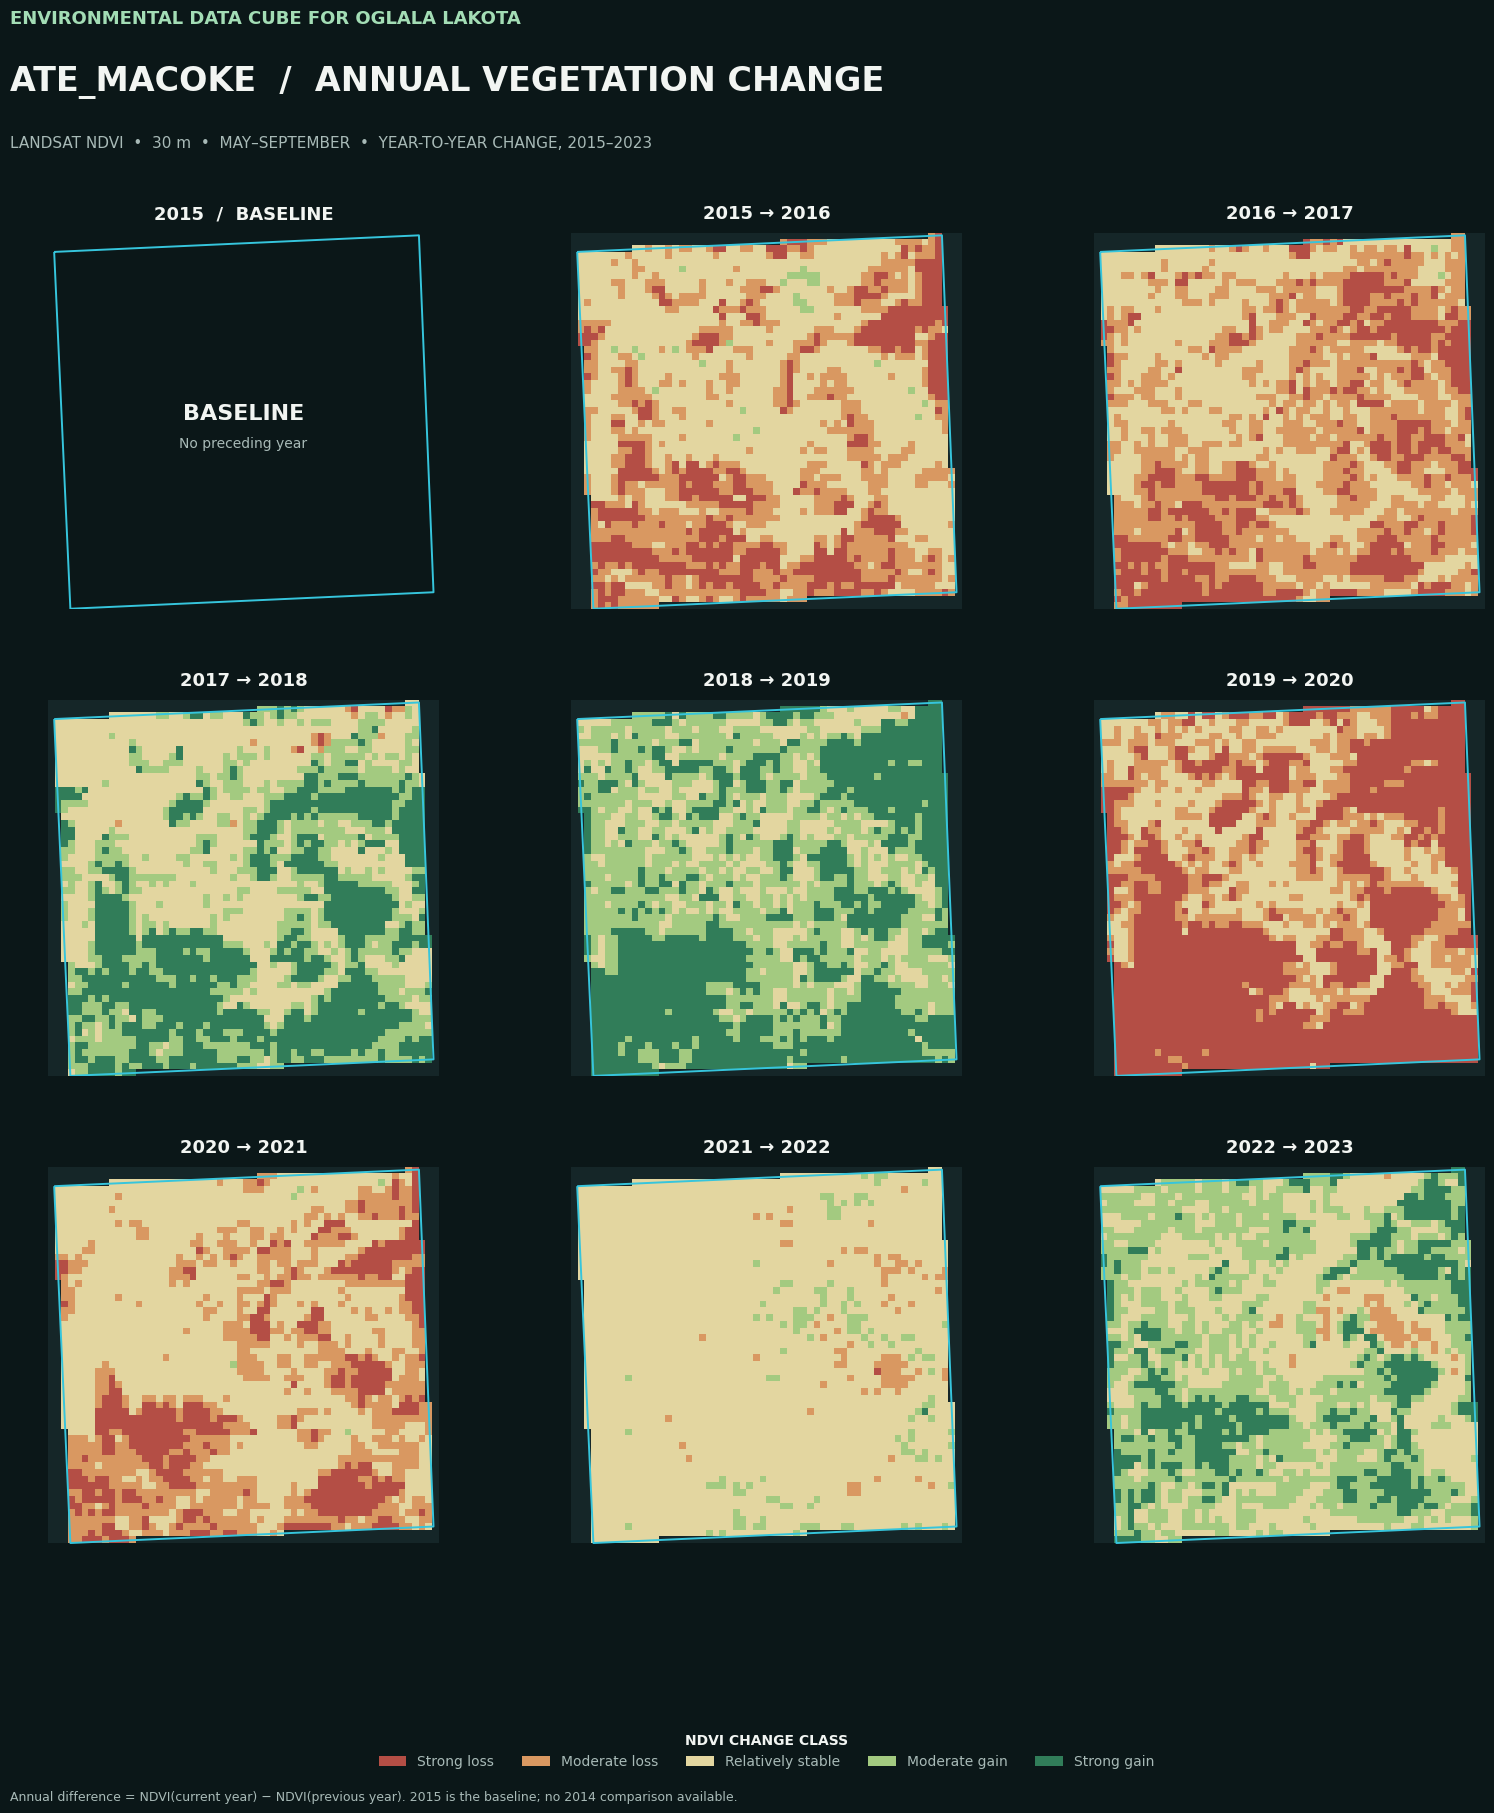

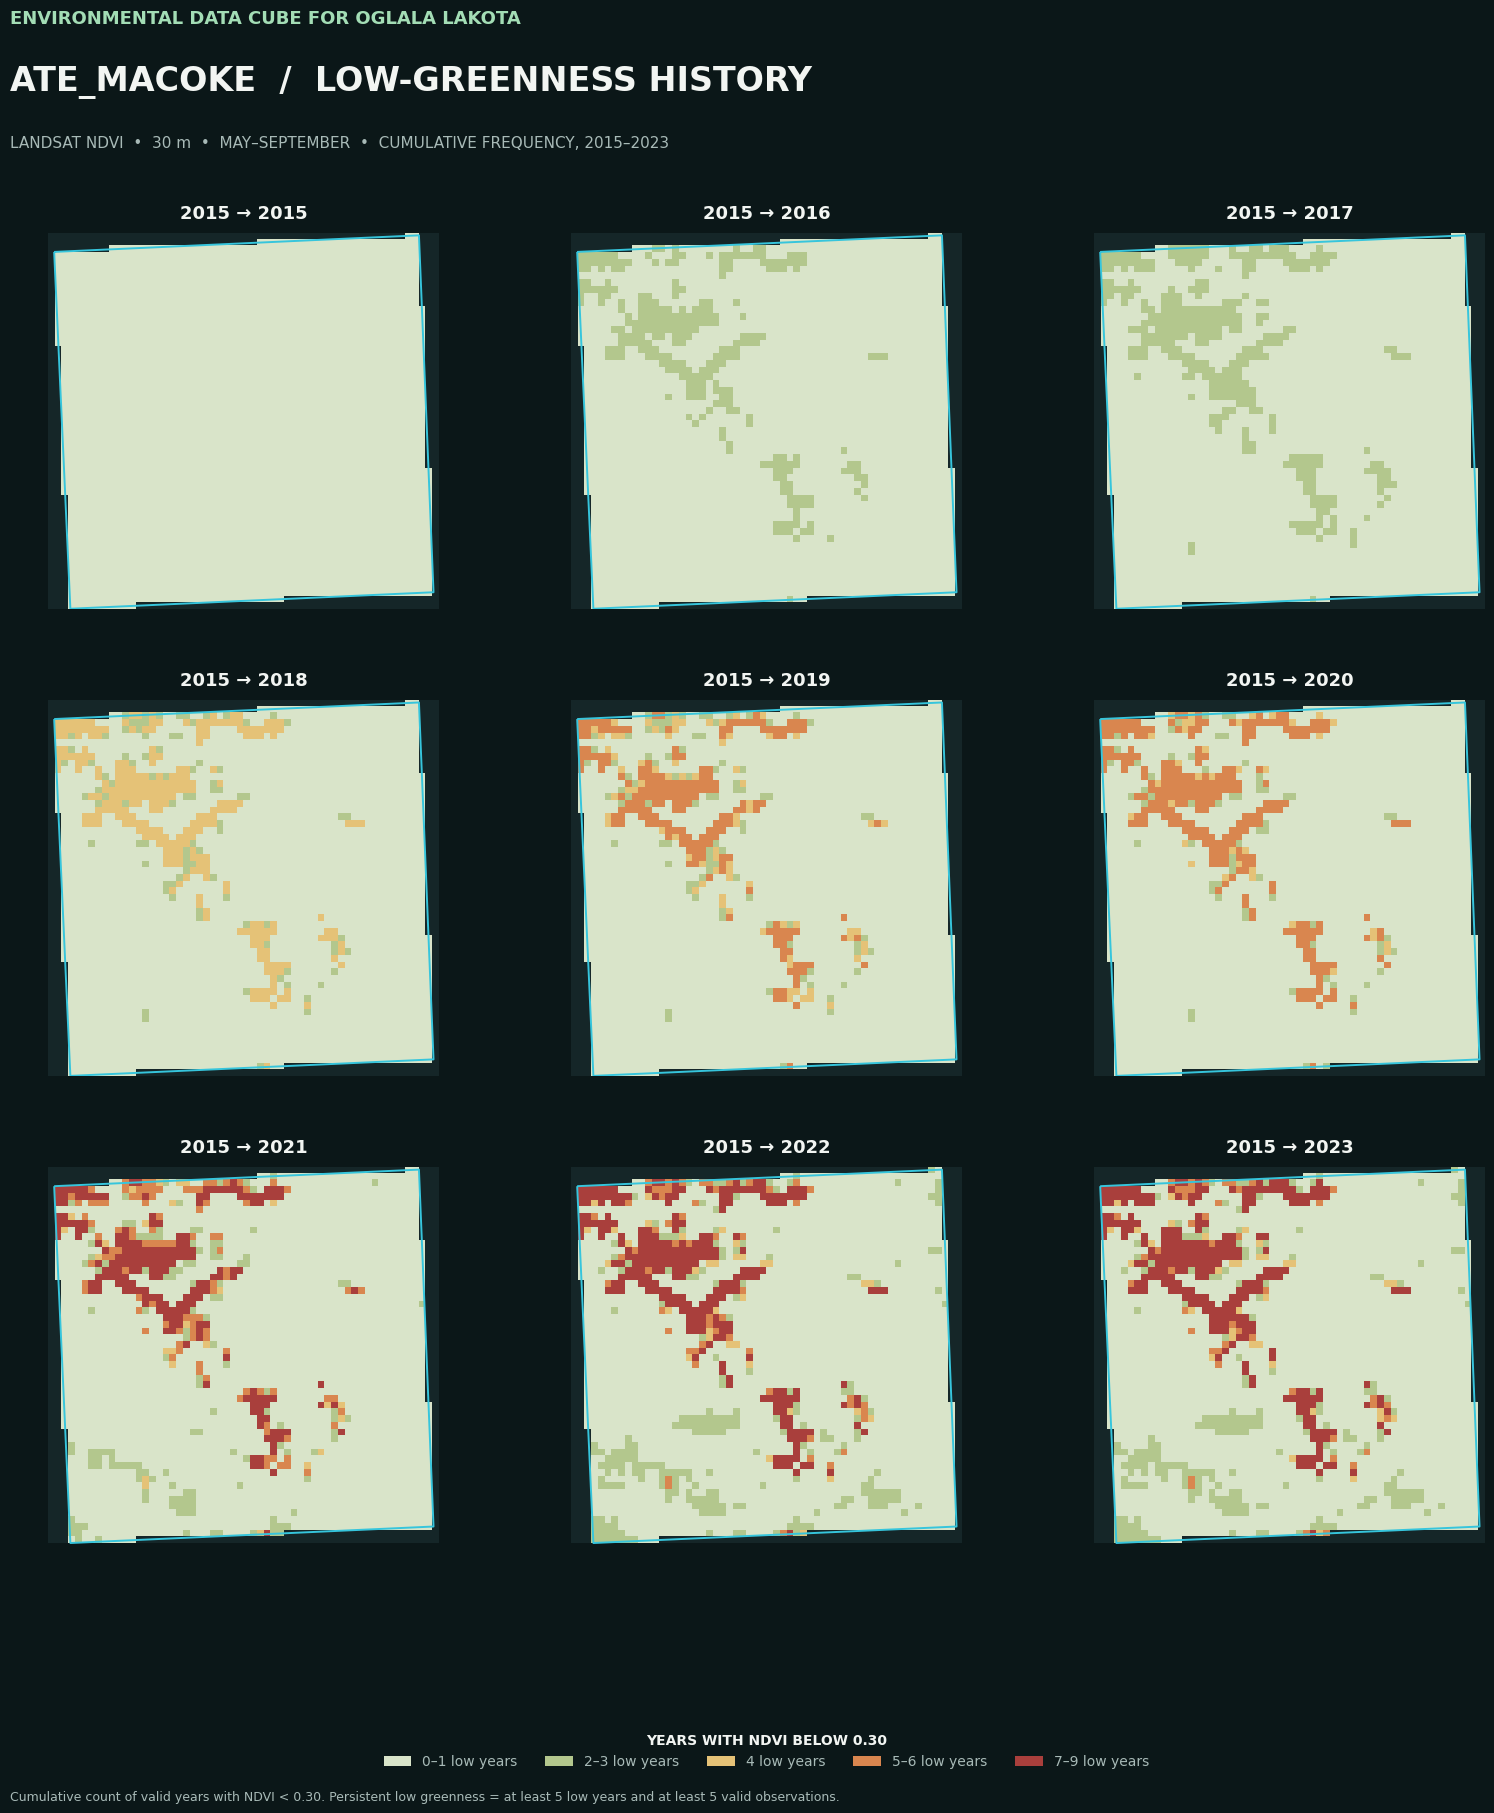


TWO CHRONOLOGICAL ATE_MACOKE ATLASES COMPLETE

ATLAS A — ANNUAL VEGETATION CHANGE
PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Change_Persistence_Atlas/Ate_Macoke_Annual_NDVI_Change_2015_2023_20261016_202901_707838.png
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Change_Persistence_Atlas/Ate_Macoke_Annual_NDVI_Change_2015_2023_20261016_202901_707838.pdf

ATLAS B — LOW-GREENNESS HISTORY
PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Change_Persistence_Atlas/Ate_Macoke_Low_Greenness_2015_2023_20261016_202901_707838.png
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Change_Persistence_Atlas/Ate_Macoke_Low_Greenness_2015_2023_20261016_202901_707838.pd

In [33]:

# =====================================================================
# ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
# ATE_MACOKE — TWO SEPARATE CHRONOLOGICAL ATLASES
#
# ATLAS A: Year-to-year NDVI gain and loss
# ATLAS B: Cumulative low-greenness frequency
#
# Layout: 3 columns x 3 rows, chronological left to right
# Source: Existing Landsat 30 m NDVI rasters, 2015–2023
#
# No downloads, no resampling, no original-file modifications.
# =====================================================================

from pathlib import Path
from datetime import datetime
import csv

import numpy as np
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt

from rasterio.features import geometry_mask
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# ---------------------------------------------------------------------
# 1. PATHS AND SETTINGS
# ---------------------------------------------------------------------

project = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

source_dir = project / "results" / "SA20_satellite_maps"
parcel_path = project / "data" / "ate_parcel_wanzi.shp"

years = list(range(2015, 2024))

LOW_THRESHOLD = 0.30
PERSISTENCE_YEARS = 5

paths = {
    year: source_dir /
    f"Ate_Macoke_Landsat_NDVI_{year}_MaySep_Median_30m.tif"
    for year in years
}

for year, path in paths.items():
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing {year} Landsat NDVI raster:\n{path}"
        )

if not parcel_path.is_file():
    raise FileNotFoundError(
        f"Parcel shapefile not found:\n{parcel_path}"
    )

# ---------------------------------------------------------------------
# 2. READ EXISTING NDVI RASTERS
# ---------------------------------------------------------------------

arrays = []
reference = None

for year in years:

    with rasterio.open(paths[year]) as src:

        if src.count != 1:
            raise ValueError(
                f"{year}: Expected one NDVI band."
            )

        if reference is None:

            reference = {
                "crs": src.crs,
                "shape": src.shape,
                "transform": src.transform,
                "bounds": src.bounds
            }

            if (
                src.crs is None
                or src.crs.to_epsg() != 32613
            ):
                raise ValueError(
                    "Expected EPSG:32613 (UTM Zone 13N)."
                )

        else:

            aligned = (
                src.crs == reference["crs"]
                and src.shape == reference["shape"]
                and np.allclose(
                    tuple(src.transform),
                    tuple(reference["transform"]),
                    rtol=0,
                    atol=1e-7
                )
            )

            if not aligned:
                raise ValueError(
                    f"{year}: Raster grid mismatch."
                )

        band = src.read(1, masked=True)

        data = np.asarray(
            band.filled(np.nan),
            dtype=np.float32
        )

        data[
            ~np.isfinite(data)
            | (data < -1)
            | (data > 1)
        ] = np.nan

        arrays.append(data)

stack = np.stack(arrays, axis=0)

height, width = reference["shape"]
transform = reference["transform"]
bounds = reference["bounds"]

# ---------------------------------------------------------------------
# 3. APPLY PARCEL MASK
# ---------------------------------------------------------------------

parcel = gpd.read_file(parcel_path)

if parcel.empty or parcel.crs is None:
    raise ValueError(
        "Parcel boundary is empty or lacks CRS."
    )

parcel = parcel.to_crs(reference["crs"])

parcel = parcel[
    parcel.geometry.notna()
    & ~parcel.geometry.is_empty
].copy()

if parcel.empty:
    raise ValueError("No usable parcel geometry.")

parcel_mask = geometry_mask(
    parcel.geometry,
    out_shape=(height, width),
    transform=transform,
    invert=True,
    all_touched=False
)

if not parcel_mask.any():
    raise ValueError(
        "No parcel pixel centers fall in raster."
    )

stack = np.where(
    parcel_mask[None, :, :],
    stack,
    np.nan
)

valid = np.isfinite(stack)

pixel_area_ha = abs(
    transform.a * transform.e
    - transform.b * transform.d
) / 10000.0

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]

print("Raster alignment: PASSED")
print("Years:", years)
print("Raster shape:", stack.shape)
print("CRS:", reference["crs"])
print("Pixel area (ha):", pixel_area_ha)

# ---------------------------------------------------------------------
# 4. MAP CLASSIFICATIONS
# ---------------------------------------------------------------------

def classify_change(previous, current):

    good = (
        np.isfinite(previous)
        & np.isfinite(current)
    )

    delta = np.full(
        previous.shape,
        np.nan,
        dtype=np.float32
    )

    delta[good] = current[good] - previous[good]

    classes = np.zeros(
        previous.shape,
        dtype=np.uint8
    )

    classes[good & (delta < -0.10)] = 1

    classes[
        good & (delta >= -0.10)
        & (delta < -0.05)
    ] = 2

    classes[
        good & (delta >= -0.05)
        & (delta <= 0.05)
    ] = 3

    classes[
        good & (delta > 0.05)
        & (delta <= 0.10)
    ] = 4

    classes[good & (delta > 0.10)] = 5

    return classes, good


def classify_low_frequency(last_index):

    subset = stack[:last_index + 1]
    subset_valid = np.isfinite(subset)

    valid_count = subset_valid.sum(axis=0)

    low_count = (
        subset_valid
        & (subset < LOW_THRESHOLD)
    ).sum(axis=0)

    displayable = (
        parcel_mask & (valid_count > 0)
    )

    classes = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    classes[
        displayable & (low_count <= 1)
    ] = 1

    classes[
        displayable
        & (low_count >= 2)
        & (low_count <= 3)
    ] = 2

    classes[
        displayable & (low_count == 4)
    ] = 3

    classes[
        displayable
        & (low_count >= 5)
        & (low_count <= 6)
    ] = 4

    classes[
        displayable & (low_count >= 7)
    ] = 5

    sufficient = (
        parcel_mask
        & (valid_count >= PERSISTENCE_YEARS)
    )

    persistent = (
        sufficient & (low_count >= PERSISTENCE_YEARS)
    )

    return (
        classes,
        valid_count,
        low_count,
        persistent
    )

# ---------------------------------------------------------------------
# 5. ATLAS COLORS AND STYLE
# ---------------------------------------------------------------------

BG = "#0B1718"
PANEL = "#152628"
WHITE = "#F2F5F2"
MUTED = "#A8BAB7"
CYAN = "#36C5DC"
MINT = "#A3DDB5"

change_colors = [
    "#B44E45",  # Strong loss
    "#D99861",  # Moderate loss
    "#E3D6A0",  # Stable
    "#A3CA80",  # Moderate gain
    "#317D59"   # Strong gain
]

low_colors = [
    "#D9E4C9",  # 0–1 low years
    "#B3C78D",  # 2–3 low years
    "#E5C277",  # 4 low years
    "#D9864F",  # 5–6 low years
    "#A93F3C"   # 7–9 low years
]

change_cmap = ListedColormap(change_colors)
low_cmap = ListedColormap(low_colors)

change_cmap.set_bad(PANEL)
low_cmap.set_bad(PANEL)

norm = BoundaryNorm(
    np.arange(0.5, 6.5, 1),
    ncolors=5
)

# ---------------------------------------------------------------------
# 6. OUTPUT DIRECTORY — UNIQUE FILENAMES
# ---------------------------------------------------------------------

output_dir = (
    source_dir
    / "Ate_Macoke_Change_Persistence_Atlas"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

timestamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)

change_png = output_dir / (
    f"Ate_Macoke_Annual_NDVI_Change_"
    f"2015_2023_{timestamp}.png"
)

change_pdf = output_dir / (
    f"Ate_Macoke_Annual_NDVI_Change_"
    f"2015_2023_{timestamp}.pdf"
)

low_png = output_dir / (
    f"Ate_Macoke_Low_Greenness_"
    f"2015_2023_{timestamp}.png"
)

low_pdf = output_dir / (
    f"Ate_Macoke_Low_Greenness_"
    f"2015_2023_{timestamp}.pdf"
)

csv_path = output_dir / (
    f"Ate_Macoke_Annual_Atlas_Summary_{timestamp}.csv"
)

outputs = [
    change_png,
    change_pdf,
    low_png,
    low_pdf,
    csv_path
]

if any(path.exists() for path in outputs):
    raise FileExistsError(
        "Output already exists. Nothing overwritten."
    )

# ---------------------------------------------------------------------
# 7. COMMON ATLAS LAYOUT
# ---------------------------------------------------------------------

def make_atlas(title, subtitle):

    fig, axes = plt.subplots(
        3, 3,
        figsize=(17, 19),
        facecolor=BG
    )

    fig.subplots_adjust(
        left=0.055,
        right=0.945,
        top=0.86,
        bottom=0.17,
        wspace=0.12,
        hspace=0.24
    )

    fig.text(
        0.055,
        0.97,
        "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA",
        color=MINT,
        fontsize=13,
        fontweight="bold"
    )

    fig.text(
        0.055,
        0.935,
        title,
        color=WHITE,
        fontsize=24,
        fontweight="bold"
    )

    fig.text(
        0.055,
        0.905,
        subtitle,
        color=MUTED,
        fontsize=11
    )

    for ax in axes.flat:

        ax.set_facecolor(PANEL)
        ax.set_aspect("equal")

        ax.set_xlim(
            bounds.left,
            bounds.right
        )

        ax.set_ylim(
            bounds.bottom,
            bounds.top
        )

        ax.axis("off")

    return fig, axes


def draw_panel(ax, classes, title, cmap):

    display = np.ma.masked_where(
        classes == 0,
        classes
    )

    ax.imshow(
        display,
        extent=extent,
        origin="upper",
        cmap=cmap,
        norm=norm,
        interpolation="nearest"
    )

    parcel.boundary.plot(
        ax=ax,
        color=CYAN,
        linewidth=1.4,
        zorder=10
    )

    ax.set_title(
        title,
        color=WHITE,
        fontsize=13,
        fontweight="bold",
        pad=10
    )


def add_legend(fig, colors, labels, title):

    handles = [
        Patch(
            facecolor=color,
            edgecolor="none",
            label=label
        )
        for color, label in zip(colors, labels)
    ]

    legend = fig.legend(
        handles=handles,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.045),
        ncol=5,
        frameon=False,
        fontsize=10,
        title=title
    )

    legend.get_title().set_color(WHITE)
    legend.get_title().set_fontweight("bold")

    for item in legend.get_texts():
        item.set_color(MUTED)

# ---------------------------------------------------------------------
# 8. ATLAS A — ANNUAL VEGETATION GAIN AND LOSS
# ---------------------------------------------------------------------

fig_a, axes_a = make_atlas(
    "ATE_MACOKE  /  ANNUAL VEGETATION CHANGE",
    (
        "LANDSAT NDVI  •  30 m  •  MAY–SEPTEMBER  •  "
        "YEAR-TO-YEAR CHANGE, 2015–2023"
    )
)

summary = []

for i, year in enumerate(years):

    ax = axes_a.flat[i]

    if i == 0:

        # Baseline year: no 2014 raster is supplied.
        parcel.boundary.plot(
            ax=ax,
            color=CYAN,
            linewidth=1.4
        )

        ax.text(
            0.5,
            0.52,
            "BASELINE",
            transform=ax.transAxes,
            ha="center",
            va="center",
            color=WHITE,
            fontsize=16,
            fontweight="bold"
        )

        ax.text(
            0.5,
            0.43,
            "No preceding year",
            transform=ax.transAxes,
            ha="center",
            color=MUTED,
            fontsize=10
        )

        ax.set_title(
            "2015  /  BASELINE",
            color=WHITE,
            fontsize=13,
            fontweight="bold",
            pad=10
        )

        change_pixels = 0

    else:

        classes, good = classify_change(
            stack[i - 1],
            stack[i]
        )

        draw_panel(
            ax,
            classes,
            f"{year - 1} → {year}",
            change_cmap
        )

        change_pixels = int(good.sum())

    summary.append({
        "year": year,
        "change_pixels": change_pixels,
        "change_area_ha": (
            change_pixels * pixel_area_ha
        )
    })

add_legend(
    fig_a,
    change_colors,
    [
        "Strong loss",
        "Moderate loss",
        "Relatively stable",
        "Moderate gain",
        "Strong gain"
    ],
    "NDVI CHANGE CLASS"
)

fig_a.text(
    0.055,
    0.035,
    (
        "Annual difference = NDVI(current year) "
        "− NDVI(previous year). "
        "2015 is the baseline; no 2014 comparison available."
    ),
    color=MUTED,
    fontsize=9
)

# ---------------------------------------------------------------------
# 9. ATLAS B — LOW-GREENNESS FREQUENCY
# ---------------------------------------------------------------------

fig_b, axes_b = make_atlas(
    "ATE_MACOKE  /  LOW-GREENNESS HISTORY",
    (
        "LANDSAT NDVI  •  30 m  •  MAY–SEPTEMBER  •  "
        "CUMULATIVE FREQUENCY, 2015–2023"
    )
)

for i, year in enumerate(years):

    ax = axes_b.flat[i]

    (
        classes,
        valid_count,
        low_count,
        persistent
    ) = classify_low_frequency(i)

    draw_panel(
        ax,
        classes,
        f"2015 → {year}",
        low_cmap
    )

    persistent_pixels = int(
        persistent.sum()
    )

    summary[i].update({
        "low_greenness_persistent_pixels": (
            persistent_pixels
        ),
        "low_greenness_persistent_area_ha": (
            persistent_pixels * pixel_area_ha
        ),
        "low_frequency_mapped_pixels": int(
            (
                parcel_mask & (valid_count > 0)
            ).sum()
        )
    })

add_legend(
    fig_b,
    low_colors,
    [
        "0–1 low years",
        "2–3 low years",
        "4 low years",
        "5–6 low years",
        "7–9 low years"
    ],
    "YEARS WITH NDVI BELOW 0.30"
)

fig_b.text(
    0.055,
    0.035,
    (
        "Cumulative count of valid years with NDVI < 0.30. "
        "Persistent low greenness = at least 5 low years "
        "and at least 5 valid observations."
    ),
    color=MUTED,
    fontsize=9
)

# ---------------------------------------------------------------------
# 10. SAVE BOTH ATLASES
# ---------------------------------------------------------------------

for fig, png, pdf in [
    (fig_a, change_png, change_pdf),
    (fig_b, low_png, low_pdf)
]:

    with open(png, "xb") as file:

        fig.savefig(
            file,
            format="png",
            dpi=300,
            facecolor=BG,
            bbox_inches="tight"
        )

    with open(pdf, "xb") as file:

        fig.savefig(
            file,
            format="pdf",
            facecolor=BG,
            bbox_inches="tight"
        )

plt.show()

# ---------------------------------------------------------------------
# 11. EXPORT YEAR-BY-YEAR SUMMARY
# ---------------------------------------------------------------------

with open(
    csv_path,
    "x",
    newline="",
    encoding="utf-8"
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=[
            "year",
            "change_pixels",
            "change_area_ha",
            "low_greenness_persistent_pixels",
            "low_greenness_persistent_area_ha",
            "low_frequency_mapped_pixels"
        ]
    )

    writer.writeheader()
    writer.writerows(summary)

# ---------------------------------------------------------------------
# 12. RESULTS
# ---------------------------------------------------------------------

print("\n" + "=" * 78)
print("TWO CHRONOLOGICAL ATE_MACOKE ATLASES COMPLETE")
print("=" * 78)

print("\nATLAS A — ANNUAL VEGETATION CHANGE")
print("PNG:", change_png)
print("PDF:", change_pdf)

print("\nATLAS B — LOW-GREENNESS HISTORY")
print("PNG:", low_png)
print("PDF:", low_pdf)

print("\nYEAR-BY-YEAR SUMMARY")
print("CSV:", csv_path)

print("\nOriginal dissertation cube: UNCHANGED")
print("Notebook 09: UNCHANGED")
print("Original Landsat rasters: UNCHANGED")
print("No imagery downloaded.")
print("=" * 78)


In [34]:

# ================================================================
# ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
# READ-ONLY INVENTORY: EXISTING LAND-COVER DATA
#
# Search for CDL, NLCD, land-cover, and agricultural classification
# datasets already present in the dissertation project.
#
# No downloads. No file changes.
# ================================================================

from pathlib import Path
import rasterio
import xarray as xr

project = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

keywords = [
    "cdl",
    "nlcd",
    "landcover",
    "land_cover",
    "land-cover",
    "cropland",
    "pasture",
    "grassland",
    "rangeland",
    "classification",
    "rap"
]

extensions = {
    ".tif", ".tiff", ".nc", ".img", ".vrt"
}

print("=" * 72)
print("ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA")
print("LAND-COVER DATA INVENTORY — READ ONLY")
print("=" * 72)

if not project.is_dir():
    raise FileNotFoundError(
        f"Project directory not found:\n{project}"
    )

matches = []

for path in project.rglob("*"):

    if not path.is_file():
        continue

    if path.suffix.lower() not in extensions:
        continue

    name = path.name.lower()

    if any(word in name for word in keywords):
        matches.append(path)

print(f"\nLand-cover candidate files found: {len(matches)}")

for i, path in enumerate(sorted(matches), 1):

    print("\n" + "-" * 72)
    print(f"FILE {i}")
    print("Path:", path.relative_to(project))

    try:

        if path.suffix.lower() in {
            ".tif", ".tiff", ".img", ".vrt"
        }:

            with rasterio.open(path) as src:

                print("Type: Raster")
                print("CRS:", src.crs)
                print("Shape:", src.shape)
                print("Resolution:", src.res)
                print("Bands:", src.count)
                print("NoData:", src.nodata)
                print("Descriptions:", src.descriptions)
                print("Tags:", src.tags())

        elif path.suffix.lower() == ".nc":

            with xr.open_dataset(path) as ds:

                print("Type: NetCDF")
                print("Dimensions:", dict(ds.sizes))
                print("Variables:", list(ds.data_vars))
                print("Attributes:", dict(ds.attrs))

    except Exception as error:

        print("Could not inspect:", error)

print("\n" + "=" * 72)

if not matches:
    print(
        "No matching land-cover raster files found "
        "under the project directory."
    )
    print(
        "This does not rule out datasets saved elsewhere "
        "or under different filenames."
    )
else:
    print(
        "Inventory complete. Candidate files must still "
        "be checked to confirm they contain actual "
        "land-cover classifications."
    )

print("\nREAD-ONLY INVENTORY COMPLETE")
print("Original dissertation cube: UNCHANGED")
print("Notebook 09: UNCHANGED")
print("=" * 72)


ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
LAND-COVER DATA INVENTORY — READ ONLY

Land-cover candidate files found: 0

No matching land-cover raster files found under the project directory.
This does not rule out datasets saved elsewhere or under different filenames.

READ-ONLY INVENTORY COMPLETE
Original dissertation cube: UNCHANGED
Notebook 09: UNCHANGED


In [35]:

from pathlib import Path
import xarray as xr

project = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

cube_path = (
    project
    / "Notebooks"
    / "environmental_data_cube_oglala_lakota_dissertation.nc"
)

if not cube_path.is_file():
    raise FileNotFoundError(cube_path)

print("=" * 72)
print("ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA")
print("ORIGINAL CUBE — DIMENSIONS AND SPATIAL EXTENT")
print("=" * 72)

with xr.open_dataset(cube_path) as ds:

    print("\nDIMENSIONS")
    for name, size in ds.sizes.items():
        print(f"  {name}: {size}")

    print("\nCOORDINATES")
    for name, coord in ds.coords.items():
        print(
            f"  {name}: "
            f"dimensions={coord.dims}, "
            f"shape={coord.shape}"
        )

        if coord.size <= 12:
            print("    values:", coord.values)

    print("\nDATA VARIABLES")
    for name, var in ds.data_vars.items():
        print(
            f"  {name}: "
            f"dimensions={var.dims}, "
            f"shape={var.shape}"
        )

    print("\nGLOBAL ATTRIBUTES")
    for key, value in ds.attrs.items():
        print(f"  {key}: {value}")

    print("\nSPATIAL METADATA")
    for key in [
        "crs",
        "spatial_ref",
        "epsg",
        "bounds",
        "bbox",
        "geospatial_lat_min",
        "geospatial_lat_max",
        "geospatial_lon_min",
        "geospatial_lon_max"
    ]:
        if key in ds.attrs:
            print(f"  {key}: {ds.attrs[key]}")

print("\nREAD-ONLY INSPECTION COMPLETE")
print("Original dissertation cube: UNCHANGED")
print("Notebook 09: UNCHANGED")
print("=" * 72)


ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
ORIGINAL CUBE — DIMENSIONS AND SPATIAL EXTENT

DIMENSIONS
  year: 3

COORDINATES
  year: dimensions=('year',), shape=(3,)
    values: [2019 2022 2023]

DATA VARIABLES
  landsat_parcel_ndvi: dimensions=('year',), shape=(3,)
  landsat_parcel_ndmi: dimensions=('year',), shape=(3,)
  reservation_evi: dimensions=('year',), shape=(3,)
  growing_precip_mm: dimensions=('year',), shape=(3,)
  growing_tmax_c: dimensions=('year',), shape=(3,)
  parcel_pixel_count: dimensions=('year',), shape=(3,)

GLOBAL ATTRIBUTES
  title: Environmental Data Cube for Oglala Lakota
  component: Dissertation Integrated Analysis
  study_period: 2019, 2022, 2023
  governance: Oglala Lakota Nation - Tribal Data Sovereignty
  spatial_support: Parcel-level Landsat observations, reservation-scale MODIS EVI, and climate context
  climate_provenance_status: Geographic extraction documentation unresolved
  interpretation: Descriptive environmental comparisons; no grazing causation 

In [36]:

from pathlib import Path
import geopandas as gpd

project = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

print("=" * 72)
print("ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA")
print("CHECKING EXISTING CENSUS TRIBAL BOUNDARY CACHE")
print("=" * 72)

matches = sorted(
    p for p in project.rglob("sd_tribal_boundaries.geojson")
    if p.is_file()
)

if not matches:
    print("\nNo cached sd_tribal_boundaries.geojson found.")
    print("The source function may exist without having been run.")
else:
    for path in matches:
        print("\nFOUND:", path)

        gdf = gpd.read_file(path)

        print("CRS:", gdf.crs)
        print("Features:", len(gdf))
        print("Columns:", list(gdf.columns))

        if "NAME" in gdf.columns:
            pine = gdf[
                gdf["NAME"].astype(str).str.contains(
                    "Pine Ridge",
                    case=False,
                    na=False
                )
            ].copy()

            if not pine.empty:
                pine_utm = pine.to_crs("EPSG:32613")

                xmin, ymin, xmax, ymax = pine_utm.total_bounds

                print("\nPINE RIDGE BOUNDARY FOUND")
                print("Features:", len(pine))
                print("Bounds EPSG:32613:")
                print((xmin, ymin, xmax, ymax))

                print(
                    "Bounding-box dimensions (km):",
                    round((xmax - xmin) / 1000, 2),
                    "×",
                    round((ymax - ymin) / 1000, 2)
                )

                print(
                    "Polygon area (km²):",
                    round(
                        pine_utm.geometry.area.sum() / 1e6,
                        2
                    )
                )
            else:
                print("Pine Ridge not found in NAME column.")

print("\nREAD-ONLY CHECK COMPLETE")
print("Original dissertation cube: UNCHANGED")
print("Notebook 09: UNCHANGED")


ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
CHECKING EXISTING CENSUS TRIBAL BOUNDARY CACHE

FOUND: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/data/cache/sd_tribal_boundaries.geojson
CRS: EPSG:4326
Features: 8
Columns: ['NAME', 'AIANNHCE', 'AIANNHNS', 'GEOID', 'GEOIDFQ', 'NAMELSAD', 'LSAD', 'CLASSFP', 'COMPTYP', 'AIANNHR', 'MTFCC', 'FUNCSTAT', 'ALAND', 'AWATER', 'INTPTLAT', 'INTPTLON', 'common_name', 'geometry']

PINE RIDGE BOUNDARY FOUND
Features: 1
Bounds EPSG:32613:
(661325.6472816983, 4762262.677201252, 807473.7547138089, 4856120.259149111)
Bounding-box dimensions (km): 146.15 × 93.86
Polygon area (km²): 11281.95

READ-ONLY CHECK COMPLETE
Original dissertation cube: UNCHANGED
Notebook 09: UNCHANGED


ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
PINE RIDGE RESERVATION — 30 M GRID

CRS: EPSG:32613
Resolution: 30 m
Width (pixels): 4872
Height (pixels): 3129
Years: [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]

Grid bounds (meters):
Left: 661320.0
Bottom: 4762260.0
Right: 807480.0
Top: 4856130.0

Pixels per year: 15,244,488
Pixels across nine years: 137,200,392
Estimated uncompressed classification data: 130.8 MiB
Estimated reservation area: 11,281.95 km²


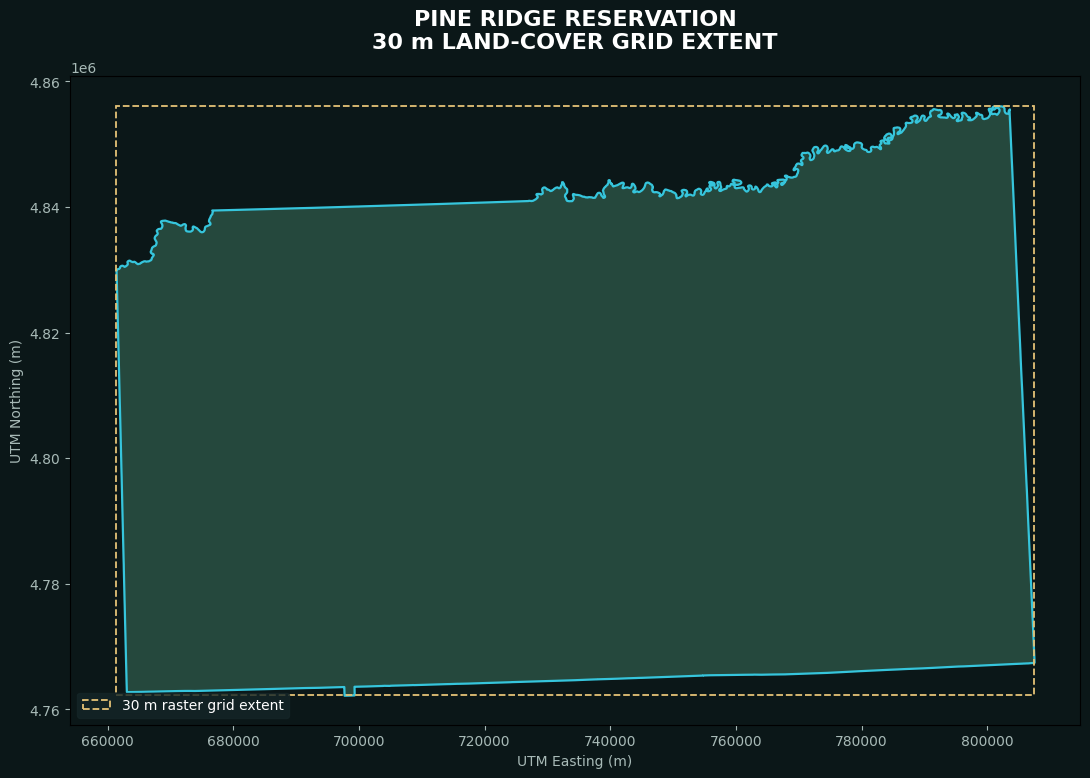


READ-ONLY GRID DEFINITION COMPLETE
Original dissertation cube: UNCHANGED
Notebook 09: UNCHANGED


In [37]:

# ================================================================
# ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
# PINE RIDGE RESERVATION — 30 M LAND-COVER GRID DEFINITION
#
# READ ONLY: No downloads, no files created or modified.
# ================================================================

from pathlib import Path
import math

import geopandas as gpd
import matplotlib.pyplot as plt

from rasterio.transform import from_origin
from matplotlib.patches import Rectangle

project = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

boundary_path = (
    project
    / "data"
    / "cache"
    / "sd_tribal_boundaries.geojson"
)

if not boundary_path.is_file():
    raise FileNotFoundError(boundary_path)

boundaries = gpd.read_file(boundary_path)

pine = boundaries[
    boundaries["NAME"] == "Pine Ridge"
].copy()

if len(pine) != 1:
    raise ValueError(
        f"Expected one Pine Ridge boundary, found {len(pine)}."
    )

pine = pine.to_crs("EPSG:32613")

xmin, ymin, xmax, ymax = pine.total_bounds

resolution = 30.0

# Snap the bounding rectangle outward to 30 m grid lines.
left = math.floor(xmin / resolution) * resolution
bottom = math.floor(ymin / resolution) * resolution
right = math.ceil(xmax / resolution) * resolution
top = math.ceil(ymax / resolution) * resolution

width = int(round((right - left) / resolution))
height = int(round((top - bottom) / resolution))

transform = from_origin(
    left,
    top,
    resolution,
    resolution
)

pixels_per_year = width * height
years = list(range(2015, 2024))

# uint8 is suitable for CDL class codes, with appropriate NoData metadata.
raw_bytes = pixels_per_year * len(years)

print("=" * 72)
print("ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA")
print("PINE RIDGE RESERVATION — 30 M GRID")
print("=" * 72)

print("\nCRS: EPSG:32613")
print("Resolution: 30 m")
print("Width (pixels):", width)
print("Height (pixels):", height)
print("Years:", years)

print("\nGrid bounds (meters):")
print("Left:", left)
print("Bottom:", bottom)
print("Right:", right)
print("Top:", top)

print("\nPixels per year:", f"{pixels_per_year:,}")
print(
    "Pixels across nine years:",
    f"{pixels_per_year * len(years):,}"
)

print(
    "Estimated uncompressed classification data:",
    f"{raw_bytes / 1024**2:.1f} MiB"
)

print(
    "Estimated reservation area:",
    f"{pine.geometry.area.sum() / 1e6:,.2f} km²"
)

# ---------------------------------------------------------------
# Plot geographic coverage
# ---------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(11, 8),
    facecolor="#0B1718"
)

ax.set_facecolor("#0B1718")

pine.plot(
    ax=ax,
    facecolor="#25483D",
    edgecolor="#36C5DC",
    linewidth=1.6
)

rect = Rectangle(
    (left, bottom),
    right - left,
    top - bottom,
    fill=False,
    edgecolor="#E5C277",
    linewidth=1.3,
    linestyle="--",
    label="30 m raster grid extent"
)

ax.add_patch(rect)

ax.set_title(
    "PINE RIDGE RESERVATION\n"
    "30 m LAND-COVER GRID EXTENT",
    color="white",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.tick_params(colors="#A8BAB7")

ax.set_xlabel(
    "UTM Easting (m)",
    color="#A8BAB7"
)

ax.set_ylabel(
    "UTM Northing (m)",
    color="#A8BAB7"
)

legend = ax.legend(
    loc="lower left",
    facecolor="#152628",
    edgecolor="#152628"
)

for text in legend.get_texts():
    text.set_color("white")

ax.set_aspect("equal")

plt.tight_layout()
plt.show()

print("\nREAD-ONLY GRID DEFINITION COMPLETE")
print("Original dissertation cube: UNCHANGED")
print("Notebook 09: UNCHANGED")
print("=" * 72)



ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
USDA CROPLAND DATA LAYER — 2023

Study area: Pine Ridge Reservation
CRS: EPSG:32613
Resolution: 30 m
Grid: 4,872 columns × 3,129 rows

Source tiles: 88

Successful source tiles: 77

Applying reservation boundary mask...

Reservation coverage: 100.00%

CDL CLASS CODES PRESENT IN THE RESERVATION
Class   1 |    280,064 pixels |     25,205.8 ha
Class   4 |     46,086 pixels |      4,147.7 ha
Class   5 |     10,088 pixels |        907.9 ha
Class   6 |    124,297 pixels |     11,186.7 ha
Class  13 |          6 pixels |          0.5 ha
Class  21 |      1,003 pixels |         90.3 ha
Class  23 |     44,812 pixels |      4,033.1 ha
Class  24 |    151,860 pixels |     13,667.4 ha
Class  27 |      5,612 pixels |        505.1 ha
Class  28 |     81,344 pixels |      7,321.0 ha
Class  29 |    144,237 pixels |     12,981.3 ha
Class  31 |          5 pixels |          0.4 ha
Class  32 |          1 pixels |          0.1 ha
Class  33 |      8,621 pixels |        

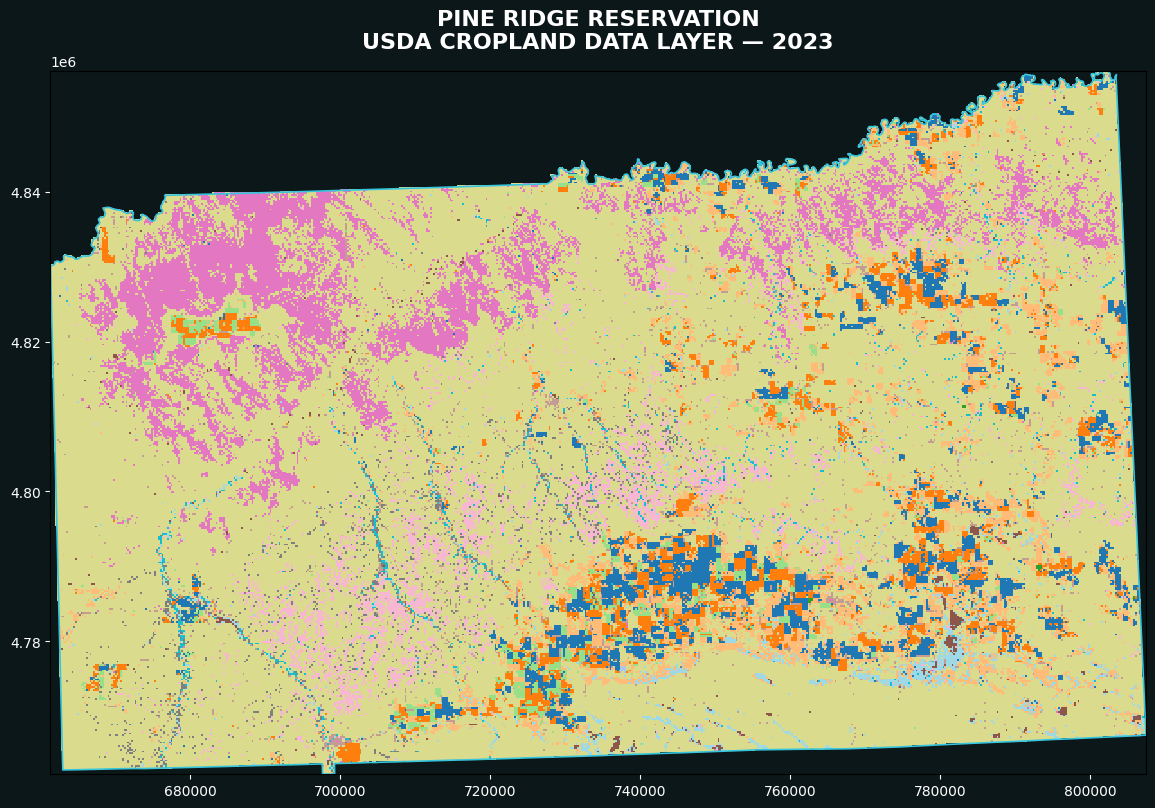


2023 USDA CDL PROCESSING COMPLETE

Saved GeoTIFF:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/data/landcover/Pine_Ridge_USDA_CDL_2023_30m.tif

Resolution: 30 m
CRS: EPSG:32613
Study area: Entire Pine Ridge Reservation

Original dissertation cube: UNCHANGED
Notebook 09: UNCHANGED
Existing Landsat rasters: UNCHANGED


In [41]:

# ======================================================================
# ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
# NOTEBOOK 13 — USDA CDL 2023 DOWNLOAD (CORRECTED)
#
# Study area: Entire Pine Ridge Indian Reservation
# Output: 30 m categorical GeoTIFF, EPSG:32613
#
# Original dissertation cube: NOT MODIFIED
# Notebook 09: NOT MODIFIED
# Existing Landsat NDVI rasters: NOT MODIFIED
# ======================================================================

from pathlib import Path
from tempfile import TemporaryDirectory
from rasterio.transform import from_origin
from rasterio.warp import transform_bounds, reproject, Resampling
from rasterio.features import geometry_mask
from rasterio.windows import Window, from_bounds
from rasterio.enums import ColorInterp

import math
import time
import requests
import numpy as np
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------
# 1. PROJECT PATHS
# ----------------------------------------------------------------------

project = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

boundary_path = (
    project
    / "data"
    / "cache"
    / "sd_tribal_boundaries.geojson"
)

output_dir = project / "data" / "landcover"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir
    / "Pine_Ridge_USDA_CDL_2023_30m.tif"
)

if not boundary_path.is_file():
    raise FileNotFoundError(
        f"Reservation boundary not found:\n{boundary_path}"
    )

if output_path.exists():
    raise FileExistsError(
        "A CDL output already exists. It will not be overwritten:\n"
        f"{output_path}"
    )

# ----------------------------------------------------------------------
# 2. LOAD PINE RIDGE RESERVATION BOUNDARY
# ----------------------------------------------------------------------

boundaries = gpd.read_file(boundary_path)

pine = boundaries.loc[
    boundaries["NAME"] == "Pine Ridge"
].copy()

if len(pine) != 1:
    raise ValueError(
        f"Expected one Pine Ridge feature, found {len(pine)}."
    )

pine = pine.to_crs("EPSG:32613")

xmin, ymin, xmax, ymax = pine.total_bounds

resolution = 30.0

left = math.floor(xmin / resolution) * resolution
bottom = math.floor(ymin / resolution) * resolution
right = math.ceil(xmax / resolution) * resolution
top = math.ceil(ymax / resolution) * resolution

width = int(round((right - left) / resolution))
height = int(round((top - bottom) / resolution))

transform = from_origin(
    left,
    top,
    resolution,
    resolution
)

print("=" * 72)
print("ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA")
print("USDA CROPLAND DATA LAYER — 2023")
print("=" * 72)

print("\nStudy area: Pine Ridge Reservation")
print("CRS: EPSG:32613")
print("Resolution: 30 m")
print(f"Grid: {width:,} columns × {height:,} rows")

# ----------------------------------------------------------------------
# 3. CROPSCAPE SOURCE AND TILE GRID
# ----------------------------------------------------------------------

service_url = (
    "https://nassgeodata.gmu.edu/"
    "CropScapeService/wms_cdlall.cgi"
)

source_crs = "EPSG:5070"

sxmin, symin, sxmax, symax = transform_bounds(
    "EPSG:32613",
    source_crs,
    left,
    bottom,
    right,
    top,
    densify_pts=21
)

# Smaller tiles reduce individual service requests.
tile_size = 15000.0

tiles = []

for tx in np.arange(sxmin, sxmax, tile_size):

    for ty in np.arange(symin, symax, tile_size):

        tiles.append((
            float(tx),
            float(ty),
            float(min(tx + tile_size, sxmax)),
            float(min(ty + tile_size, symax))
        ))

print(f"\nSource tiles: {len(tiles)}")

# ----------------------------------------------------------------------
# 4. CREATE TEMPORARY OUTPUT AND DOWNLOAD
# ----------------------------------------------------------------------

session = requests.Session()

session.headers.update({
    "User-Agent": "Academic-Research-CDL/1.0"
})

profile = {
    "driver": "GTiff",
    "height": height,
    "width": width,
    "count": 1,
    "dtype": "uint8",
    "crs": "EPSG:32613",
    "transform": transform,
    "nodata": 0,
    "compress": "deflate",
    "tiled": True,
    "blockxsize": 256,
    "blockysize": 256,
    "BIGTIFF": "IF_SAFER"
}

class_counts = np.zeros(256, dtype=np.int64)

with TemporaryDirectory() as temporary_directory:

    temp_dir = Path(temporary_directory)

    temporary_raster = (
        temp_dir / "cdl_2023_aligned.tif"
    )

    # --------------------------------------------------------------
    # Create the file first.
    # --------------------------------------------------------------

    with rasterio.open(
        temporary_raster,
        "w",
        **profile
    ) as ds:

        # Explicitly initialize every block to NoData.
        for _, window in ds.block_windows(1):

            blank = np.zeros(
                (
                    int(window.height),
                    int(window.width)
                ),
                dtype=np.uint8
            )

            ds.write(
                blank,
                1,
                window=window
            )

    # --------------------------------------------------------------
    # Reopen in read/write mode.
    # This corrects the previous UnsupportedOperation error.
    # --------------------------------------------------------------

    with rasterio.open(
        temporary_raster,
        "r+"
    ) as dst:

        successful_tiles = 0

        for index, bbox in enumerate(tiles, start=1):

            print(
                f"Downloading CDL tile "
                f"{index}/{len(tiles)}",
                flush=True
            )

            params = {
                "SERVICE": "WCS",
                "VERSION": "1.0.0",
                "REQUEST": "GetCoverage",
                "COVERAGE": "cdl_2023",
                "CRS": source_crs,
                "BBOX": ",".join(
                    str(value) for value in bbox
                ),
                "RESX": 30,
                "RESY": 30,
                "FORMAT": "gtiff"
            }

            response = None

            for attempt in range(3):

                try:

                    response = session.get(
                        service_url,
                        params=params,
                        timeout=(30, 180)
                    )

                    response.raise_for_status()

                    break

                except requests.RequestException:

                    if attempt == 2:
                        raise

                    time.sleep(
                        3 * (attempt + 1)
                    )

            # Verify the service actually returned a TIFF.
            # CropScape may return an XML error instead.

            tiff_headers = (
                b"II*\x00",
                b"MM\x00*",
                b"II+\x00",
                b"MM\x00+"
            )

            if response.content[:4] not in tiff_headers:

                raise RuntimeError(
                    "CropScape did not return a GeoTIFF.\n"
                    "The requested service or coverage "
                    "may be unavailable.\n"
                    f"Response:\n{response.text[:500]}"
                )

            # ------------------------------------------------------
            # Open downloaded source tile in memory.
            # ------------------------------------------------------

            with rasterio.MemoryFile(
                response.content
            ) as memory_file:

                with memory_file.open() as src:

                    if src.crs is None:
                        raise ValueError(
                            f"Tile {index} has no CRS."
                        )

                    if src.count < 1:
                        raise ValueError(
                            f"Tile {index} contains no bands."
                        )

                    # Determine the destination window
                    # corresponding to this source tile.

                    target_bounds = transform_bounds(
                        src.crs,
                        dst.crs,
                        *src.bounds,
                        densify_pts=21
                    )

                    win = from_bounds(
                        *target_bounds,
                        transform=dst.transform
                    )

                    col0 = max(
                        0,
                        math.floor(win.col_off)
                    )

                    row0 = max(
                        0,
                        math.floor(win.row_off)
                    )

                    col1 = min(
                        width,
                        math.ceil(
                            win.col_off + win.width
                        )
                    )

                    row1 = min(
                        height,
                        math.ceil(
                            win.row_off + win.height
                        )
                    )

                    if col1 <= col0 or row1 <= row0:
                        continue

                    window = Window(
                        col0,
                        row0,
                        col1 - col0,
                        row1 - row0
                    )

                    # Reading now works because dst
                    # is opened with mode "r+".

                    existing = dst.read(
                        1,
                        window=window
                    )

                    projected = np.zeros_like(
                        existing,
                        dtype=np.uint8
                    )

                    reproject(
                        source=rasterio.band(src, 1),
                        destination=projected,
                        src_transform=src.transform,
                        src_crs=src.crs,
                        src_nodata=src.nodata,
                        dst_transform=dst.window_transform(
                            window
                        ),
                        dst_crs=dst.crs,
                        dst_nodata=0,
                        resampling=Resampling.nearest
                    )

                    # Update only pixels containing
                    # a valid classification.

                    valid_new = projected != 0

                    existing[valid_new] = (
                        projected[valid_new]
                    )

                    dst.write(
                        existing,
                        1,
                        window=window
                    )

            successful_tiles += 1

        print(
            "\nSuccessful source tiles:",
            successful_tiles
        )

    # ------------------------------------------------------------------
    # 5. MASK TO PINE RIDGE RESERVATION
    # ------------------------------------------------------------------

    print("\nApplying reservation boundary mask...")

    reservation_mask = geometry_mask(
        pine.geometry,
        out_shape=(height, width),
        transform=transform,
        invert=True,
        all_touched=False
    )

    reservation_pixels = 0
    covered_pixels = 0

    with rasterio.open(
        temporary_raster,
        "r+"
    ) as ds:

        for _, window in ds.block_windows(1):

            row0 = int(window.row_off)
            col0 = int(window.col_off)

            row1 = row0 + int(window.height)
            col1 = col0 + int(window.width)

            inside = reservation_mask[
                row0:row1,
                col0:col1
            ]

            block = ds.read(
                1,
                window=window
            )

            # Outside the reservation = NoData.
            block[~inside] = 0

            ds.write(
                block,
                1,
                window=window
            )

            reservation_pixels += int(
                inside.sum()
            )

            valid_values = block[inside]

            covered_pixels += int(
                np.count_nonzero(valid_values)
            )

            class_counts += np.bincount(
                valid_values,
                minlength=256
            )

        ds.update_tags(
            title="Pine Ridge Reservation USDA CDL 2023",
            source="USDA NASS Cropland Data Layer",
            source_year="2023",
            source_service=service_url,
            boundary_source="2023 Census TIGER AIANNH",
            study_area="Pine Ridge Reservation",
            classification="Original USDA CDL class codes",
            processing="Nearest-neighbor reprojection",
            governance=(
                "Oglala Lakota Nation - "
                "Tribal Data Sovereignty"
            )
        )

    # ------------------------------------------------------------------
    # 6. CHECK DATA COVERAGE
    # ------------------------------------------------------------------

    coverage = (
        covered_pixels / reservation_pixels
        if reservation_pixels > 0
        else 0
    )

    print(
        f"\nReservation coverage: "
        f"{coverage:.2%}"
    )

    if coverage < 0.99:

        raise RuntimeError(
            "CDL coverage is below 99%. "
            "The incomplete dataset will not be "
            "saved as the final GeoTIFF."
        )

    # ------------------------------------------------------------------
    # 7. SAVE FINAL GEOTIFF
    # ------------------------------------------------------------------

    temporary_raster.replace(
        output_path
    )

# ----------------------------------------------------------------------
# 8. REPORT CDL CLASS CODES
# ----------------------------------------------------------------------

print("\n" + "=" * 72)
print("CDL CLASS CODES PRESENT IN THE RESERVATION")
print("=" * 72)

for code in np.flatnonzero(class_counts):

    if code == 0:
        continue

    pixel_count = int(
        class_counts[code]
    )

    hectares = (
        pixel_count * 0.09
    )

    print(
        f"Class {code:3d} | "
        f"{pixel_count:>10,} pixels | "
        f"{hectares:>12,.1f} ha"
    )

# ----------------------------------------------------------------------
# 9. QUICK VISUAL PREVIEW
# ----------------------------------------------------------------------

with rasterio.open(output_path) as src:

    preview_height = max(
        1,
        src.height // 8
    )

    preview_width = max(
        1,
        src.width // 8
    )

    preview = src.read(
        1,
        out_shape=(
            preview_height,
            preview_width
        ),
        resampling=Resampling.nearest
    )

    preview_extent = [
        src.bounds.left,
        src.bounds.right,
        src.bounds.bottom,
        src.bounds.top
    ]

fig, ax = plt.subplots(
    figsize=(12, 8),
    facecolor="#0B1718"
)

ax.set_facecolor("#0B1718")

ax.imshow(
    np.ma.masked_equal(
        preview,
        0
    ),
    extent=preview_extent,
    origin="upper",
    interpolation="nearest",
    cmap="tab20"
)

pine.boundary.plot(
    ax=ax,
    color="#36C5DC",
    linewidth=1.2
)

ax.set_title(
    "PINE RIDGE RESERVATION\n"
    "USDA CROPLAND DATA LAYER — 2023",
    color="white",
    fontsize=16,
    fontweight="bold",
    pad=16
)

ax.tick_params(
    colors="white"
)

ax.set_aspect("equal")

plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# 10. FINAL STATUS
# ----------------------------------------------------------------------

print("\n" + "=" * 72)
print("2023 USDA CDL PROCESSING COMPLETE")
print("=" * 72)

print("\nSaved GeoTIFF:")
print(output_path)

print("\nResolution: 30 m")
print("CRS: EPSG:32613")
print("Study area: Entire Pine Ridge Reservation")

print("\nOriginal dissertation cube: UNCHANGED")
print("Notebook 09: UNCHANGED")
print("Existing Landsat rasters: UNCHANGED")

print("=" * 72)


In [42]:

# ============================================================
# NOTEBOOK 13 — USDA CDL 2023 CLASSIFICATION SUMMARY
# READ ONLY
# ============================================================

from pathlib import Path
from collections import Counter
import rasterio
import numpy as np

project = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

cdl_path = (
    project / "data" / "landcover"
    / "Pine_Ridge_USDA_CDL_2023_30m.tif"
)

# Selected official USDA CDL class names.
# Unknown codes remain explicitly unidentified.
class_names = {
    1: "Corn",
    2: "Cotton",
    3: "Rice",
    4: "Sorghum",
    5: "Soybeans",
    6: "Sunflower",
    21: "Barley",
    22: "Durum Wheat",
    23: "Spring Wheat",
    24: "Winter Wheat",
    28: "Oats",
    36: "Alfalfa",
    37: "Other Hay / Non Alfalfa",
    61: "Fallow / Idle Cropland",
    63: "Forest",
    64: "Shrubland",
    65: "Barren",
    81: "Clouds / No Data",
    82: "Developed",
    83: "Water",
    87: "Wetlands",
    88: "Nonag / Undefined",
    111: "Open Water",
    121: "Developed / Open Space",
    122: "Developed / Low Intensity",
    123: "Developed / Medium Intensity",
    124: "Developed / High Intensity",
    131: "Barren",
    141: "Deciduous Forest",
    142: "Evergreen Forest",
    143: "Mixed Forest",
    152: "Shrubland",
    176: "Grassland / Pasture",
    190: "Woody Wetlands",
    195: "Herbaceous Wetlands"
}

with rasterio.open(cdl_path) as src:

    counts = Counter()

    for _, window in src.block_windows(1):

        block = src.read(1, window=window)

        values, frequencies = np.unique(
            block[block != 0],
            return_counts=True
        )

        counts.update({
            int(v): int(n)
            for v, n in zip(values, frequencies)
        })

    pixel_area_ha = abs(
        src.transform.a * src.transform.e
        - src.transform.b * src.transform.d
    ) / 10000

total = sum(counts.values())

print("=" * 78)
print("PINE RIDGE RESERVATION — USDA CDL 2023")
print("=" * 78)
print(
    f"{'Code':<7} {'Classification':<32} "
    f"{'Hectares':>14} {'Percent':>10}"
)
print("-" * 78)

for code, count in sorted(
    counts.items(),
    key=lambda item: item[1],
    reverse=True
):

    name = class_names.get(
        code,
        "Unidentified CDL class"
    )

    hectares = count * pixel_area_ha
    percent = 100 * count / total

    print(
        f"{code:<7} {name:<32} "
        f"{hectares:>14,.1f} {percent:>9.2f}%"
    )

print("-" * 78)
print(
    f"TOTAL CLASSIFIED AREA: "
    f"{total * pixel_area_ha:,.1f} hectares"
)
print("=" * 78)


PINE RIDGE RESERVATION — USDA CDL 2023
Code    Classification                         Hectares    Percent
------------------------------------------------------------------------------
176     Grassland / Pasture                   783,327.1     69.43%
131     Barren                                 94,855.6      8.41%
37      Other Hay / Non Alfalfa                39,473.6      3.50%
142     Evergreen Forest                       35,082.0      3.11%
1       Corn                                   25,205.8      2.23%
36      Alfalfa                                22,912.3      2.03%
195     Herbaceous Wetlands                    13,734.5      1.22%
24      Winter Wheat                           13,667.4      1.21%
29      Unidentified CDL class                 12,981.3      1.15%
61      Fallow / Idle Cropland                 12,179.9      1.08%
6       Sunflower                              11,186.7      0.99%
152     Shrubland                              10,909.5      0.97%
121     Dev

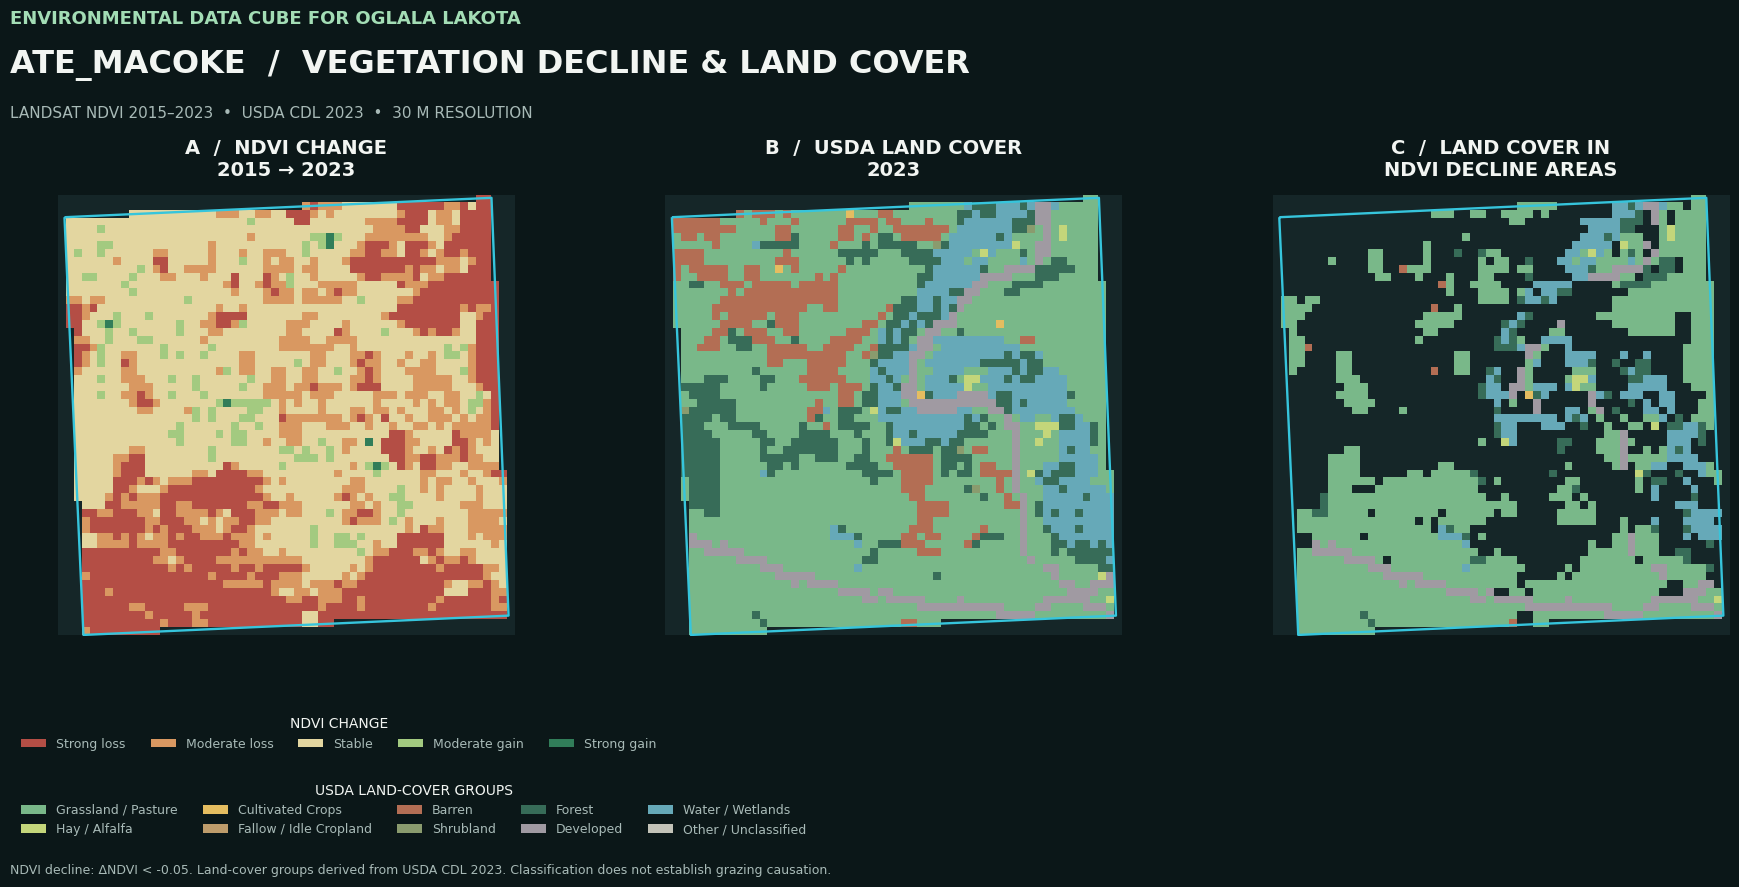


ATE_MACOKE — NDVI DECLINE BY LAND-COVER CLASS
Land cover                     Valid ha   Moderate loss    Strong loss     Total loss
------------------------------------------------------------------------------------------
Grassland / Pasture              147.69           30.96          57.60          88.56
Hay / Alfalfa                      1.53            0.45           0.54           0.99
Cultivated Crops                   0.36            0.09           0.00           0.09
Fallow / Idle Cropland             0.00            0.00           0.00           0.00
Barren                            27.63            0.45           0.09           0.54
Shrubland                          0.54            0.00           0.00           0.00
Forest                            34.47            7.38           1.44           8.82
Developed                         15.39            3.96           5.94           9.90
Water / Wetlands                  31.41           13.41           2.43          15.84
Ot

In [43]:

# ======================================================================
# ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
# NOTEBOOK 13 — ATE_MACOKE LAND-COVER & NDVI DECLINE OVERLAY
#
# A: NDVI Change, 2015–2023
# B: USDA CDL Land Cover, 2023
# C: Land Cover Within NDVI Loss Areas
#
# Uses existing 30 m Landsat NDVI and USDA CDL rasters.
# No downloads. No changes to original dissertation cube.
# ======================================================================

from pathlib import Path
from datetime import datetime
from collections import defaultdict
import csv

import numpy as np
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

from rasterio.features import geometry_mask
from rasterio.warp import reproject, Resampling
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# ----------------------------------------------------------------------
# 1. PROJECT PATHS
# ----------------------------------------------------------------------

project = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

source_dir = project / "results" / "SA20_satellite_maps"

ndvi_2015_path = (
    source_dir
    / "Ate_Macoke_Landsat_NDVI_2015_MaySep_Median_30m.tif"
)

ndvi_2023_path = (
    source_dir
    / "Ate_Macoke_Landsat_NDVI_2023_MaySep_Median_30m.tif"
)

cdl_path = (
    project
    / "data"
    / "landcover"
    / "Pine_Ridge_USDA_CDL_2023_30m.tif"
)

parcel_path = (
    project
    / "data"
    / "ate_parcel_wanzi.shp"
)

output_dir = (
    source_dir
    / "Ate_Macoke_Land_Cover_Overlay"
)

for path in [
    ndvi_2015_path,
    ndvi_2023_path,
    cdl_path,
    parcel_path
]:
    if not path.is_file():
        raise FileNotFoundError(path)

output_dir.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)

png_path = output_dir / (
    f"Ate_Macoke_NDVI_CDL_Overlay_{timestamp}.png"
)

pdf_path = output_dir / (
    f"Ate_Macoke_NDVI_CDL_Overlay_{timestamp}.pdf"
)

csv_path = output_dir / (
    f"Ate_Macoke_NDVI_LandCover_Areas_{timestamp}.csv"
)

# ----------------------------------------------------------------------
# 2. LOAD ORIGINAL LANDSAT NDVI RASTERS
# ----------------------------------------------------------------------

def read_ndvi(path):

    with rasterio.open(path) as src:

        data = src.read(
            1,
            masked=True
        ).filled(np.nan).astype(np.float32)

        data[
            ~np.isfinite(data)
            | (data < -1)
            | (data > 1)
        ] = np.nan

        return {
            "data": data,
            "crs": src.crs,
            "transform": src.transform,
            "bounds": src.bounds,
            "shape": src.shape
        }

r2015 = read_ndvi(ndvi_2015_path)
r2023 = read_ndvi(ndvi_2023_path)

if (
    r2015["crs"] != r2023["crs"]
    or r2015["shape"] != r2023["shape"]
    or not np.allclose(
        tuple(r2015["transform"]),
        tuple(r2023["transform"]),
        rtol=0,
        atol=1e-7
    )
):
    raise ValueError(
        "2015 and 2023 Landsat rasters are not aligned."
    )

if r2015["crs"].to_epsg() != 32613:
    raise ValueError(
        "Expected Landsat grid in EPSG:32613."
    )

ndvi_2015 = r2015["data"]
ndvi_2023 = r2023["data"]

height, width = r2015["shape"]
transform = r2015["transform"]
bounds = r2015["bounds"]

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]

pixel_area_ha = abs(
    transform.a * transform.e
    - transform.b * transform.d
) / 10000

# ----------------------------------------------------------------------
# 3. LOAD ATE_MACOKE PARCEL BOUNDARY
# ----------------------------------------------------------------------

parcel = gpd.read_file(parcel_path)

if parcel.empty or parcel.crs is None:
    raise ValueError(
        "Parcel boundary is empty or missing CRS."
    )

parcel = parcel.to_crs(r2015["crs"])

parcel = parcel[
    parcel.geometry.notna()
    & ~parcel.geometry.is_empty
].copy()

if parcel.empty:
    raise ValueError(
        "No usable parcel geometry."
    )

parcel_mask = geometry_mask(
    parcel.geometry,
    out_shape=(height, width),
    transform=transform,
    invert=True,
    all_touched=False
)

if not parcel_mask.any():
    raise ValueError(
        "No parcel pixels intersect the Landsat grid."
    )

# ----------------------------------------------------------------------
# 4. ALIGN USDA CDL TO THE LANDSAT GRID
# ----------------------------------------------------------------------

cdl_aligned = np.zeros(
    (height, width),
    dtype=np.uint8
)

with rasterio.open(cdl_path) as src:

    if src.crs is None:
        raise ValueError(
            "CDL raster has no coordinate reference system."
        )

    reproject(
        source=rasterio.band(src, 1),
        destination=cdl_aligned,
        src_transform=src.transform,
        src_crs=src.crs,
        src_nodata=src.nodata,
        dst_transform=transform,
        dst_crs=r2015["crs"],
        dst_nodata=0,
        resampling=Resampling.nearest
    )

# ----------------------------------------------------------------------
# 5. CALCULATE NDVI CHANGE
# ----------------------------------------------------------------------

valid_ndvi = (
    parcel_mask
    & np.isfinite(ndvi_2015)
    & np.isfinite(ndvi_2023)
)

change = np.full(
    (height, width),
    np.nan,
    dtype=np.float32
)

change[valid_ndvi] = (
    ndvi_2023[valid_ndvi]
    - ndvi_2015[valid_ndvi]
)

change_classes = np.zeros(
    (height, width),
    dtype=np.uint8
)

change_classes[
    valid_ndvi & (change < -0.10)
] = 1

change_classes[
    valid_ndvi
    & (change >= -0.10)
    & (change < -0.05)
] = 2

change_classes[
    valid_ndvi
    & (change >= -0.05)
    & (change <= 0.05)
] = 3

change_classes[
    valid_ndvi
    & (change > 0.05)
    & (change <= 0.10)
] = 4

change_classes[
    valid_ndvi & (change > 0.10)
] = 5

# Moderate or strong NDVI decline.
loss_mask = (
    valid_ndvi
    & (change < -0.05)
)

# ----------------------------------------------------------------------
# 6. LAND-COVER GROUPS
# ----------------------------------------------------------------------

# Group original USDA CDL codes into interpretable categories.
# Original codes remain available in cdl_aligned.

crop_codes = set(range(1, 61)) | {
    66, 67, 68, 69, 71, 72, 74, 75, 76, 77,
    204, 205, 206, 207, 208, 209, 210, 211,
    212, 213, 214, 215, 216, 217, 218, 219,
    220, 221, 222, 223, 224, 225, 226, 227,
    228, 229, 230, 231, 232, 233, 234, 235,
    236, 237, 238, 239, 240, 241, 242, 243,
    244, 245, 246, 247, 248, 249, 250, 254
}

hay_codes = {36, 37}

grass_codes = {176}
barren_codes = {65, 131}
shrub_codes = {64, 152}
forest_codes = {63, 141, 142, 143}
developed_codes = {82, 121, 122, 123, 124}
water_wetland_codes = {83, 87, 111, 190, 195}
fallow_codes = {61}

group_names = {
    1: "Grassland / Pasture",
    2: "Hay / Alfalfa",
    3: "Cultivated Crops",
    4: "Fallow / Idle Cropland",
    5: "Barren",
    6: "Shrubland",
    7: "Forest",
    8: "Developed",
    9: "Water / Wetlands",
    10: "Other / Unclassified"
}

group_colors = {
    1: "#79B889",
    2: "#C4D67A",
    3: "#E5BD60",
    4: "#BE9C6B",
    5: "#B36E54",
    6: "#8A9B6E",
    7: "#376C58",
    8: "#A09AA2",
    9: "#66A9B8",
    10: "#C3C3B8"
}

def group_cdl(code):

    code = int(code)

    if code == 0:
        return 0

    if code in grass_codes:
        return 1

    if code in hay_codes:
        return 2

    if code in crop_codes:
        return 3

    if code in fallow_codes:
        return 4

    if code in barren_codes:
        return 5

    if code in shrub_codes:
        return 6

    if code in forest_codes:
        return 7

    if code in developed_codes:
        return 8

    if code in water_wetland_codes:
        return 9

    return 10

grouped_cdl = np.zeros(
    (height, width),
    dtype=np.uint8
)

for code in np.unique(cdl_aligned):

    if code == 0:
        continue

    grouped_cdl[
        cdl_aligned == code
    ] = group_cdl(code)

# Display only within the parcel.
grouped_cdl[~parcel_mask] = 0

# Show land cover only where NDVI declined.
loss_landcover = np.where(
    loss_mask,
    grouped_cdl,
    0
).astype(np.uint8)

# ----------------------------------------------------------------------
# 7. AREA STATISTICS
# ----------------------------------------------------------------------

records = []

for group_id, group_name in group_names.items():

    group_mask = (
        grouped_cdl == group_id
    )

    classified_valid = (
        group_mask & valid_ndvi
    )

    moderate_loss = (
        classified_valid
        & (change >= -0.10)
        & (change < -0.05)
    )

    strong_loss = (
        classified_valid
        & (change < -0.10)
    )

    total_pixels = int(
        classified_valid.sum()
    )

    moderate_pixels = int(
        moderate_loss.sum()
    )

    strong_pixels = int(
        strong_loss.sum()
    )

    records.append({
        "land_cover": group_name,
        "valid_area_ha": (
            total_pixels * pixel_area_ha
        ),
        "moderate_loss_ha": (
            moderate_pixels * pixel_area_ha
        ),
        "strong_loss_ha": (
            strong_pixels * pixel_area_ha
        ),
        "total_loss_ha": (
            (moderate_pixels + strong_pixels)
            * pixel_area_ha
        ),
        "loss_percent_of_valid_class": (
            100 * (moderate_pixels + strong_pixels)
            / total_pixels
            if total_pixels else 0
        )
    })

# ----------------------------------------------------------------------
# 8. MAP STYLING
# ----------------------------------------------------------------------

BG = "#0B1718"
PANEL = "#152628"
WHITE = "#F2F5F2"
MUTED = "#A8BAB7"
CYAN = "#36C5DC"

change_colors = [
    "#B44E45",
    "#D99861",
    "#E3D6A0",
    "#A3CA80",
    "#317D59"
]

change_cmap = ListedColormap(
    change_colors
)

change_cmap.set_bad(PANEL)

change_norm = BoundaryNorm(
    np.arange(0.5, 6.5),
    5
)

land_colors = [
    group_colors[i]
    for i in range(1, 11)
]

land_cmap = ListedColormap(
    land_colors
)

land_cmap.set_bad(PANEL)

land_norm = BoundaryNorm(
    np.arange(0.5, 11.5),
    10
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 9),
    facecolor=BG
)

fig.subplots_adjust(
    left=0.035,
    right=0.965,
    top=0.77,
    bottom=0.28,
    wspace=0.10
)

fig.text(
    0.035,
    0.96,
    "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA",
    color="#A3DDB5",
    fontsize=13,
    fontweight="bold"
)

fig.text(
    0.035,
    0.905,
    "ATE_MACOKE  /  VEGETATION DECLINE & LAND COVER",
    color=WHITE,
    fontsize=23,
    fontweight="bold"
)

fig.text(
    0.035,
    0.855,
    "LANDSAT NDVI 2015–2023  •  USDA CDL 2023  •  30 M RESOLUTION",
    color=MUTED,
    fontsize=11
)

# ----------------------------------------------------------------------
# 9. DRAW THREE PANELS
# ----------------------------------------------------------------------

for ax in axes:

    ax.set_facecolor(PANEL)
    ax.set_aspect("equal")
    ax.axis("off")

    ax.set_xlim(
        bounds.left,
        bounds.right
    )

    ax.set_ylim(
        bounds.bottom,
        bounds.top
    )

# A — NDVI CHANGE

axes[0].imshow(
    np.ma.masked_equal(
        change_classes,
        0
    ),
    extent=extent,
    origin="upper",
    cmap=change_cmap,
    norm=change_norm,
    interpolation="nearest"
)

axes[0].set_title(
    "A  /  NDVI CHANGE\n2015 → 2023",
    color=WHITE,
    fontsize=14,
    fontweight="bold",
    pad=14
)

# B — LAND COVER

axes[1].imshow(
    np.ma.masked_equal(
        grouped_cdl,
        0
    ),
    extent=extent,
    origin="upper",
    cmap=land_cmap,
    norm=land_norm,
    interpolation="nearest"
)

axes[1].set_title(
    "B  /  USDA LAND COVER\n2023",
    color=WHITE,
    fontsize=14,
    fontweight="bold",
    pad=14
)

# C — LAND COVER INSIDE NDVI LOSS AREAS

axes[2].imshow(
    np.ma.masked_equal(
        loss_landcover,
        0
    ),
    extent=extent,
    origin="upper",
    cmap=land_cmap,
    norm=land_norm,
    interpolation="nearest"
)

axes[2].set_title(
    "C  /  LAND COVER IN\nNDVI DECLINE AREAS",
    color=WHITE,
    fontsize=14,
    fontweight="bold",
    pad=14
)

# Parcel boundary in all three panels.
for ax in axes:

    parcel.boundary.plot(
        ax=ax,
        color=CYAN,
        linewidth=1.7,
        zorder=10
    )

# ----------------------------------------------------------------------
# 10. LEGENDS
# ----------------------------------------------------------------------

change_handles = [
    Patch(
        facecolor=color,
        edgecolor="none",
        label=label
    )
    for color, label in zip(
        change_colors,
        [
            "Strong loss",
            "Moderate loss",
            "Stable",
            "Moderate gain",
            "Strong gain"
        ]
    )
]

land_handles = [
    Patch(
        facecolor=group_colors[i],
        edgecolor="none",
        label=group_names[i]
    )
    for i in group_names
]

legend_a = fig.legend(
    handles=change_handles,
    loc="lower left",
    bbox_to_anchor=(0.035, 0.14),
    ncol=5,
    frameon=False,
    fontsize=9,
    title="NDVI CHANGE"
)

legend_b = fig.legend(
    handles=land_handles,
    loc="lower left",
    bbox_to_anchor=(0.035, 0.045),
    ncol=5,
    frameon=False,
    fontsize=9,
    title="USDA LAND-COVER GROUPS"
)

for legend in [legend_a, legend_b]:

    legend.get_title().set_color(WHITE)

    for item in legend.get_texts():
        item.set_color(MUTED)

fig.text(
    0.035,
    0.015,
    (
        "NDVI decline: ΔNDVI < -0.05. "
        "Land-cover groups derived from USDA CDL 2023. "
        "Classification does not establish grazing causation."
    ),
    color=MUTED,
    fontsize=9
)

# ----------------------------------------------------------------------
# 11. SAVE FIGURE
# ----------------------------------------------------------------------

fig.savefig(
    png_path,
    dpi=300,
    facecolor=BG,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    facecolor=BG,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------------------
# 12. SAVE AREA STATISTICS
# ----------------------------------------------------------------------

with open(
    csv_path,
    "x",
    newline="",
    encoding="utf-8"
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=list(records[0].keys())
    )

    writer.writeheader()
    writer.writerows(records)

# ----------------------------------------------------------------------
# 13. PRINT RESULTS
# ----------------------------------------------------------------------

print("\n" + "=" * 90)
print("ATE_MACOKE — NDVI DECLINE BY LAND-COVER CLASS")
print("=" * 90)

print(
    f"{'Land cover':<27}"
    f"{'Valid ha':>12}"
    f"{'Moderate loss':>16}"
    f"{'Strong loss':>15}"
    f"{'Total loss':>15}"
)

print("-" * 90)

for row in records:

    print(
        f"{row['land_cover']:<27}"
        f"{row['valid_area_ha']:>12,.2f}"
        f"{row['moderate_loss_ha']:>16,.2f}"
        f"{row['strong_loss_ha']:>15,.2f}"
        f"{row['total_loss_ha']:>15,.2f}"
    )

print("-" * 90)

print(
    "\nTotal NDVI loss area:",
    f"{loss_mask.sum() * pixel_area_ha:,.2f} ha"
)

print("\nOUTPUTS")
print("PNG:", png_path)
print("PDF:", pdf_path)
print("CSV:", csv_path)

print("\nOriginal dissertation cube: UNCHANGED")
print("Notebook 09: UNCHANGED")
print("Existing Landsat rasters: UNCHANGED")

print("=" * 90)


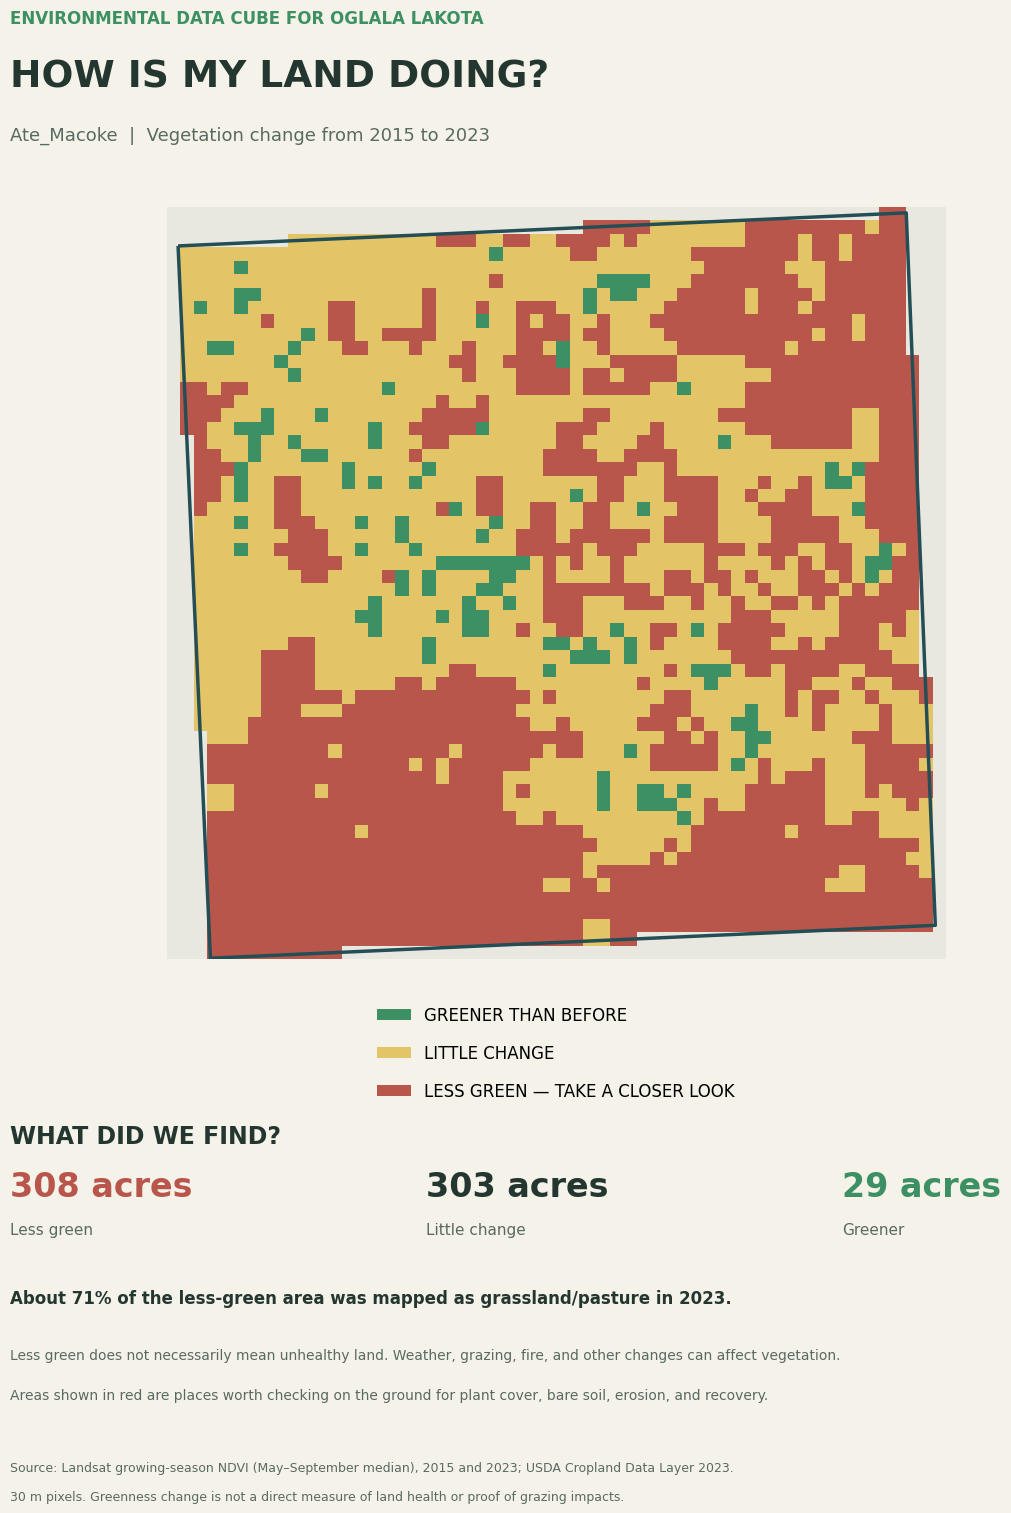


ATE_MACOKE — COMMUNITY LAND CONDITION MAP
Mapped area: 640.1 acres
Less green: 308.2 acres
Little change: 303.1 acres
Greener: 28.7 acres
Less-green area classified as grassland/pasture: 218.8 acres (71.0%)

SAVED FILES
PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Community_Land_Maps/Ate_Macoke_Community_Map_20261016_205527_337603.png
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Community_Land_Maps/Ate_Macoke_Community_Map_20261016_205527_337603.pdf
CSV: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Community_Land_Maps/Ate_Macoke_Community_Summary_20261016_205527_337603.csv

Original dissertation cube: UNCHANGED
Notebook 09: UNCHANGED
Existing Landsat and CDL rasters: UNCHANGED


In [44]:

# ======================================================================
# ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
# NOTEBOOK 13 — COMMUNITY LAND CONDITION MAP
#
# ATE_MACOKE | HOW IS MY LAND DOING?
#
# Green  = Greener than in 2015
# Yellow = Little change
# Red    = Less green than in 2015; worth a closer look
#
# Uses existing Landsat NDVI (2015, 2023) and USDA CDL (2023).
# No downloads. Original dissertation data remain unchanged.
# ======================================================================

from pathlib import Path
from datetime import datetime
import textwrap
import csv

import numpy as np
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

from rasterio.features import geometry_mask
from rasterio.warp import reproject, Resampling
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch, Rectangle

# ----------------------------------------------------------------------
# 1. EXISTING PROJECT FILES
# ----------------------------------------------------------------------

project = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

source_dir = project / "results" / "SA20_satellite_maps"

ndvi_2015_path = (
    source_dir
    / "Ate_Macoke_Landsat_NDVI_2015_MaySep_Median_30m.tif"
)

ndvi_2023_path = (
    source_dir
    / "Ate_Macoke_Landsat_NDVI_2023_MaySep_Median_30m.tif"
)

cdl_path = (
    project / "data" / "landcover"
    / "Pine_Ridge_USDA_CDL_2023_30m.tif"
)

parcel_path = project / "data" / "ate_parcel_wanzi.shp"

output_dir = (
    source_dir / "Ate_Macoke_Community_Land_Maps"
)

for path in [
    ndvi_2015_path,
    ndvi_2023_path,
    cdl_path,
    parcel_path
]:
    if not path.is_file():
        raise FileNotFoundError(path)

output_dir.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

png_path = output_dir / f"Ate_Macoke_Community_Map_{timestamp}.png"
pdf_path = output_dir / f"Ate_Macoke_Community_Map_{timestamp}.pdf"
csv_path = output_dir / f"Ate_Macoke_Community_Summary_{timestamp}.csv"

# ----------------------------------------------------------------------
# 2. READ THE TWO LANDSAT NDVI RASTERS
# ----------------------------------------------------------------------

def read_ndvi(path):

    with rasterio.open(path) as src:

        arr = src.read(1, masked=True).filled(np.nan)
        arr = arr.astype(np.float32)

        arr[
            ~np.isfinite(arr)
            | (arr < -1)
            | (arr > 1)
        ] = np.nan

        return (
            arr,
            src.crs,
            src.transform,
            src.bounds
        )

ndvi_2015, crs, transform, bounds = read_ndvi(ndvi_2015_path)
ndvi_2023, crs_2023, transform_2023, bounds_2023 = read_ndvi(ndvi_2023_path)

if (
    crs != crs_2023
    or ndvi_2015.shape != ndvi_2023.shape
    or not np.allclose(
        tuple(transform),
        tuple(transform_2023),
        rtol=0,
        atol=1e-7
    )
):
    raise ValueError("2015 and 2023 NDVI grids do not align.")

if crs is None or crs.to_epsg() != 32613:
    raise ValueError("Expected EPSG:32613 Landsat grid.")

height, width = ndvi_2015.shape

pixel_area_ha = abs(
    transform.a * transform.e
    - transform.b * transform.d
) / 10000.0

acres_per_pixel = pixel_area_ha * 2.4710538147

# ----------------------------------------------------------------------
# 3. PARCEL BOUNDARY AND MASK
# ----------------------------------------------------------------------

parcel = gpd.read_file(parcel_path)

if parcel.empty or parcel.crs is None:
    raise ValueError("Parcel boundary missing or invalid.")

parcel = parcel.to_crs(crs)

parcel = parcel[
    parcel.geometry.notna()
    & ~parcel.geometry.is_empty
].copy()

parcel_mask = geometry_mask(
    parcel.geometry,
    out_shape=(height, width),
    transform=transform,
    invert=True,
    all_touched=False
)

# ----------------------------------------------------------------------
# 4. NDVI CHANGE: THREE EASY-TO-UNDERSTAND CLASSES
# ----------------------------------------------------------------------

valid = (
    parcel_mask
    & np.isfinite(ndvi_2015)
    & np.isfinite(ndvi_2023)
)

change = np.full(
    (height, width),
    np.nan,
    dtype=np.float32
)

change[valid] = (
    ndvi_2023[valid] - ndvi_2015[valid]
)

# 1 = Less green
# 2 = Little change
# 3 = Greener

classes = np.zeros(
    (height, width),
    dtype=np.uint8
)

classes[valid & (change < -0.05)] = 1

classes[
    valid
    & (change >= -0.05)
    & (change <= 0.05)
] = 2

classes[valid & (change > 0.05)] = 3

loss_pixels = int((classes == 1).sum())
stable_pixels = int((classes == 2).sum())
gain_pixels = int((classes == 3).sum())
valid_pixels = int(valid.sum())

loss_acres = loss_pixels * acres_per_pixel
stable_acres = stable_pixels * acres_per_pixel
gain_acres = gain_pixels * acres_per_pixel
mapped_acres = valid_pixels * acres_per_pixel

# ----------------------------------------------------------------------
# 5. CHECK HOW MUCH DECLINE OCCURS ON GRASSLAND / PASTURE
# ----------------------------------------------------------------------

cdl = np.zeros(
    (height, width),
    dtype=np.uint8
)

with rasterio.open(cdl_path) as src:

    reproject(
        source=rasterio.band(src, 1),
        destination=cdl,
        src_transform=src.transform,
        src_crs=src.crs,
        src_nodata=src.nodata,
        dst_transform=transform,
        dst_crs=crs,
        dst_nodata=0,
        resampling=Resampling.nearest
    )

# Official USDA CDL class 176 = Grassland / Pasture
grassland_loss_pixels = int(
    ((classes == 1) & (cdl == 176)).sum()
)

grassland_loss_acres = (
    grassland_loss_pixels * acres_per_pixel
)

grassland_loss_pct = (
    100 * grassland_loss_pixels / loss_pixels
    if loss_pixels else 0
)

# ----------------------------------------------------------------------
# 6. COMMUNITY MAP DESIGN
# ----------------------------------------------------------------------

BG = "#F5F2E9"
PAPER = "#FFFFFF"
INK = "#23362F"
MUTED = "#596A60"
GREEN = "#3C9063"
YELLOW = "#E3C568"
RED = "#B9564C"
BORDER = "#244E55"

cmap = ListedColormap([
    RED,
    YELLOW,
    GREEN
])

cmap.set_bad("#E8E8E0")

norm = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5],
    ncolors=3
)

fig = plt.figure(
    figsize=(13, 16),
    facecolor=BG
)

# Title and introductory text

fig.text(
    0.08, 0.955,
    "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA",
    color=GREEN,
    fontsize=12,
    fontweight="bold"
)

fig.text(
    0.08, 0.915,
    "HOW IS MY LAND DOING?",
    color=INK,
    fontsize=27,
    fontweight="bold"
)

fig.text(
    0.08, 0.882,
    "Ate_Macoke  |  Vegetation change from 2015 to 2023",
    color=MUTED,
    fontsize=13
)

# Main map

ax = fig.add_axes([0.10, 0.37, 0.80, 0.47])

ax.set_facecolor("#E8E8E0")

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]

ax.imshow(
    np.ma.masked_equal(classes, 0),
    extent=extent,
    origin="upper",
    cmap=cmap,
    norm=norm,
    interpolation="nearest"
)

parcel.boundary.plot(
    ax=ax,
    color=BORDER,
    linewidth=2.5,
    zorder=10
)

ax.set_xlim(bounds.left, bounds.right)
ax.set_ylim(bounds.bottom, bounds.top)
ax.set_aspect("equal")
ax.axis("off")

# Legend

legend_handles = [
    Patch(
        facecolor=GREEN,
        edgecolor="none",
        label="GREENER THAN BEFORE"
    ),
    Patch(
        facecolor=YELLOW,
        edgecolor="none",
        label="LITTLE CHANGE"
    ),
    Patch(
        facecolor=RED,
        edgecolor="none",
        label="LESS GREEN — TAKE A CLOSER LOOK"
    )
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.50, 0.35),
    ncol=1,
    frameon=False,
    fontsize=12,
    labelspacing=1.2
)

# ----------------------------------------------------------------------
# 7. SIMPLE LANDOWNER SUMMARY
# ----------------------------------------------------------------------

fig.text(
    0.08, 0.255,
    "WHAT DID WE FIND?",
    color=INK,
    fontsize=17,
    fontweight="bold"
)

fig.text(
    0.08, 0.222,
    f"{loss_acres:,.0f} acres",
    color=RED,
    fontsize=24,
    fontweight="bold"
)

fig.text(
    0.40, 0.222,
    f"{stable_acres:,.0f} acres",
    color=INK,
    fontsize=24,
    fontweight="bold"
)

fig.text(
    0.72, 0.222,
    f"{gain_acres:,.0f} acres",
    color=GREEN,
    fontsize=24,
    fontweight="bold"
)

fig.text(
    0.08, 0.198,
    "Less green",
    color=MUTED,
    fontsize=11
)

fig.text(
    0.40, 0.198,
    "Little change",
    color=MUTED,
    fontsize=11
)

fig.text(
    0.72, 0.198,
    "Greener",
    color=MUTED,
    fontsize=11
)

# Land-cover context

fig.text(
    0.08, 0.155,
    (
        f"About {grassland_loss_pct:.0f}% of the less-green area "
        "was mapped as grassland/pasture in 2023."
    ),
    color=INK,
    fontsize=12,
    fontweight="bold"
)

fig.text(
    0.08, 0.120,
    (
        "Less green does not necessarily mean unhealthy land. "
        "Weather, grazing, fire, and other changes can affect vegetation."
    ),
    color=MUTED,
    fontsize=10
)

fig.text(
    0.08, 0.095,
    (
        "Areas shown in red are places worth checking on the ground "
        "for plant cover, bare soil, erosion, and recovery."
    ),
    color=MUTED,
    fontsize=10
)

# Methods and interpretation

fig.text(
    0.08, 0.050,
    (
        "Source: Landsat growing-season NDVI (May–September median), "
        "2015 and 2023; USDA Cropland Data Layer 2023."
    ),
    color=MUTED,
    fontsize=9
)

fig.text(
    0.08, 0.032,
    (
        "30 m pixels. Greenness change is not a direct measure of "
        "land health or proof of grazing impacts."
    ),
    color=MUTED,
    fontsize=9
)

# ----------------------------------------------------------------------
# 8. SAVE THE MAP
# ----------------------------------------------------------------------

fig.savefig(
    png_path,
    dpi=300,
    facecolor=BG,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    facecolor=BG,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------------------
# 9. SAVE COMMUNITY SUMMARY
# ----------------------------------------------------------------------

records = [
    {"category": "Less green", "acres": loss_acres},
    {"category": "Little change", "acres": stable_acres},
    {"category": "Greener", "acres": gain_acres},
    {
        "category": "Less green on 2023 grassland/pasture",
        "acres": grassland_loss_acres
    }
]

with open(
    csv_path,
    "x",
    newline="",
    encoding="utf-8"
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=["category", "acres"]
    )

    writer.writeheader()
    writer.writerows(records)

# ----------------------------------------------------------------------
# 10. PRINT RESULTS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("ATE_MACOKE — COMMUNITY LAND CONDITION MAP")
print("=" * 70)

print(f"Mapped area: {mapped_acres:,.1f} acres")
print(f"Less green: {loss_acres:,.1f} acres")
print(f"Little change: {stable_acres:,.1f} acres")
print(f"Greener: {gain_acres:,.1f} acres")

print(
    "Less-green area classified as grassland/pasture:",
    f"{grassland_loss_acres:,.1f} acres "
    f"({grassland_loss_pct:.1f}%)"
)

print("\nSAVED FILES")
print("PNG:", png_path)
print("PDF:", pdf_path)
print("CSV:", csv_path)

print("\nOriginal dissertation cube: UNCHANGED")
print("Notebook 09: UNCHANGED")
print("Existing Landsat and CDL rasters: UNCHANGED")
print("=" * 70)


Requesting aerial image...
Image dimensions: 1892 x 1866


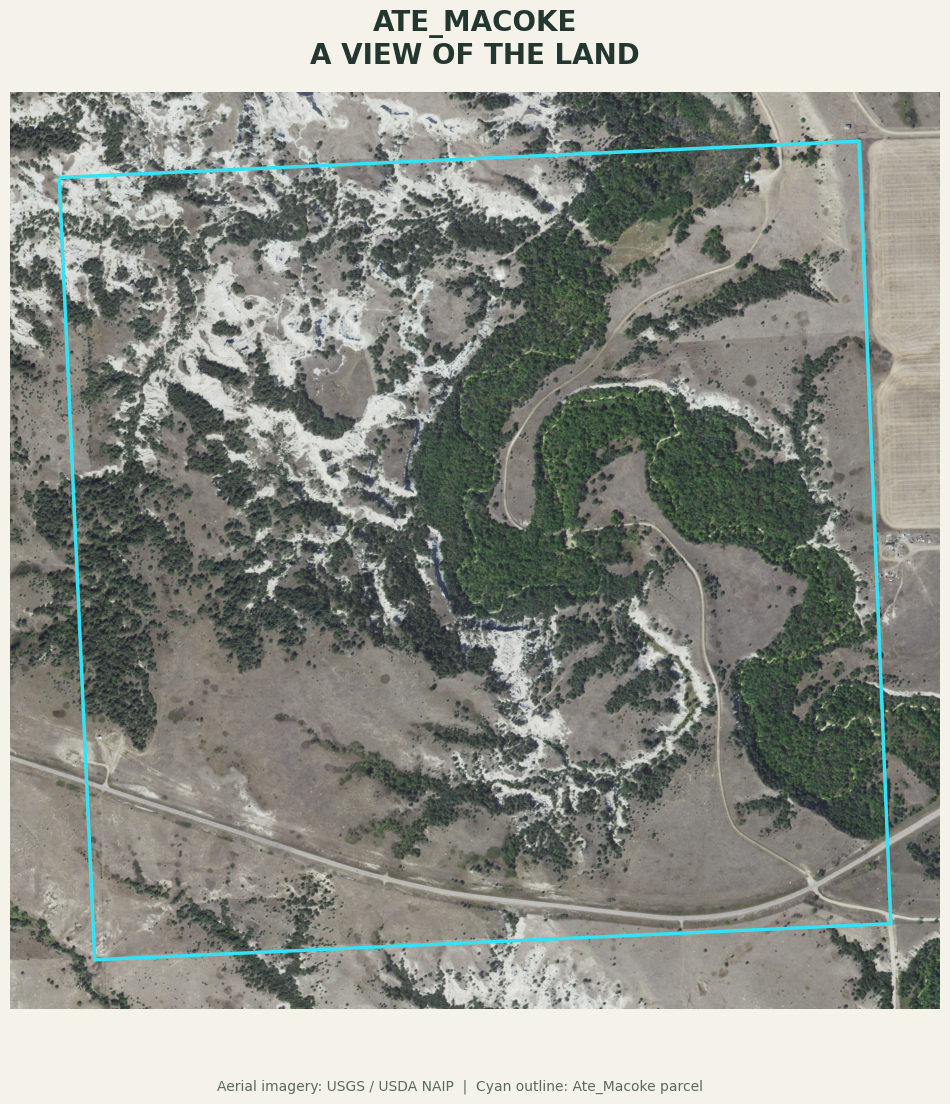


AERIAL IMAGE COMPLETE
GeoTIFF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Aerial_Imagery/Ate_Macoke_NAIP_Aerial_20261016_205950_341947.tif
Map PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Aerial_Imagery/Ate_Macoke_Aerial_Map_20261016_205950_341947.png
Map PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Aerial_Imagery/Ate_Macoke_Aerial_Map_20261016_205950_341947.pdf

Original dissertation cube: UNCHANGED
Notebook 09: UNCHANGED


In [45]:

# ================================================================
# NOTEBOOK 13 — ATE_MACOKE TRUE-COLOR AERIAL PHOTOGRAPH
# Source: USGS / USDA National Agriculture Imagery Program
#
# No Google Earth, no Landsat recomputation.
# Original dissertation files remain unchanged.
# ================================================================

from pathlib import Path
from datetime import datetime
from io import BytesIO
import math

import requests
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from PIL import Image
from rasterio.io import MemoryFile
from rasterio.transform import from_bounds

# ------------------------------------------------
# 1. EXISTING PARCEL BOUNDARY
# ------------------------------------------------

project = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

parcel_path = project / "data" / "ate_parcel_wanzi.shp"

output_dir = (
    project / "results"
    / "SA20_satellite_maps"
    / "Ate_Macoke_Aerial_Imagery"
)

if not parcel_path.is_file():
    raise FileNotFoundError(parcel_path)

parcel = gpd.read_file(parcel_path)

if parcel.empty or parcel.crs is None:
    raise ValueError("Parcel boundary is missing or invalid.")

parcel = parcel.to_crs("EPSG:32613")

# ------------------------------------------------
# 2. DEFINE HIGH-RESOLUTION IMAGE EXTENT
# ------------------------------------------------

xmin, ymin, xmax, ymax = parcel.total_bounds

# Add 100 m of surrounding landscape.
padding = 100

xmin -= padding
ymin -= padding
xmax += padding
ymax += padding

# Request approximately 1 m display resolution.
# Limit image size to avoid oversized server requests.
resolution = 1.0

width = min(
    4000,
    math.ceil((xmax - xmin) / resolution)
)

height = min(
    4000,
    math.ceil((ymax - ymin) / resolution)
)

print("Requesting aerial image...")
print("Image dimensions:", width, "x", height)

# ------------------------------------------------
# 3. USGS NAIP IMAGE SERVICE
# ------------------------------------------------

service = (
    "https://imagery.nationalmap.gov/arcgis/rest/"
    "services/USGSNAIPImagery/ImageServer/exportImage"
)

params = {
    "f": "image",
    "bbox": f"{xmin},{ymin},{xmax},{ymax}",
    "bboxSR": "32613",
    "imageSR": "32613",
    "size": f"{width},{height}",
    "format": "png",
    "interpolation": "RSP_BilinearInterpolation",
    "mosaicRule": '{"mosaicMethod":"esriMosaicNorthwest"}'
}

response = requests.get(
    service,
    params=params,
    timeout=180
)

response.raise_for_status()

if not response.content.startswith(b"\x89PNG"):
    raise RuntimeError(
        "USGS did not return a PNG image:\n"
        + response.text[:500]
    )

image = Image.open(BytesIO(response.content)).convert("RGB")

# ------------------------------------------------
# 4. SAVE GEOREFERENCED IMAGE
# ------------------------------------------------

output_dir.mkdir(parents=True, exist_ok=True)

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

tif_path = output_dir / f"Ate_Macoke_NAIP_Aerial_{stamp}.tif"
png_path = output_dir / f"Ate_Macoke_Aerial_Map_{stamp}.png"
pdf_path = output_dir / f"Ate_Macoke_Aerial_Map_{stamp}.pdf"

transform = from_bounds(
    xmin, ymin, xmax, ymax,
    image.width, image.height
)

import numpy as np
rgb = np.asarray(image)

with rasterio.open(
    tif_path,
    "w",
    driver="GTiff",
    height=image.height,
    width=image.width,
    count=3,
    dtype="uint8",
    crs="EPSG:32613",
    transform=transform,
    compress="deflate",
    photometric="RGB"
) as dst:

    for band in range(3):
        dst.write(rgb[:, :, band], band + 1)

    dst.update_tags(
        source="USGS National Map / USDA NAIP",
        imagery_date="Consult USGS source mosaic metadata",
        study_area="Ate_Macoke",
        purpose="Community land visualization"
    )

# ------------------------------------------------
# 5. CREATE CLEAN COMMUNITY SATELLITE MAP
# ------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 12),
    facecolor="#F5F2E9"
)

ax.imshow(
    rgb,
    extent=[xmin, xmax, ymin, ymax],
    origin="upper"
)

parcel.boundary.plot(
    ax=ax,
    color="#35E1F2",
    linewidth=2.5,
    zorder=10
)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.axis("off")

ax.set_title(
    "ATE_MACOKE\nA VIEW OF THE LAND",
    fontsize=20,
    fontweight="bold",
    color="#23362F",
    pad=20
)

fig.text(
    0.5,
    0.045,
    "Aerial imagery: USGS / USDA NAIP  |  Cyan outline: Ate_Macoke parcel",
    ha="center",
    fontsize=10,
    color="#596A60"
)

fig.savefig(
    png_path,
    dpi=300,
    facecolor="#F5F2E9",
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    facecolor="#F5F2E9",
    bbox_inches="tight"
)

plt.show()

print("\nAERIAL IMAGE COMPLETE")
print("GeoTIFF:", tif_path)
print("Map PNG:", png_path)
print("Map PDF:", pdf_path)
print("\nOriginal dissertation cube: UNCHANGED")
print("Notebook 09: UNCHANGED")


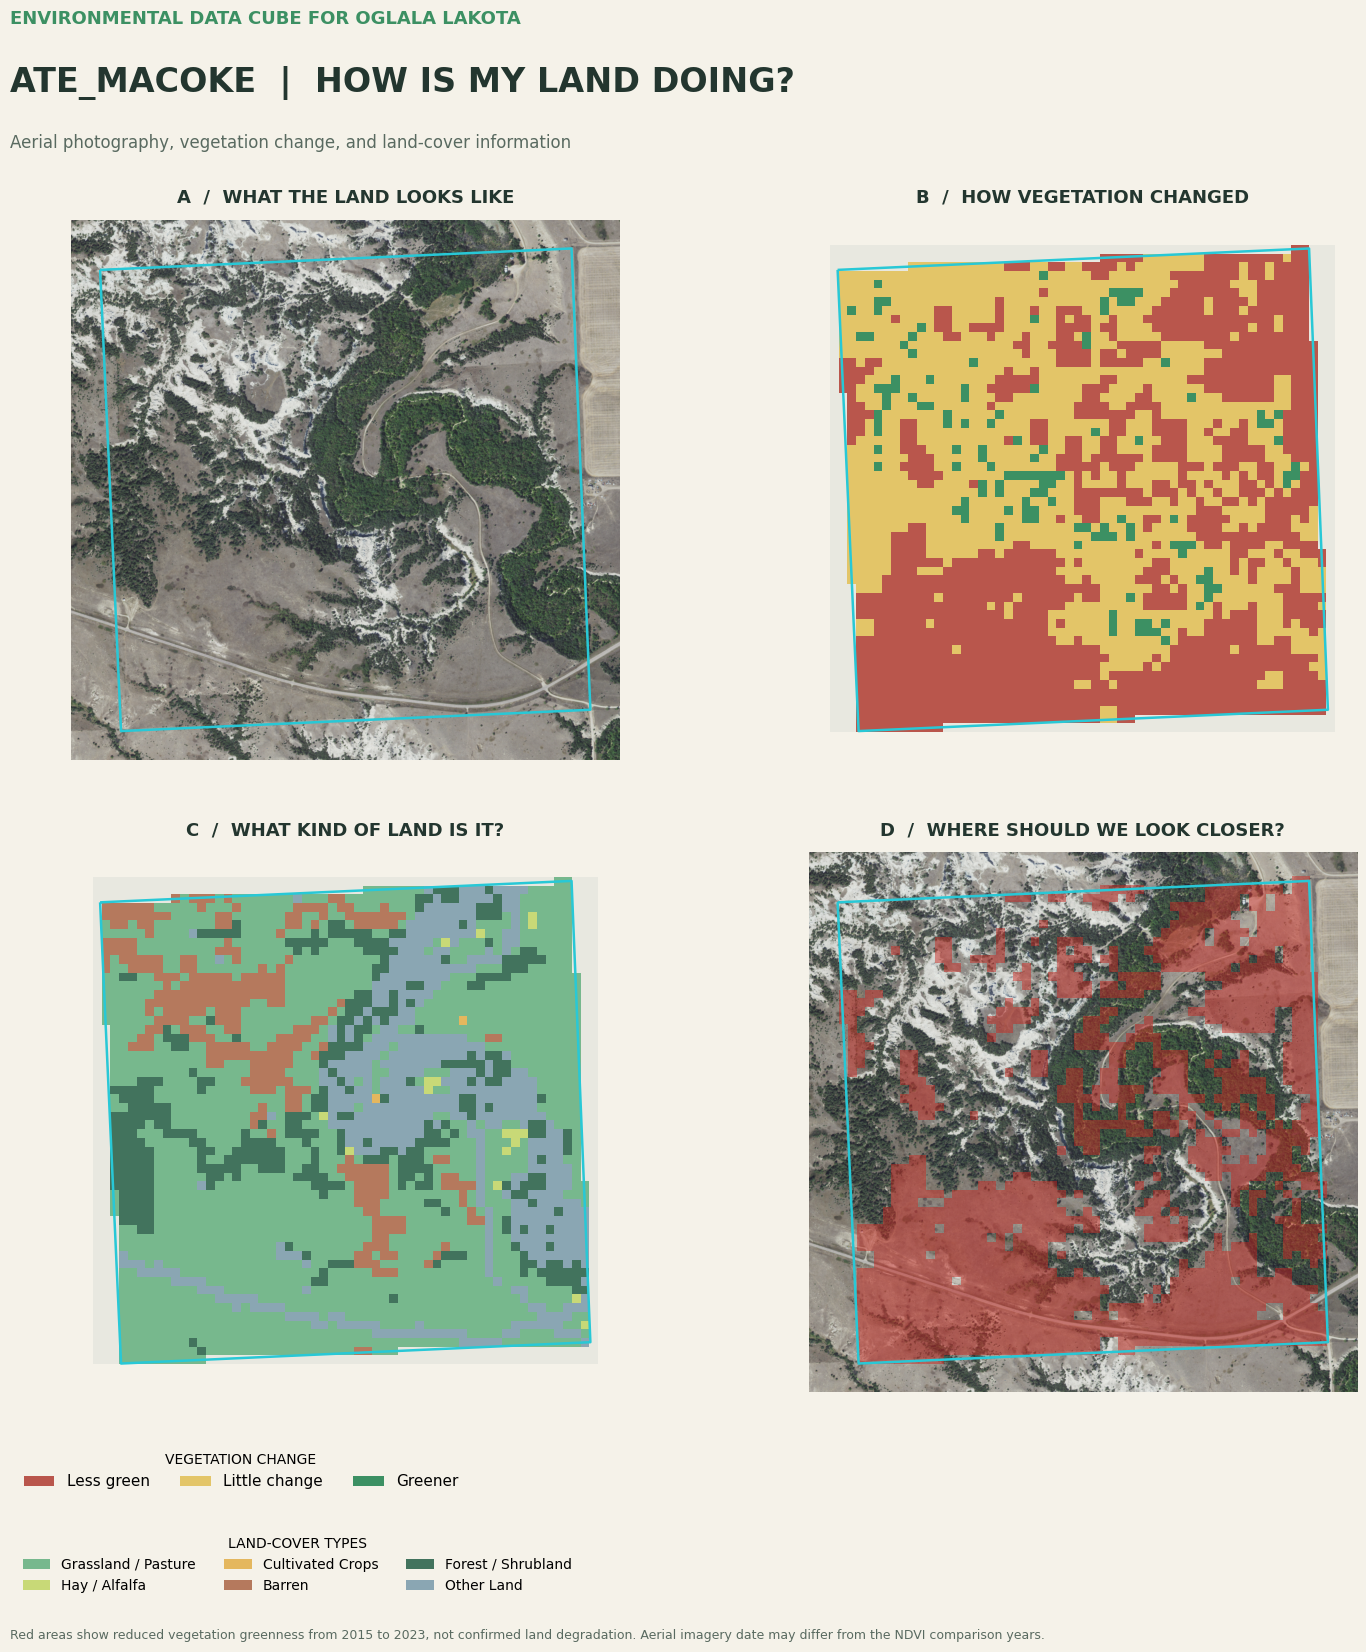


ATE_MACOKE — FOUR-PANEL COMMUNITY LAND MAP COMPLETE

Aerial source: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Aerial_Imagery/Ate_Macoke_NAIP_Aerial_20261016_205950_341947.tif
PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Community_Land_Maps/Ate_Macoke_Four_Panel_20261016_210103_365962.png
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Community_Land_Maps/Ate_Macoke_Four_Panel_20261016_210103_365962.pdf

Original dissertation cube: UNCHANGED
Notebook 09: UNCHANGED
Existing raster datasets: UNCHANGED


In [46]:

# ======================================================================
# ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
# NOTEBOOK 13 — FOUR-PANEL COMMUNITY LAND MAP
#
# A. Actual aerial photograph
# B. Vegetation change, 2015–2023
# C. USDA land-cover classification, 2023
# D. Areas of NDVI decline over aerial photograph
#
# Uses existing project files only. No downloads.
# ======================================================================

from pathlib import Path
from datetime import datetime
import numpy as np
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

from rasterio.features import geometry_mask
from rasterio.warp import reproject, Resampling
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# ----------------------------------------------------------------------
# 1. PATHS
# ----------------------------------------------------------------------

project = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

source_dir = project / "results" / "SA20_satellite_maps"

ndvi_2015_path = (
    source_dir / "Ate_Macoke_Landsat_NDVI_2015_MaySep_Median_30m.tif"
)

ndvi_2023_path = (
    source_dir / "Ate_Macoke_Landsat_NDVI_2023_MaySep_Median_30m.tif"
)

cdl_path = (
    project / "data" / "landcover"
    / "Pine_Ridge_USDA_CDL_2023_30m.tif"
)

parcel_path = project / "data" / "ate_parcel_wanzi.shp"

aerial_dir = source_dir / "Ate_Macoke_Aerial_Imagery"

aerial_files = sorted(
    aerial_dir.glob("Ate_Macoke_NAIP_Aerial_*.tif"),
    key=lambda p: p.stat().st_mtime
)

if not aerial_files:
    raise FileNotFoundError(
        "No saved NAIP aerial GeoTIFF found. "
        "Run the previous aerial imagery cell first."
    )

aerial_path = aerial_files[-1]

for path in [
    ndvi_2015_path,
    ndvi_2023_path,
    cdl_path,
    parcel_path
]:
    if not path.is_file():
        raise FileNotFoundError(path)

output_dir = source_dir / "Ate_Macoke_Community_Land_Maps"
output_dir.mkdir(parents=True, exist_ok=True)

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

png_path = output_dir / f"Ate_Macoke_Four_Panel_{stamp}.png"
pdf_path = output_dir / f"Ate_Macoke_Four_Panel_{stamp}.pdf"

# ----------------------------------------------------------------------
# 2. READ EXISTING NDVI
# ----------------------------------------------------------------------

def read_ndvi(path):
    with rasterio.open(path) as src:
        data = src.read(1, masked=True).filled(np.nan)
        data = data.astype(np.float32)
        data[
            ~np.isfinite(data) |
            (data < -1) |
            (data > 1)
        ] = np.nan
        return data, src.crs, src.transform, src.bounds

ndvi15, crs, transform, bounds = read_ndvi(ndvi_2015_path)
ndvi23, crs23, transform23, bounds23 = read_ndvi(ndvi_2023_path)

if (
    crs != crs23
    or ndvi15.shape != ndvi23.shape
    or not np.allclose(
        tuple(transform),
        tuple(transform23),
        rtol=0,
        atol=1e-7
    )
):
    raise ValueError("NDVI grids are not aligned.")

height, width = ndvi15.shape

# ----------------------------------------------------------------------
# 3. PARCEL MASK
# ----------------------------------------------------------------------

parcel = gpd.read_file(parcel_path).to_crs(crs)

parcel_mask = geometry_mask(
    parcel.geometry,
    out_shape=(height, width),
    transform=transform,
    invert=True,
    all_touched=False
)

valid = (
    parcel_mask
    & np.isfinite(ndvi15)
    & np.isfinite(ndvi23)
)

change = np.full(
    (height, width),
    np.nan,
    dtype=np.float32
)

change[valid] = ndvi23[valid] - ndvi15[valid]

classes = np.zeros(
    (height, width),
    dtype=np.uint8
)

classes[valid & (change < -0.05)] = 1
classes[
    valid & (change >= -0.05) & (change <= 0.05)
] = 2
classes[valid & (change > 0.05)] = 3

loss_mask = classes == 1

# ----------------------------------------------------------------------
# 4. USDA LAND-COVER GROUPS
# ----------------------------------------------------------------------

cdl = np.zeros(
    (height, width),
    dtype=np.uint8
)

with rasterio.open(cdl_path) as src:
    reproject(
        source=rasterio.band(src, 1),
        destination=cdl,
        src_transform=src.transform,
        src_crs=src.crs,
        src_nodata=src.nodata,
        dst_transform=transform,
        dst_crs=crs,
        dst_nodata=0,
        resampling=Resampling.nearest
    )

# 1 Grassland/Pasture, 2 Hay, 3 Crops,
# 4 Barren, 5 Forest/Shrubland, 6 Other
land = np.zeros_like(cdl)

land[(cdl == 176)] = 1
land[np.isin(cdl, [36, 37])] = 2
land[np.isin(cdl, [
    1, 4, 5, 6, 21, 23, 24, 28, 29, 33, 53
])] = 3
land[np.isin(cdl, [65, 131])] = 4
land[np.isin(cdl, [63, 64, 141, 142, 143, 152])] = 5

land[
    (cdl != 0) & (land == 0)
] = 6

land[~parcel_mask] = 0

# ----------------------------------------------------------------------
# 5. READ SAVED AERIAL PHOTOGRAPH
# ----------------------------------------------------------------------

with rasterio.open(aerial_path) as src:

    if src.count < 3:
        raise ValueError("Aerial image requires RGB bands.")

    aerial = np.moveaxis(
        src.read([1, 2, 3]),
        0,
        -1
    )

    aerial_bounds = src.bounds
    aerial_crs = src.crs
    aerial_transform = src.transform
    aerial_height = src.height
    aerial_width = src.width

if aerial_crs != crs:
    raise ValueError(
        "Aerial and Landsat CRS differ. "
        "Reprojection is required."
    )

# Project NDVI loss to aerial grid for transparent overlay.
loss_on_aerial = np.zeros(
    (aerial_height, aerial_width),
    dtype=np.uint8
)

reproject(
    source=loss_mask.astype(np.uint8),
    destination=loss_on_aerial,
    src_transform=transform,
    src_crs=crs,
    src_nodata=0,
    dst_transform=aerial_transform,
    dst_crs=aerial_crs,
    dst_nodata=0,
    resampling=Resampling.nearest
)

# ----------------------------------------------------------------------
# 6. COLORS AND FIGURE
# ----------------------------------------------------------------------

BG = "#F5F2E9"
INK = "#23362F"
MUTED = "#596A60"
BORDER = "#28C8D6"

change_cmap = ListedColormap([
    "#B9564C",
    "#E3C568",
    "#3C9063"
])

change_cmap.set_bad("#E8E8E0")

change_norm = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5],
    3
)

land_colors = [
    "#77B88D",
    "#C8D977",
    "#E4B75E",
    "#B5795D",
    "#42735D",
    "#8AA6B3"
]

land_cmap = ListedColormap(land_colors)
land_cmap.set_bad("#E8E8E0")

land_norm = BoundaryNorm(
    np.arange(0.5, 7.5),
    6
)

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 17),
    facecolor=BG
)

fig.subplots_adjust(
    left=0.06,
    right=0.94,
    top=0.85,
    bottom=0.16,
    wspace=0.10,
    hspace=0.17
)

fig.text(
    0.06, 0.965,
    "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA",
    fontsize=13,
    fontweight="bold",
    color="#3C9063"
)

fig.text(
    0.06, 0.925,
    "ATE_MACOKE  |  HOW IS MY LAND DOING?",
    fontsize=24,
    fontweight="bold",
    color=INK
)

fig.text(
    0.06, 0.892,
    "Aerial photography, vegetation change, and land-cover information",
    fontsize=12,
    color=MUTED
)

ndvi_extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]

aerial_extent = [
    aerial_bounds.left,
    aerial_bounds.right,
    aerial_bounds.bottom,
    aerial_bounds.top
]

titles = [
    "A  /  WHAT THE LAND LOOKS LIKE",
    "B  /  HOW VEGETATION CHANGED",
    "C  /  WHAT KIND OF LAND IS IT?",
    "D  /  WHERE SHOULD WE LOOK CLOSER?"
]

for ax, title in zip(axes.flat, titles):
    ax.set_facecolor("#E8E8E0")
    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        color=INK,
        pad=12
    )
    ax.set_aspect("equal")
    ax.axis("off")

# A — AERIAL PHOTOGRAPH

axes[0, 0].imshow(
    aerial,
    extent=aerial_extent,
    origin="upper"
)

# B — VEGETATION CHANGE

axes[0, 1].imshow(
    np.ma.masked_equal(classes, 0),
    extent=ndvi_extent,
    origin="upper",
    cmap=change_cmap,
    norm=change_norm,
    interpolation="nearest"
)

# C — LAND COVER

axes[1, 0].imshow(
    np.ma.masked_equal(land, 0),
    extent=ndvi_extent,
    origin="upper",
    cmap=land_cmap,
    norm=land_norm,
    interpolation="nearest"
)

# D — AERIAL WITH DECLINE HIGHLIGHTED

axes[1, 1].imshow(
    aerial,
    extent=aerial_extent,
    origin="upper"
)

# RGBA overlay: red where NDVI declined, transparent elsewhere.
overlay = np.zeros(
    (aerial_height, aerial_width, 4),
    dtype=np.float32
)

overlay[:, :, 0] = 0.80
overlay[:, :, 1] = 0.16
overlay[:, :, 2] = 0.13
overlay[:, :, 3] = np.where(
    loss_on_aerial == 1,
    0.48,
    0.0
)

axes[1, 1].imshow(
    overlay,
    extent=aerial_extent,
    origin="upper",
    interpolation="nearest"
)

# Same map extent on all four panels.
for ax in axes.flat:

    parcel.boundary.plot(
        ax=ax,
        color=BORDER,
        linewidth=1.8,
        zorder=10
    )

    ax.set_xlim(
        aerial_bounds.left,
        aerial_bounds.right
    )

    ax.set_ylim(
        aerial_bounds.bottom,
        aerial_bounds.top
    )

# ----------------------------------------------------------------------
# 7. LEGENDS
# ----------------------------------------------------------------------

change_handles = [
    Patch(facecolor="#B9564C", label="Less green"),
    Patch(facecolor="#E3C568", label="Little change"),
    Patch(facecolor="#3C9063", label="Greener")
]

land_handles = [
    Patch(facecolor=color, label=label)
    for color, label in zip(
        land_colors,
        [
            "Grassland / Pasture",
            "Hay / Alfalfa",
            "Cultivated Crops",
            "Barren",
            "Forest / Shrubland",
            "Other Land"
        ]
    )
]

fig.legend(
    handles=change_handles,
    loc="lower left",
    bbox_to_anchor=(0.06, 0.095),
    ncol=3,
    frameon=False,
    fontsize=11,
    title="VEGETATION CHANGE"
)

fig.legend(
    handles=land_handles,
    loc="lower left",
    bbox_to_anchor=(0.06, 0.035),
    ncol=3,
    frameon=False,
    fontsize=10,
    title="LAND-COVER TYPES"
)

fig.text(
    0.06, 0.015,
    (
        "Red areas show reduced vegetation greenness from 2015 to 2023, "
        "not confirmed land degradation. "
        "Aerial imagery date may differ from the NDVI comparison years."
    ),
    fontsize=9,
    color=MUTED
)

# ----------------------------------------------------------------------
# 8. SAVE
# ----------------------------------------------------------------------

fig.savefig(
    png_path,
    dpi=300,
    facecolor=BG,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    facecolor=BG,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 70)
print("ATE_MACOKE — FOUR-PANEL COMMUNITY LAND MAP COMPLETE")
print("=" * 70)

print("\nAerial source:", aerial_path)
print("PNG:", png_path)
print("PDF:", pdf_path)

print("\nOriginal dissertation cube: UNCHANGED")
print("Notebook 09: UNCHANGED")
print("Existing raster datasets: UNCHANGED")
print("=" * 70)


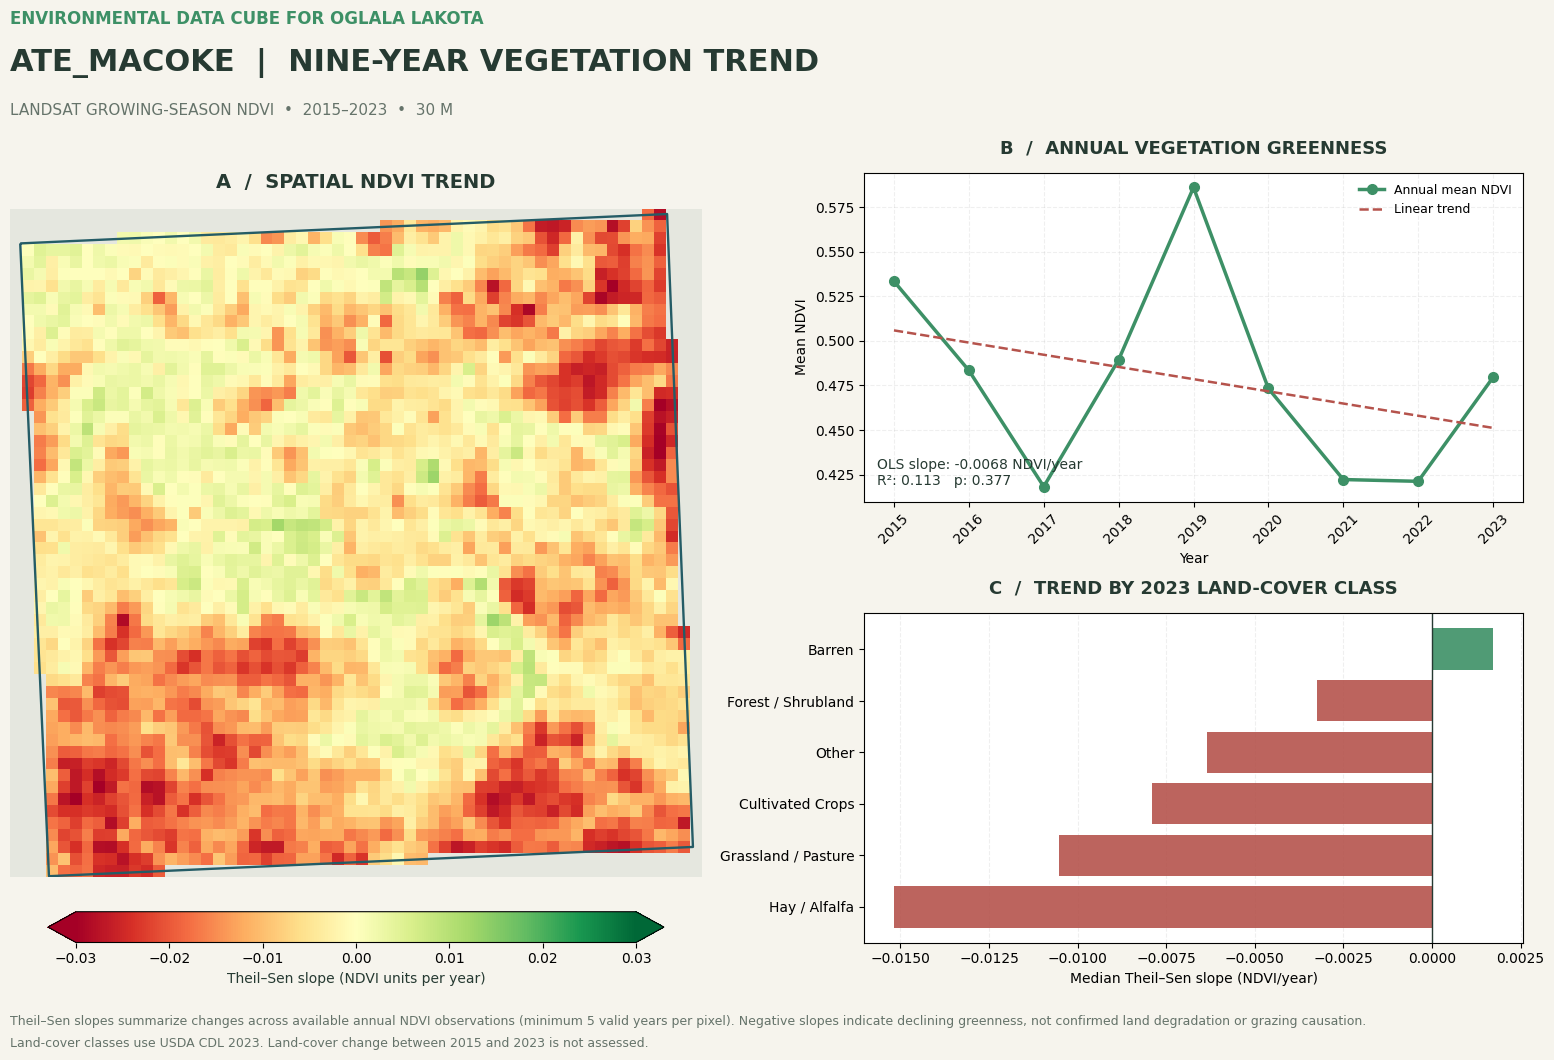


ATE_MACOKE — NINE-YEAR NDVI TREND ANALYSIS

PARCEL-LEVEL ANNUAL TREND
OLS slope: -0.00684 NDVI/year
OLS R²: 0.1130
OLS p-value: 0.3765
Theil–Sen slope: -0.00739 NDVI/year
Theil–Sen 95% CI: [-0.02603, +0.01021]

PIXEL-LEVEL SPATIAL TRENDS
Declining: 143.73 ha
Relatively stable: 107.37 ha
Increasing: 7.92 ha

SAVED FILES
Figure PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_NDVI_Trend_Analysis/Ate_Macoke_NDVI_Trend_20261016_210357_745832.png
Figure PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_NDVI_Trend_Analysis/Ate_Macoke_NDVI_Trend_20261016_210357_745832.pdf
Annual CSV: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_NDVI_Trend_Analysis/Ate_Macoke_Annual_NDVI_20261016_210357_745832.csv
Pixel CSV: /Users/elishawakinyanzi/Documents/ElishaWa

In [47]:

# ======================================================================
# ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
# NOTEBOOK 13 — ATE_MACOKE NINE-YEAR NDVI TREND ANALYSIS
#
# 2015–2023 | Existing Landsat growing-season NDVI rasters
#
# Outputs:
#   1. Publication-quality three-panel figure (PNG + PDF)
#   2. Annual NDVI statistics (CSV)
#   3. Pixel-level trend statistics (CSV)
#   4. Land-cover trend statistics (CSV)
#   5. Spatial Theil–Sen NDVI trend raster (GeoTIFF)
#
# No downloads or modifications to existing dissertation files.
# ======================================================================

from pathlib import Path
from datetime import datetime
from itertools import combinations
import csv

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

from rasterio.features import geometry_mask
from rasterio.warp import reproject, Resampling
from matplotlib.colors import (
    TwoSlopeNorm,
    ListedColormap,
    BoundaryNorm
)
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from scipy.stats import linregress, theilslopes

# ----------------------------------------------------------------------
# 1. PROJECT FILES
# ----------------------------------------------------------------------

project = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

source_dir = project / "results" / "SA20_satellite_maps"

years = np.arange(2015, 2024, dtype=int)

ndvi_paths = {
    int(year): (
        source_dir
        / f"Ate_Macoke_Landsat_NDVI_{year}_MaySep_Median_30m.tif"
    )
    for year in years
}

parcel_path = project / "data" / "ate_parcel_wanzi.shp"

cdl_path = (
    project
    / "data"
    / "landcover"
    / "Pine_Ridge_USDA_CDL_2023_30m.tif"
)

for path in [
    *ndvi_paths.values(),
    parcel_path,
    cdl_path
]:
    if not path.is_file():
        raise FileNotFoundError(path)

output_dir = (
    source_dir / "Ate_Macoke_NDVI_Trend_Analysis"
)

output_dir.mkdir(parents=True, exist_ok=True)

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

figure_png = output_dir / f"Ate_Macoke_NDVI_Trend_{stamp}.png"
figure_pdf = output_dir / f"Ate_Macoke_NDVI_Trend_{stamp}.pdf"

annual_csv = output_dir / f"Ate_Macoke_Annual_NDVI_{stamp}.csv"
pixel_csv = output_dir / f"Ate_Macoke_Pixel_Trend_{stamp}.csv"
land_csv = output_dir / f"Ate_Macoke_LandCover_Trend_{stamp}.csv"

trend_tif = output_dir / f"Ate_Macoke_TheilSen_Trend_{stamp}.tif"

# ----------------------------------------------------------------------
# 2. LOAD ALL NINE EXISTING NDVI RASTERS
# ----------------------------------------------------------------------

stack = []
reference = None

for year in years:

    with rasterio.open(ndvi_paths[int(year)]) as src:

        if src.count != 1:
            raise ValueError(f"{year}: Expected one NDVI band.")

        if reference is None:

            reference = {
                "crs": src.crs,
                "transform": src.transform,
                "shape": src.shape,
                "bounds": src.bounds,
                "profile": src.profile.copy()
            }

        else:

            aligned = (
                src.crs == reference["crs"]
                and src.shape == reference["shape"]
                and np.allclose(
                    tuple(src.transform),
                    tuple(reference["transform"]),
                    atol=1e-7,
                    rtol=0
                )
            )

            if not aligned:
                raise ValueError(
                    f"{year}: NDVI raster is not aligned."
                )

        arr = src.read(1, masked=True).filled(np.nan)
        arr = np.asarray(arr, dtype=np.float32)

        arr[
            ~np.isfinite(arr)
            | (arr < -1)
            | (arr > 1)
        ] = np.nan

        stack.append(arr)

stack = np.stack(stack, axis=0)

if (
    reference["crs"] is None
    or reference["crs"].to_epsg() != 32613
):
    raise ValueError("Expected EPSG:32613.")

height, width = reference["shape"]
transform = reference["transform"]
bounds = reference["bounds"]

pixel_area_ha = abs(
    transform.a * transform.e
    - transform.b * transform.d
) / 10000.0

# ----------------------------------------------------------------------
# 3. PARCEL MASK
# ----------------------------------------------------------------------

parcel = gpd.read_file(parcel_path)

if parcel.empty or parcel.crs is None:
    raise ValueError("Parcel boundary is invalid.")

parcel = parcel.to_crs(reference["crs"])

parcel = parcel[
    parcel.geometry.notna()
    & ~parcel.geometry.is_empty
].copy()

parcel_mask = geometry_mask(
    parcel.geometry,
    out_shape=(height, width),
    transform=transform,
    invert=True,
    all_touched=False
)

stack = np.where(
    parcel_mask[None, :, :],
    stack,
    np.nan
)

# ----------------------------------------------------------------------
# 4. ANNUAL NDVI SUMMARY
# ----------------------------------------------------------------------

annual_records = []

for index, year in enumerate(years):

    values = stack[index]
    valid_values = values[np.isfinite(values)]

    annual_records.append({
        "year": int(year),
        "mean_ndvi": (
            float(np.mean(valid_values))
            if valid_values.size else np.nan
        ),
        "median_ndvi": (
            float(np.median(valid_values))
            if valid_values.size else np.nan
        ),
        "std_ndvi": (
            float(np.std(valid_values, ddof=1))
            if valid_values.size > 1 else np.nan
        ),
        "valid_pixels": int(valid_values.size),
        "valid_area_ha": (
            valid_values.size * pixel_area_ha
        )
    })

annual_df = pd.DataFrame(annual_records)

# ----------------------------------------------------------------------
# 5. PIXEL-LEVEL THEIL–SEN TREND
# ----------------------------------------------------------------------

# Theil–Sen = median of all valid pairwise annual slopes.
# A minimum of five valid years is required.

minimum_years = 5

valid_count = np.isfinite(stack).sum(axis=0)

slopes = []

for i, j in combinations(range(len(years)), 2):

    first = stack[i]
    second = stack[j]

    pair_slope = (
        second - first
    ) / float(years[j] - years[i])

    pair_slope[
        ~np.isfinite(first)
        | ~np.isfinite(second)
    ] = np.nan

    slopes.append(pair_slope)

slopes = np.stack(slopes, axis=0)

with np.errstate(all="ignore"):

    # Avoid warnings for fully missing pixels.
    slope_for_median = np.where(
        np.isfinite(slopes),
        slopes,
        np.inf
    )

    slope_for_median.sort(axis=0)

    n_valid_slopes = np.isfinite(slopes).sum(axis=0)

    # Median of valid slopes, using sorted finite values.
    # Inf values occur only after all valid slopes.
    lower_idx = np.maximum(
        (n_valid_slopes - 1) // 2,
        0
    )

    upper_idx = np.maximum(
        n_valid_slopes // 2,
        0
    )

    lower = np.take_along_axis(
        slope_for_median,
        lower_idx[None, :, :],
        axis=0
    )[0]

    upper = np.take_along_axis(
        slope_for_median,
        upper_idx[None, :, :],
        axis=0
    )[0]

    theil_sen_slope = (
        lower + upper
    ) / 2.0

theil_sen_slope[
    (valid_count < minimum_years)
    | ~parcel_mask
] = np.nan

# ----------------------------------------------------------------------
# 6. ORDINARY LEAST-SQUARES TREND FOR EACH PIXEL
# ----------------------------------------------------------------------

ols_slope = np.full(
    (height, width),
    np.nan,
    dtype=np.float32
)

ols_r2 = np.full(
    (height, width),
    np.nan,
    dtype=np.float32
)

ols_pvalue = np.full(
    (height, width),
    np.nan,
    dtype=np.float32
)

for row in range(height):

    for col in range(width):

        if not parcel_mask[row, col]:
            continue

        series = stack[:, row, col]

        good = np.isfinite(series)

        if good.sum() < minimum_years:
            continue

        result = linregress(
            years[good],
            series[good]
        )

        ols_slope[row, col] = result.slope
        ols_r2[row, col] = result.rvalue ** 2
        ols_pvalue[row, col] = result.pvalue

# ----------------------------------------------------------------------
# 7. PARCEL-LEVEL ANNUAL TREND
# ----------------------------------------------------------------------

annual_good = np.isfinite(
    annual_df["mean_ndvi"].to_numpy()
)

annual_x = annual_df.loc[
    annual_good, "year"
].to_numpy()

annual_y = annual_df.loc[
    annual_good, "mean_ndvi"
].to_numpy()

if len(annual_x) < 5:
    raise ValueError(
        "Insufficient annual NDVI observations."
    )

parcel_ols = linregress(
    annual_x,
    annual_y
)

parcel_theil = theilslopes(
    annual_y,
    annual_x,
    alpha=0.95
)

# ----------------------------------------------------------------------
# 8. ALIGN USDA CDL 2023 TO NDVI GRID
# ----------------------------------------------------------------------

cdl = np.zeros(
    (height, width),
    dtype=np.uint8
)

with rasterio.open(cdl_path) as src:

    reproject(
        source=rasterio.band(src, 1),
        destination=cdl,
        src_transform=src.transform,
        src_crs=src.crs,
        src_nodata=src.nodata,
        dst_transform=transform,
        dst_crs=reference["crs"],
        dst_nodata=0,
        resampling=Resampling.nearest
    )

# Selected land-cover groups.
# Original CDL codes remain unchanged in the source file.

land_groups = {
    "Grassland / Pasture": [176],
    "Hay / Alfalfa": [36, 37],
    "Cultivated Crops": [
        1, 4, 5, 6, 21, 23, 24, 28, 29, 33, 53
    ],
    "Barren": [65, 131],
    "Forest / Shrubland": [
        63, 64, 141, 142, 143, 152
    ],
    "Other": [
        61, 82, 83, 87, 111,
        121, 122, 123, 124, 190, 195
    ]
}

land_records = []

for name, codes in land_groups.items():

    mask = (
        parcel_mask
        & np.isin(cdl, codes)
        & np.isfinite(theil_sen_slope)
    )

    values = theil_sen_slope[mask]

    land_records.append({
        "land_cover": name,
        "valid_pixels": int(values.size),
        "area_ha": float(
            values.size * pixel_area_ha
        ),
        "median_slope_per_year": (
            float(np.median(values))
            if values.size else np.nan
        ),
        "mean_slope_per_year": (
            float(np.mean(values))
            if values.size else np.nan
        ),
        "declining_area_ha": float(
            np.sum(values < -0.005) * pixel_area_ha
        ),
        "increasing_area_ha": float(
            np.sum(values > 0.005) * pixel_area_ha
        )
    })

land_df = pd.DataFrame(land_records)

# ----------------------------------------------------------------------
# 9. SAVE SPATIAL TREND RASTER
# ----------------------------------------------------------------------

profile = reference["profile"].copy()

profile.update(
    driver="GTiff",
    dtype="float32",
    count=1,
    nodata=-9999.0,
    compress="deflate"
)

with rasterio.open(
    trend_tif,
    "w",
    **profile
) as dst:

    output = np.where(
        np.isfinite(theil_sen_slope),
        theil_sen_slope,
        -9999.0
    ).astype(np.float32)

    dst.write(output, 1)

    dst.update_tags(
        title="Ate_Macoke Theil-Sen NDVI Trend",
        study_period="2015-2023",
        units="NDVI per year",
        minimum_valid_years=str(minimum_years),
        source="Existing Landsat growing-season NDVI"
    )

# ----------------------------------------------------------------------
# 10. SAVE STATISTICAL TABLES
# ----------------------------------------------------------------------

annual_df.to_csv(
    annual_csv,
    index=False
)

land_df.to_csv(
    land_csv,
    index=False
)

pixel_records = []

for row in range(height):

    for col in range(width):

        if not np.isfinite(
            theil_sen_slope[row, col]
        ):
            continue

        x, y = rasterio.transform.xy(
            transform,
            row,
            col
        )

        pixel_records.append({
            "row": row,
            "column": col,
            "easting": x,
            "northing": y,
            "valid_years": int(
                valid_count[row, col]
            ),
            "theil_sen_slope": float(
                theil_sen_slope[row, col]
            ),
            "ols_slope": float(
                ols_slope[row, col]
            ),
            "ols_r2": float(
                ols_r2[row, col]
            ),
            "ols_pvalue": float(
                ols_pvalue[row, col]
            ),
            "cdl_2023_code": int(
                cdl[row, col]
            )
        })

pixel_df = pd.DataFrame(pixel_records)

pixel_df.to_csv(
    pixel_csv,
    index=False
)

# ----------------------------------------------------------------------
# 11. PUBLICATION-QUALITY FIGURE
# ----------------------------------------------------------------------

BG = "#F6F4ED"
INK = "#263A32"
MUTED = "#65736A"
GREEN = "#3D9066"
RED = "#B5534C"
YELLOW = "#E5C877"
BORDER = "#245C66"

fig = plt.figure(
    figsize=(17, 11),
    facecolor=BG
)

gs = fig.add_gridspec(
    2, 2,
    left=0.06,
    right=0.95,
    top=0.83,
    bottom=0.13,
    width_ratios=[1.05, 1],
    height_ratios=[1, 1],
    wspace=0.24,
    hspace=0.34
)

ax_map = fig.add_subplot(
    gs[:, 0]
)

ax_series = fig.add_subplot(
    gs[0, 1]
)

ax_land = fig.add_subplot(
    gs[1, 1]
)

fig.text(
    0.06,
    0.965,
    "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA",
    color=GREEN,
    fontsize=12,
    fontweight="bold"
)

fig.text(
    0.06,
    0.922,
    "ATE_MACOKE  |  NINE-YEAR VEGETATION TREND",
    color=INK,
    fontsize=22,
    fontweight="bold"
)

fig.text(
    0.06,
    0.882,
    "LANDSAT GROWING-SEASON NDVI  •  2015–2023  •  30 M",
    color=MUTED,
    fontsize=11
)

# ----------------------------------------------------------------------
# PANEL A — THEIL–SEN TREND MAP
# ----------------------------------------------------------------------

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]

trend_limit = 0.03

trend_cmap = plt.get_cmap(
    "RdYlGn"
).copy()

trend_cmap.set_bad("#E5E7DF")

image = ax_map.imshow(
    np.ma.masked_invalid(
        theil_sen_slope
    ),
    extent=extent,
    origin="upper",
    cmap=trend_cmap,
    norm=TwoSlopeNorm(
        vmin=-trend_limit,
        vcenter=0,
        vmax=trend_limit
    ),
    interpolation="nearest"
)

parcel.boundary.plot(
    ax=ax_map,
    color=BORDER,
    linewidth=1.7
)

ax_map.set_title(
    "A  /  SPATIAL NDVI TREND",
    fontsize=14,
    fontweight="bold",
    color=INK,
    pad=15
)

ax_map.set_aspect("equal")
ax_map.axis("off")

cbar = fig.colorbar(
    image,
    ax=ax_map,
    orientation="horizontal",
    fraction=0.04,
    pad=0.045,
    extend="both"
)

cbar.set_label(
    "Theil–Sen slope (NDVI units per year)",
    color=INK,
    fontsize=10
)

# ----------------------------------------------------------------------
# PANEL B — ANNUAL MEAN NDVI
# ----------------------------------------------------------------------

ax_series.plot(
    annual_x,
    annual_y,
    color=GREEN,
    linewidth=2.5,
    marker="o",
    markersize=7,
    label="Annual mean NDVI"
)

predicted = (
    parcel_ols.intercept
    + parcel_ols.slope * annual_x
)

ax_series.plot(
    annual_x,
    predicted,
    color=RED,
    linewidth=1.8,
    linestyle="--",
    label="Linear trend"
)

ax_series.set_title(
    "B  /  ANNUAL VEGETATION GREENNESS",
    fontsize=13,
    fontweight="bold",
    color=INK,
    pad=14
)

ax_series.set_xlabel("Year")
ax_series.set_ylabel("Mean NDVI")
ax_series.set_xticks(years)
ax_series.tick_params(axis="x", rotation=45)

ax_series.grid(
    alpha=0.20,
    linestyle="--"
)

ax_series.legend(
    frameon=False,
    fontsize=9
)

ax_series.text(
    0.02,
    0.04,
    (
        f"OLS slope: {parcel_ols.slope:+.4f} NDVI/year\n"
        f"R²: {parcel_ols.rvalue**2:.3f}   "
        f"p: {parcel_ols.pvalue:.3f}"
    ),
    transform=ax_series.transAxes,
    fontsize=10,
    color=INK,
    va="bottom"
)

# ----------------------------------------------------------------------
# PANEL C — LAND-COVER TREND COMPARISON
# ----------------------------------------------------------------------

plot_df = land_df[
    land_df["valid_pixels"] > 0
].copy()

plot_df = plot_df.sort_values(
    "median_slope_per_year"
)

bar_colors = [
    RED if value < 0 else GREEN
    for value in plot_df["median_slope_per_year"]
]

ax_land.barh(
    plot_df["land_cover"],
    plot_df["median_slope_per_year"],
    color=bar_colors,
    alpha=0.90
)

ax_land.axvline(
    0,
    color=INK,
    linewidth=1
)

ax_land.set_title(
    "C  /  TREND BY 2023 LAND-COVER CLASS",
    fontsize=13,
    fontweight="bold",
    color=INK,
    pad=14
)

ax_land.set_xlabel(
    "Median Theil–Sen slope (NDVI/year)"
)

ax_land.grid(
    axis="x",
    alpha=0.20,
    linestyle="--"
)

ax_land.set_axisbelow(True)

# ----------------------------------------------------------------------
# FIGURE FOOTNOTE
# ----------------------------------------------------------------------

fig.text(
    0.06,
    0.055,
    (
        "Theil–Sen slopes summarize changes across available annual "
        "NDVI observations (minimum 5 valid years per pixel). "
        "Negative slopes indicate declining greenness, not confirmed "
        "land degradation or grazing causation."
    ),
    color=MUTED,
    fontsize=9
)

fig.text(
    0.06,
    0.035,
    (
        "Land-cover classes use USDA CDL 2023. "
        "Land-cover change between 2015 and 2023 is not assessed."
    ),
    color=MUTED,
    fontsize=9
)

# ----------------------------------------------------------------------
# 12. SAVE FIGURE
# ----------------------------------------------------------------------

fig.savefig(
    figure_png,
    dpi=300,
    facecolor=BG,
    bbox_inches="tight"
)

fig.savefig(
    figure_pdf,
    facecolor=BG,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------------------
# 13. PRINT RESULTS
# ----------------------------------------------------------------------

print("\n" + "=" * 78)
print("ATE_MACOKE — NINE-YEAR NDVI TREND ANALYSIS")
print("=" * 78)

print("\nPARCEL-LEVEL ANNUAL TREND")
print(
    f"OLS slope: {parcel_ols.slope:+.5f} NDVI/year"
)
print(
    f"OLS R²: {parcel_ols.rvalue**2:.4f}"
)
print(
    f"OLS p-value: {parcel_ols.pvalue:.4f}"
)

print(
    f"Theil–Sen slope: "
    f"{parcel_theil.slope:+.5f} NDVI/year"
)

print(
    f"Theil–Sen 95% CI: "
    f"[{parcel_theil.low_slope:+.5f}, "
    f"{parcel_theil.high_slope:+.5f}]"
)

valid_trend = np.isfinite(
    theil_sen_slope
)

declining = (
    valid_trend
    & (theil_sen_slope < -0.005)
)

increasing = (
    valid_trend
    & (theil_sen_slope > 0.005)
)

relatively_stable = (
    valid_trend
    & (theil_sen_slope >= -0.005)
    & (theil_sen_slope <= 0.005)
)

print("\nPIXEL-LEVEL SPATIAL TRENDS")

print(
    f"Declining: "
    f"{declining.sum() * pixel_area_ha:,.2f} ha"
)

print(
    f"Relatively stable: "
    f"{relatively_stable.sum() * pixel_area_ha:,.2f} ha"
)

print(
    f"Increasing: "
    f"{increasing.sum() * pixel_area_ha:,.2f} ha"
)

print("\nSAVED FILES")
print("Figure PNG:", figure_png)
print("Figure PDF:", figure_pdf)
print("Annual CSV:", annual_csv)
print("Pixel CSV:", pixel_csv)
print("Land-cover CSV:", land_csv)
print("Trend GeoTIFF:", trend_tif)

print("\nOriginal dissertation cube: UNCHANGED")
print("Notebook 09: UNCHANGED")
print("Original Landsat rasters: UNCHANGED")
print("=" * 78)


In [50]:

# ======================================================================
# ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
# ADD ATE_MACOKE FIGURES AND RESULTS DIRECTLY TO NOTEBOOK 11
#
# TARGET:
# Notebooks/11_dissertation_figures_stats_results_gallery.ipynb
#
# - Preserves existing notebook cells
# - Creates a backup
# - Adds figures and statistical tables
# - Links to spatial outputs
# - Replaces only this managed gallery section on reruns
# - Does not modify original figures, rasters, or dissertation cube
# ======================================================================

from pathlib import Path
from datetime import datetime
import shutil
import nbformat
import pandas as pd
from IPython.display import display

# ----------------------------------------------------------------------
# 1. PROJECT AND TARGET NOTEBOOK
# ----------------------------------------------------------------------

project = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

notebook_path = (
    project
    / "Notebooks"
    / "11_dissertation_figures_stats_results_gallery.ipynb"
)

source_dir = (
    project
    / "results"
    / "SA20_satellite_maps"
)

if not notebook_path.is_file():
    raise FileNotFoundError(
        f"Target notebook not found:\n{notebook_path}"
    )

# ----------------------------------------------------------------------
# 2. BACK UP EXISTING NOTEBOOK
# ----------------------------------------------------------------------

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

backup_path = notebook_path.with_name(
    notebook_path.stem
    + f"_backup_before_Ate_Macoke_{stamp}.ipynb"
)

shutil.copy2(
    notebook_path,
    backup_path
)

print("Notebook backup created:")
print(backup_path)

# ----------------------------------------------------------------------
# 3. FIND EXISTING FIGURES AND STATISTICS
# ----------------------------------------------------------------------

folders = {
    "Aerial Imagery": (
        source_dir / "Ate_Macoke_Aerial_Imagery"
    ),
    "Community Land Maps": (
        source_dir / "Ate_Macoke_Community_Land_Maps"
    ),
    "Land-Cover Overlay": (
        source_dir / "Ate_Macoke_Land_Cover_Overlay"
    ),
    "Nine-Year NDVI Trend": (
        source_dir / "Ate_Macoke_NDVI_Trend_Analysis"
    )
}

def latest_file(folder, pattern):

    if not folder.exists():
        return None

    matches = sorted(
        folder.glob(pattern),
        key=lambda p: p.stat().st_mtime
    )

    return matches[-1] if matches else None

# Select the latest matching figure from each analysis.

figure_specs = [
    (
        "Aerial Photograph of Ate_Macoke",
        "Aerial Imagery",
        "Ate_Macoke_Aerial_Map_*.png"
    ),
    (
        "Community Vegetation-Change Map",
        "Community Land Maps",
        "Ate_Macoke_Community_Map_*.png"
    ),
    (
        "Four-Panel Community Land Assessment",
        "Community Land Maps",
        "Ate_Macoke_Four_Panel_*.png"
    ),
    (
        "NDVI Change and USDA Land-Cover Overlay",
        "Land-Cover Overlay",
        "*.png"
    ),
    (
        "Nine-Year NDVI Trend Analysis (2015–2023)",
        "Nine-Year NDVI Trend",
        "Ate_Macoke_NDVI_Trend_*.png"
    )
]

# ----------------------------------------------------------------------
# 4. LOAD EXISTING NOTEBOOK
# ----------------------------------------------------------------------

nb = nbformat.read(
    notebook_path,
    as_version=4
)

# Identify only the section managed by this script.

start_marker = (
    "<!-- BEGIN ATE_MACOKE_MANAGED_GALLERY -->"
)

end_marker = (
    "<!-- END ATE_MACOKE_MANAGED_GALLERY -->"
)

start_indices = [
    i for i, cell in enumerate(nb.cells)
    if start_marker in cell.source
]

end_indices = [
    i for i, cell in enumerate(nb.cells)
    if end_marker in cell.source
]

if start_indices or end_indices:

    if (
        len(start_indices) != 1
        or len(end_indices) != 1
        or start_indices[0] > end_indices[0]
    ):
        raise RuntimeError(
            "Existing managed gallery markers are inconsistent. "
            "Notebook was not modified."
        )

    start = start_indices[0]
    end = end_indices[0]

    del nb.cells[start:end + 1]

# ----------------------------------------------------------------------
# 5. CREATE NEW NOTEBOOK SECTION
# ----------------------------------------------------------------------

new_cells = []

new_cells.append(
    nbformat.v4.new_markdown_cell(
        f"""\
{start_marker}

# Ate_Macoke — Dissertation Figures and Statistical Results

**Environmental Data Cube for Oglala Lakota**

**Study period:** 2015–2023  
**Spatial resolution:** Landsat 30 m  
**Study area:** Ate_Macoke parcel, Pine Ridge Indian Reservation

This section presents aerial imagery, vegetation-change maps,
USDA land-cover analysis, and nine-year Landsat NDVI trend results.

**Interpretation:** NDVI describes vegetation greenness.
Declining NDVI does not independently establish overgrazing,
land degradation, or grazing causation.

**Data governance:** Oglala Lakota Nation — Tribal Data Sovereignty.

---
"""
    )
)

# ----------------------------------------------------------------------
# 6. ADD FIGURES TO NOTEBOOK
# ----------------------------------------------------------------------

added_figures = []
missing_figures = []

for title, folder_key, pattern in figure_specs:

    path = latest_file(
        folders[folder_key],
        pattern
    )

    if path is None:

        missing_figures.append(title)
        continue

    # Relative links work from the Notebooks directory.
    relative_path = Path("..") / path.relative_to(project)

    # Use POSIX-style paths for Jupyter Markdown.
    image_link = relative_path.as_posix()

    new_cells.append(
        nbformat.v4.new_markdown_cell(
            f"""\
## {title}

![{title}]({image_link})

**Source figure:** [{path.name}]({image_link})

"""
        )
    )

    added_figures.append(title)

# ----------------------------------------------------------------------
# 7. ADD STATISTICAL RESULTS
# ----------------------------------------------------------------------

new_cells.append(
    nbformat.v4.new_markdown_cell(
        """\
## Nine-Year NDVI Trend — Statistical Results

The following results summarize the 2015–2023 Landsat
growing-season NDVI analysis for Ate_Macoke.

### Parcel-level trend

| Statistic | Result |
|---|---:|
| OLS slope | −0.00684 NDVI/year |
| OLS R² | 0.1130 |
| OLS p-value | 0.3765 |
| Theil–Sen slope | −0.00739 NDVI/year |
| Theil–Sen 95% CI | −0.02603 to +0.01021 |

The estimated parcel-level NDVI trend is negative, but the
linear trend is not statistically significant at α = 0.05.

### Spatial trend categories

| Category | Area (ha) | Share of analyzed area |
|---|---:|---:|
| Declining | 143.73 | 55.5% |
| Relatively stable | 107.37 | 41.5% |
| Increasing | 7.92 | 3.1% |
| **Total** | **259.02** | **100%** |

These are descriptive categories based on Theil–Sen slopes:

- Declining: slope < −0.005 NDVI/year
- Relatively stable: −0.005 to +0.005 NDVI/year
- Increasing: slope > +0.005 NDVI/year

These thresholds are not statistical significance tests.
"""
    )
)

# ----------------------------------------------------------------------
# 8. ADD EXISTING CSV TABLES
# ----------------------------------------------------------------------

trend_folder = folders["Nine-Year NDVI Trend"]

csv_specs = [
    (
        "Annual NDVI Statistics",
        "Ate_Macoke_Annual_NDVI_*.csv"
    ),
    (
        "Land-Cover Trend Statistics",
        "Ate_Macoke_LandCover_Trend_*.csv"
    ),
    (
        "Pixel-Level Trend Statistics",
        "Ate_Macoke_Pixel_Trend_*.csv"
    )
]

for title, pattern in csv_specs:

    csv_path = latest_file(
        trend_folder,
        pattern
    )

    if csv_path is None:
        continue

    relative_path = (
        Path("..") / csv_path.relative_to(project)
    ).as_posix()

    new_cells.append(
        nbformat.v4.new_markdown_cell(
            f"""\
### {title}

**Source data:** [{csv_path.name}]({relative_path})
"""
        )
    )

    # Display tables when Notebook 11 is run.
    # Pixel CSV can be large, so display only a preview.
    new_cells.append(
        nbformat.v4.new_code_cell(
            f"""\
import pandas as pd
from IPython.display import display

data = pd.read_csv(r"{csv_path}")

print("{title}")
print(f"Rows: {{len(data):,}}")

display(data.head(20))
"""
        )
    )

# ----------------------------------------------------------------------
# 9. ADD SPATIAL TREND GEOTIFF REFERENCE
# ----------------------------------------------------------------------

trend_raster = latest_file(
    trend_folder,
    "Ate_Macoke_TheilSen_Trend_*.tif"
)

if trend_raster is not None:

    relative_path = (
        Path("..") / trend_raster.relative_to(project)
    ).as_posix()

    new_cells.append(
        nbformat.v4.new_markdown_cell(
            f"""\
## Spatial Trend Dataset

**GeoTIFF:** [{trend_raster.name}]({relative_path})

This raster contains pixel-level Theil–Sen NDVI slopes
expressed in NDVI units per year.

A minimum of five valid annual observations was required.
"""
        )
    )

# ----------------------------------------------------------------------
# 10. DISSERTATION INTERPRETATION
# ----------------------------------------------------------------------

new_cells.append(
    nbformat.v4.new_markdown_cell(
        """\
## Dissertation Interpretation

Analysis of Landsat growing-season NDVI from 2015 through
2023 identified predominantly negative vegetation-greenness
trends across the Ate_Macoke study parcel.

Pixel-level Theil–Sen estimates classified 143.73 ha (55.5%)
as declining, 107.37 ha (41.5%) as relatively stable, and
7.92 ha (3.1%) as increasing, using descriptive thresholds
of ±0.005 NDVI units per year.

Parcel-level linear regression indicated a negative slope
(−0.00684 NDVI/year), although the trend was not statistically
significant (R² = 0.113, p = 0.3765).

The parcel-level Theil–Sen estimate was also negative
(−0.00739 NDVI/year), with a 95% confidence interval
spanning zero.

These findings indicate spatially heterogeneous vegetation
changes and substantial interannual variability. They do
not independently establish land degradation or grazing
causation.

The USDA Cropland Data Layer 2023 provides land-cover
context but does not establish land-cover stability,
land tenure, or grazing intensity.
"""
    )
)

new_cells.append(
    nbformat.v4.new_markdown_cell(
        end_marker
    )
)

# ----------------------------------------------------------------------
# 11. APPEND SECTION AND SAVE NOTEBOOK
# ----------------------------------------------------------------------

nb.cells.extend(new_cells)

nbformat.validate(nb)

nbformat.write(
    nb,
    notebook_path
)

# ----------------------------------------------------------------------
# 12. CONFIRM RESULTS
# ----------------------------------------------------------------------

print("\n" + "=" * 76)
print("NOTEBOOK 11 — DISSERTATION GALLERY UPDATED")
print("=" * 76)

print("\nTarget notebook:")
print(notebook_path)

print("\nBackup:")
print(backup_path)

print("\nFigures added:")

for title in added_figures:
    print("  ✓", title)

if missing_figures:

    print("\nFigures not found:")

    for title in missing_figures:
        print("  -", title)

print(f"\nNew notebook cells: {len(new_cells)}")
print(f"Total notebook cells: {len(nb.cells)}")

print("\nExisting notebook content: PRESERVED")
print("Original figures and CSVs: UNCHANGED")
print("Original dissertation cube: UNCHANGED")
print("=" * 76)


Notebook backup created:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/Notebooks/11_dissertation_figures_stats_results_gallery_backup_before_Ate_Macoke_20261016_210918_743149.ipynb

NOTEBOOK 11 — DISSERTATION GALLERY UPDATED

Target notebook:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/Notebooks/11_dissertation_figures_stats_results_gallery.ipynb

Backup:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/Notebooks/11_dissertation_figures_stats_results_gallery_backup_before_Ate_Macoke_20261016_210918_743149.ipynb

Figures added:
  ✓ Aerial Photograph of Ate_Macoke
  ✓ Community Vegetation-Change Map
  ✓ Four-Panel Community Land Assessment
  ✓ NDVI Change and USDA Land-Cover Overlay
  ✓ Nine-Year NDVI Trend Analysis (2015–2023)

New notebook cells: 16
Total notebook cells: 22

Existing notebook content: PRESERVED
Original figures and CSVs: UNCHANGED
Original disser